# Deepfake detector with adversarial training (v7)

v6 reached 87.5% clean accuracy (AUC 0.946) but adversarial training only produced a hedging model: it output ~0.5 under attack,
the adversarial loss sat at ln 2 for 12 epochs, the checkpoint was one lucky epoch, and the epsilon sweep was non-monotonic.

**What v7 changes (Cells 1, 4, 5, 9, 11, 12, 12b; all other cells only get label updates):**
1. **Margin-loss inner attack** (or TRADES) so a flat sigmoid/BCE loss cannot hide hedging.
2. **Per-sample random epsilon** in [0, 2/255] and a longer epsilon curriculum (4 epochs).
3. **Frozen BatchNorm statistics during ART**, so clean and adversarial halves see the same network.
4. **Worst-case, smoothed checkpoint selection**: margin-attack AUC at eps/2 and eps, averaged over the last 3 epochs.
5. **Pilot phase**: PGD-AT/margin vs TRADES run for 3 short epochs; hedging variants are rejected and epsilon is halved if all fail.
6. **New validity checks**: transfer AUC must not exceed clean AUC, logit spread must not collapse under attack; evaluation now
   includes 1/255 and 0.5/255 (the clean model already fails there).
7. **Time savers**: `clean_checkpoint_input` (skip clean training) and `face_cache_input_dir` (skip face extraction).


In [1]:
# ============================================================
# CELL 1: Configuration, imports and shared utilities
# ============================================================
import os
# Reduce CUDA memory fragmentation (must be set before torch initializes its
# CUDA caching allocator, so this line stays first, before `import torch`).
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")

import copy
import gc
import hashlib
import json
import math
import random
import time
from contextlib import nullcontext
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch._utils  # noqa: F401
# Kaggle-environment fix (preserved): some torch/torchvision builds don't have
# `torch._utils` bound as an attribute of `torch` yet at this point, which
# makes `from torchvision import transforms` fail with
# "AttributeError: module 'torch' has no attribute '_utils'". Must run before
# any torchvision import.
import torch.nn as nn
import torch.nn.functional as Fn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms
from torchvision.utils import make_grid
from torchvision.models import efficientnet_b1, EfficientNet_B1_Weights
import torchvision.transforms.functional as TF

import torch.multiprocessing as _mp
try:
    # Prefer "fork" so DataLoader worker processes inherit this process's
    # already-fixed `torch` module instead of re-importing it from scratch.
    _mp.set_start_method("fork", force=True)
except RuntimeError:
    pass  # start method already set for this kernel session; safe to ignore

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    average_precision_score, balanced_accuracy_score, confusion_matrix,
    classification_report, roc_curve,
)
from tqdm import tqdm

try:
    from scipy.stats import binomtest as _binomtest
except Exception:          # very old scipy: fall back to a manual exact test below
    _binomtest = None


IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

NOTEBOOK_START = time.time()   # used by the time guards (multi-seed loop, runtime estimate)
OUT_DIR = os.environ.get("V8_OUT_DIR", "/kaggle/working")      # every output of this notebook lives here
os.makedirs(OUT_DIR, exist_ok=True)
FIG_DIR = os.path.join(OUT_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)

# ============================================================
# CONFIGURATION  (v8: FGSM is the ONLY adversarial attack; there is no multi-step attack anywhere in this notebook)
# ============================================================
CONFIG = {
    # ---- Data ----
    "data_root": "/kaggle/input/datasets/xdxd003/ff-c23/FaceForensics++_C23",
    "seed": 42,                       # TRAINING seed of the main run
    "split_seed": 42,                 # identity split seed (shared by all training seeds)
    "extra_seeds": [1, 2],            # extra TRAINING seeds (Cell 18). Each starts ONLY if the time guard says it fits; mode = full
                                      # retrain (clean + FGSM) if that fits, else FGSM-AT only from the shared clean checkpoint (labelled).
    "time_budget_hours": 8.0,         # planning budget for the WHOLE notebook (user limit: 8-9 h on Kaggle T4)
    "seed_reserve_hours": 0.5,        # an extra seed must be predicted to finish this long before the budget ends

    # ---- Identity-disjoint split ----
    "val_id_fraction": 0.15,
    "test_id_fraction": 0.20,
    "split_search_trials": 300,
    "train_per_class_cap": 800,
    "eval_per_class_cap": 250,
    "train_fake_to_real_ratio": 2.0,  # 2 fakes per real in TRAIN (class-balanced sampler is enabled automatically)

    # ---- Temporal sampling ----
    "seq_len": 16,
    "frame_pool_size": 32,
    "img_size": 224,

    # ---- Face cropping ----
    "face_margin": 1.3,
    "face_crop_size": 256,
    "face_detect_every": 4,
    "face_min_detect_rate": 0.25,
    "face_cache_input_dir": None,     # e.g. "/kaggle/input/<crops-dataset>/face_frames"; provenance is CHECKED before reuse
    "face_frames_dir": os.path.join(OUT_DIR, "face_frames"),

    # ---- Batching ----
    "batch_size": 8,
    "fgsm_batch_size": 8,             # FGSM-AT batch; `adv_ratio` of it is perturbed, the rest stays clean
    "eval_batch_size": 8,
    "eval_attack_batch_size": 4,      # fp32 attacks need more memory than AMP ones
    "num_workers": 2,

    # ---- Social-media DEGRADATION (random training augmentation) ----
    "compression_prob": 0.3,
    "compression_downscale_range": (0.7, 1.0),
    "compression_jpeg_quality_range": (30, 70),
    "compression_blur_prob": 0.3,
    "compression_blur_kernel": 3,

    # ---- Spatial AUGMENTATION ----
    "aug_flip_prob": 0.5,
    "aug_rotation_range": (-5.0, 5.0),
    "aug_brightness_range": (0.9, 1.1),
    "aug_contrast_range": (0.9, 1.1),
    "aug_saturation_range": (0.95, 1.05),
    "aug_hue_range": (0.0, 0.0),
    "aug_crop_padding": 4,
    "aug_noise_prob": 0.2,
    "aug_noise_std": 0.01,

    # ---- Model architecture (unchanged) ----
    "lstm_hidden_size": 512,
    "lstm_num_layers": 2,
    "lstm_bidirectional": False,
    "dropout": 0.3,
    "use_temporal_attention": False,

    # ---- Clean (control) training: identical to v6/v7 ----
    "phase1_epochs": 0,
    "phase2_epochs": 16,
    "unfreeze_last_n_blocks": 5,
    "warmup_epochs": 1.0,
    "min_lr_ratio": 0.02,
    "backbone_lr": 7e-5,
    "head_lr": 2e-4,
    "weight_decay": 2e-2,
    "grad_clip_norm": 5.0,
    "early_stopping_patience": 4,
    "label_smoothing": 0.05,
    "ema_decay": 0.998,

    # ---- FGSM adversarial training (the ONLY adversarial component) ----
    # v9 recipe, every change below is motivated by a measured v8 failure (see Cell 7b and the notes in Cell 6):
    #  * v8 collapsed to the trivial hedge (train loss = ln 2 = 0.693, logit std 0.04, clean val acc 0.50) in epochs 1-2 because the
    #    clean-trained network is broken by eps >= 0.25/255, so the adversarial half could only be 'solved' by outputting ~0.
    #    -> slow eps ramp, clean-heavy start (adversarial ratio ramps), clean-heavy loss weights, adversarial logit pairing (ALP).
    #  * v8 stopped after 3 epochs although validation was still improving (FGSM AUC 0.045 -> 0.167 -> 0.375).
    #    -> the early-stop rule needs >= `early_stop_min_epochs` epochs and no recent improvement.
    "fgsm_epochs": 14,
    "fgsm_steps_per_epoch": 300,      # batches per epoch (300 x 8 = 2400 videos)
    "fgsm_lr_scale": 0.25,            # LRs = 0.25 x clean-training LRs (fine-tuning from the clean checkpoint)
    "fgsm_warmup_steps": 150,
    "fgsm_train_eps": None,           # TRAINING epsilon (pixel scale); None -> chosen by the pilot (Cell 8)
    "fgsm_eps_ramp_epochs": 4.0,      # epsilon ramps 0 -> train eps over this many epochs (v8: 2)
    "adv_ratio": 0.5,                 # final fraction of every batch replaced by its FGSM version
    "adv_ratio_start": 0.25,          # ... starting here and ramping linearly over `adv_ratio_ramp_epochs`
    "adv_ratio_ramp_epochs": 4.0,
    "adv_label_source": "true",       # labels used to CRAFT the training perturbation: "true" or "pred" (model's own prediction)
    "adv_random_eps": False,          # per-sample eps ~ U(0, eps_t); chosen by the pilot (validation) -- NOT assumed
    "fgsm_bn_eval": True,             # BatchNorm statistics frozen during adversarial training
    "fgsm_clean_loss_weight": 0.6,    # v8: 0.5 / 0.5 -> clean-heavy to protect clean accuracy
    "fgsm_adv_loss_weight": 0.4,
    "alp_weight": 0.2,                # adversarial logit pairing: Huber(z_adv, stopgrad(z_clean of the SAME video)); counters the hedge
    "alp_huber_delta": 1.0,           # (a regulariser on the loss, not an attack: FGSM remains the only adversarial example generator)
    "fgsm_grad_clip_mode": "adaptive",# "adaptive": clip at mult x running mean of the (clipped) norm, never below clip_min; "fixed": clip_norm
    "fgsm_grad_clip_norm": 1.0,       # used by "fixed" and as the floor of "adaptive"
    "fgsm_grad_clip_mult": 2.5,
    "ema_decay_fgsm": 0.995,
    "ga_check_every": 50,             # catastrophic-overfitting heuristic: gradient-alignment cosine every N steps
    "train_attack_amp": None,         # None -> decided by the AMP-vs-fp32 attack audit (Cell 7b); True/False forces it
    "nan_fp32_retry": True,           # a non-finite fp16 step is re-computed in fp32 once before it is skipped

    # ---- Epsilon grids (pixel scale / 255) ----
    "eval_eps_grid": [0, 0.25, 0.5, 1, 1.5, 2, 4, 8, 12, 16],       # EVALUATION epsilons (x/255)
    "val_eps_grid": [0.5, 1, 2],      # validation epsilons used every epoch for selection (mean / min over them)
    "target_eval_eps": 1.0,           # target epsilon (x/255) for the success criteria and the attack-aware threshold
    "multiseed_eps_grid": [0, 0.5, 1, 2, 4, 8],

    # ---- Pilot (validation only): recipes are compared, none is assumed ----
    "pilot_epochs": 3,
    "pilot_steps": 150,
    "pilot_ramp_epochs": 1.5,
    "pilot_variants": [               # (name, train eps /255, random per-sample eps, ALP weight)
        ("fixed 1/255 + ALP", 1.0, False, 0.2),
        ("random U(0,1/255) + ALP", 1.0, True, 0.2),
        ("random U(0,2/255) + ALP", 2.0, True, 0.2),
        ("random U(0,2/255), no ALP", 2.0, True, 0.0),
    ],
    "pilot_min_clean_auc_drop": 0.06, # a variant is 'healthy' only if it did not hedge and kept its clean AUC within this of the baseline
    "pilot_min_clean_logit_std": 1.0, # hedging detector: clean logit std below this = collapsed (clean-trained model: ~3)

    # ---- Validation-only checkpoint selection ----
    "val_adv_n": 160,                 # fixed balanced validation subset on which FGSM metrics are computed every epoch
    "select_smooth_epochs": 2,
    "select_weights": {"clean_auc": 0.4, "fgsm_mean_auc": 0.4, "fgsm_min_auc": 0.2},
    "select_stability_penalty": 0.5,
    "select_max_clean_auc_drop": 0.03,    # gate: val clean AUC >= baseline - this
    "select_min_fgsm_auc": 0.55,      # gate: val FGSM AUC (target eps) must exceed this
    "select_min_logit_std": 0.8,      # gate: clean logit std on validation must not collapse (hedging)
    "early_stop_min_epochs": 7,       # never stop before this many epochs (v8 stopped at 3, while still improving)
    "early_stop_bad_epochs": 4,       # ... then stop after this many consecutive failed gates ...
    "early_stop_no_gain": 0.01,       # ... AND the best raw score of the last 3 epochs did not beat the earlier best by this much

    # ---- Acceptance criteria (frozen to acceptance_criteria.json BEFORE the test set is touched) ----
    "accept_min_test_clean_auc_ratio": 0.97,
    "accept_min_val_fgsm_auc_target": 0.75,
    "accept_min_val_fgsm_auc_gain": 0.10,
    "accept_max_label_leak_margin": 0.02,
    "accept_min_class_recall": 0.35,           # C7: at the target eps, with the attack-aware threshold, BOTH real specificity and fake recall >= this
    "accept_min_seeds_passing": 2,             # C8: FGSM validation gate must pass in at least this many seeds

    # ---- Evaluation ----
    "eval_use_amp": False,            # evaluation + attacks in fp32
    "threshold_method": "eer",
    "threshold_search_min": 0.05,
    "threshold_search_max": 0.95,
    "threshold_search_step": 0.01,
    "bootstrap_n": 1000,
    "diag_n_per_class": 40,
    "audit_n_videos": 24,             # validation videos used by the attack audit (Cell 7b)           # test videos per class for the (cheap, FGSM-only) diagnostics of Cell 15

    # ---- Checkpoints / artifacts ----
    "save_clean_checkpoint": os.path.join(OUT_DIR, "best_clean_model.pth"),
    "save_fgsm_checkpoint": os.path.join(OUT_DIR, "best_fgsm_model.pth"),
    "resume_clean_path": os.path.join(OUT_DIR, "resume_clean.pth"),
    "resume_fgsm_path": os.path.join(OUT_DIR, "resume_fgsm.pth"),
    "clean_checkpoint_input": None,   # re-use a clean checkpoint from an earlier session; PROVENANCE IS CHECKED (split + architecture)
    "auto_discover_inputs": True,     # look in /kaggle/input for a face-crop cache and best_clean_model.pth (provenance-checked before use)
    "metrics_csv": os.path.join(OUT_DIR, "fgsm_v9_metrics.csv"),
    "acceptance_json": os.path.join(OUT_DIR, "acceptance_criteria.json"),
    "run_config_json": os.path.join(OUT_DIR, "run_config.json"),

    # ---- System ----
    "device": torch.device("cuda" if torch.cuda.is_available() else "cpu"),
}
CONFIG["fgsm_epochs_effective"] = CONFIG["fgsm_epochs"]
USE_AMP = (CONFIG["device"].type == "cuda")   # AMP is used for TRAINING only; evaluation and evaluation attacks are fp32
EPS_UNIT = 1.0 / 255.0


# ---- Shared utility functions ----
def free_cuda_memory():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def fmt_eps(eps_pixel):
    """Pixel epsilon -> '/255' label without rounding away fractions (0.25/255 -> '0.25')."""
    return f"{eps_pixel * 255:g}"


def atomic_torch_save(obj, path):
    """Write to a temp file in the same directory, flush to disk, then os.replace: a kill mid-write can never leave a
    corrupt checkpoint behind."""
    path = str(path)
    tmp = path + ".tmp"
    with open(tmp, "wb") as f:
        torch.save(obj, f)
        f.flush()
        os.fsync(f.fileno())
    os.replace(tmp, path)


def atomic_json_save(obj, path):
    path = str(path)
    tmp = path + ".tmp"
    with open(tmp, "w") as f:
        json.dump(obj, f, indent=2, default=lambda o: float(o) if isinstance(o, (np.floating, np.integer)) else str(o))
        f.flush()
        os.fsync(f.fileno())
    os.replace(tmp, path)


def save_fig(fig, name):
    path = os.path.join(FIG_DIR, name)
    fig.savefig(path, dpi=150, bbox_inches="tight")
    return path


def _config_fingerprint(keys):
    d = {k: (list(CONFIG[k]) if isinstance(CONFIG[k], tuple) else CONFIG[k]) for k in keys}
    return hashlib.md5(json.dumps(d, sort_keys=True, default=str).encode()).hexdigest()[:10]


ARCH_KEYS = ["lstm_hidden_size", "lstm_num_layers", "lstm_bidirectional", "dropout", "use_temporal_attention",
             "seq_len", "img_size"]
ARCH_FINGERPRINT = _config_fingerprint(ARCH_KEYS)


def set_global_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_global_seed(CONFIG["seed"])


def unnormalize_frame(tensor_frame):
    mean = np.array(IMAGENET_MEAN)
    std = np.array(IMAGENET_STD)
    img = tensor_frame.detach().cpu().numpy().transpose(1, 2, 0)
    return np.clip(std * img + mean, 0, 1)


# ---- Metrics. POSITIVE CLASS = FAKE (label 1); probs = P(fake) = sigmoid(logit). ----
def safe_roc_auc(labels, scores):
    """ROC-AUC from CONTINUOUS scores. NaN (not 0.0) when undefined, so an undefined AUC can never be mistaken for AUC=0."""
    labels = np.asarray(labels).astype(int)
    scores = np.asarray(scores, dtype=np.float64)
    if labels.min() == labels.max() or not np.all(np.isfinite(scores)):
        return float("nan")
    return float(roc_auc_score(labels, scores))


def compute_metrics(labels, probs, threshold=0.5):
    labels = np.asarray(labels).astype(int)
    probs = np.asarray(probs, dtype=np.float64)
    preds = (probs >= threshold).astype(int)
    try:
        pr_auc = float(average_precision_score(labels, probs))
    except ValueError:
        pr_auc = float("nan")
    cm = confusion_matrix(labels, preds, labels=[0, 1])
    tn, fp, fn, tp = (int(v) for v in cm.ravel())
    sens = tp / (tp + fn) if (tp + fn) else float("nan")      # recall of FAKE = true-positive rate
    spec = tn / (tn + fp) if (tn + fp) else float("nan")      # recall of REAL = true-negative rate
    return {
        "threshold": float(threshold),
        "accuracy": float(accuracy_score(labels, preds)),
        "precision": float(precision_score(labels, preds, average="macro", zero_division=0)),
        "recall": float(recall_score(labels, preds, average="macro", zero_division=0)),
        "f1": float(f1_score(labels, preds, average="macro", zero_division=0)),
        "precision_fake": float(precision_score(labels, preds, pos_label=1, zero_division=0)),
        "recall_fake": float(recall_score(labels, preds, pos_label=1, zero_division=0)),
        "f1_fake": float(f1_score(labels, preds, pos_label=1, zero_division=0)),
        "precision_real": float(precision_score(labels, preds, pos_label=0, zero_division=0)),
        "recall_real": float(recall_score(labels, preds, pos_label=0, zero_division=0)),
        "f1_real": float(f1_score(labels, preds, pos_label=0, zero_division=0)),
        "roc_auc": safe_roc_auc(labels, probs),
        "pr_auc": pr_auc,
        "balanced_accuracy": float(balanced_accuracy_score(labels, preds)),
        "sensitivity": sens, "specificity": spec,
        "fpr": (1.0 - spec) if spec == spec else float("nan"),
        "fnr": (1.0 - sens) if sens == sens else float("nan"),
        "tn": tn, "fp": fp, "fn": fn, "tp": tp,
    }


def print_metrics(tag, m):
    print(f"[{tag}] thr={m['threshold']:.3f}  Acc={m['accuracy']:.4f}  F1(macro)={m['f1']:.4f}  "
          f"ROC-AUC={m['roc_auc']:.4f}  PR-AUC={m['pr_auc']:.4f}  BalAcc={m['balanced_accuracy']:.4f}  "
          f"| TP={m['tp']} TN={m['tn']} FP={m['fp']} FN={m['fn']}")


# ---- Statistics helpers ----
def wilson_ci(k, n, z=1.96):
    """95% Wilson score interval for a binomial proportion k/n."""
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    denom = 1 + z ** 2 / n
    centre = (p + z ** 2 / (2 * n)) / denom
    half = z * math.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / denom
    return (centre - half, centre + half)


def bootstrap_ci(labels, probs, threshold, n_boot=None, seed=0):
    """Percentile bootstrap (over videos) for accuracy and ROC-AUC. Returns dict of (low, high)."""
    n_boot = n_boot or CONFIG["bootstrap_n"]
    labels = np.asarray(labels).astype(int)
    probs = np.asarray(probs)
    rng = np.random.default_rng(seed)
    n = len(labels)
    accs, aucs = [], []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        l, p = labels[idx], probs[idx]
        accs.append(float(np.mean((p >= threshold).astype(int) == l)))
        if l.min() != l.max():
            aucs.append(roc_auc_score(l, p))
    q = lambda a: (float(np.percentile(a, 2.5)), float(np.percentile(a, 97.5))) if len(a) else (float("nan"),) * 2
    return {"acc": q(accs), "auc": q(aucs)}


def paired_bootstrap_auc_delta(labels, scores_a, scores_b, n_boot=None, seed=0):
    """Paired bootstrap of AUC(B) - AUC(A) over the SAME videos. Returns (delta, lo, hi)."""
    n_boot = n_boot or CONFIG["bootstrap_n"]
    labels = np.asarray(labels).astype(int)
    a, b = np.asarray(scores_a), np.asarray(scores_b)
    rng = np.random.default_rng(seed)
    deltas = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(labels), len(labels))
        if labels[idx].min() == labels[idx].max():
            continue
        deltas.append(roc_auc_score(labels[idx], b[idx]) - roc_auc_score(labels[idx], a[idx]))
    d0 = safe_roc_auc(labels, b) - safe_roc_auc(labels, a)
    if not deltas:
        return d0, float("nan"), float("nan")
    return d0, float(np.percentile(deltas, 2.5)), float(np.percentile(deltas, 97.5))


def mcnemar_exact(correct_a, correct_b):
    """Exact McNemar test on paired per-video correctness. Returns (b, c, p): b = A right & B wrong, c = A wrong & B right."""
    a = np.asarray(correct_a).astype(bool)
    b_ = np.asarray(correct_b).astype(bool)
    b = int((a & ~b_).sum())
    c = int((~a & b_).sum())
    n = b + c
    if n == 0:
        return b, c, 1.0
    k = min(b, c)
    if _binomtest is not None:
        return b, c, float(_binomtest(k, n, 0.5).pvalue)
    p = 2.0 * sum(math.comb(n, i) for i in range(k + 1)) / (2 ** n)
    return b, c, float(min(1.0, p))


def mean_std_str(values, fmt="{:.4f}"):
    """mean +/- std over seeds. A std from a single run is undefined and is shown as 'n/a (n=1)', never as NaN."""
    v = np.asarray([x for x in values if x == x], dtype=float)
    if len(v) == 0:
        return "n/a"
    if len(v) == 1:
        return fmt.format(v[0]) + " (n=1, std n/a)"
    return fmt.format(v.mean()) + " +/- " + fmt.format(v.std(ddof=1)) + f" (n={len(v)})"


def expected_calibration_error(labels, probs, n_bins=10):
    labels = np.asarray(labels).astype(int)
    probs = np.asarray(probs)
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    for lo, hi in zip(bins[:-1], bins[1:]):
        m = (probs >= lo) & (probs < hi if hi < 1.0 else probs <= hi)
        if m.sum() == 0:
            continue
        ece += m.mean() * abs(probs[m].mean() - labels[m].mean())
    return float(ece)


def fit_temperature(logits, labels):
    """Temperature scaling: one scalar T>0 minimising validation NLL of sigmoid(logit / T)."""
    z = torch.tensor(np.asarray(logits), dtype=torch.float32)
    y = torch.tensor(np.asarray(labels), dtype=torch.float32)
    log_t = torch.zeros(1, requires_grad=True)
    opt = torch.optim.LBFGS([log_t], lr=0.1, max_iter=100)

    def closure():
        opt.zero_grad()
        loss = Fn.binary_cross_entropy_with_logits(z / torch.exp(log_t), y)
        loss.backward()
        return loss

    opt.step(closure)
    return float(torch.exp(log_t).clamp(0.05, 20.0).item())


def sigmoid_np(z, T=1.0):
    return 1.0 / (1.0 + np.exp(-np.asarray(z, dtype=np.float64) / T))


RUNTIME_LOG = {}      # name -> {"seconds": ..., "peak_gpu_mb": ...}; printed in Cell 18


class timed:
    """Context manager recording wall-clock and peak GPU memory of a section into RUNTIME_LOG."""
    def __init__(self, name):
        self.name = name

    def __enter__(self):
        if torch.cuda.is_available():
            torch.cuda.reset_peak_memory_stats()
        self.t0 = time.time()
        return self

    def __exit__(self, *exc):
        peak = torch.cuda.max_memory_allocated() / 2 ** 20 if torch.cuda.is_available() else float("nan")
        prev = RUNTIME_LOG.get(self.name, {"seconds": 0.0, "peak_gpu_mb": 0.0})
        RUNTIME_LOG[self.name] = {"seconds": prev["seconds"] + time.time() - self.t0,
                                  "peak_gpu_mb": max(prev["peak_gpu_mb"], peak if peak == peak else 0.0)}
        return False


print("=" * 70)
print("CONFIGURATION SUMMARY  (v9: FGSM-only adversarial training; no multi-step attack exists in this notebook)")
print("=" * 70)
print(f"Device                    : {CONFIG['device']}   (AMP for training only: {USE_AMP})")
print(f"Training seed / split seed: {CONFIG['seed']} / {CONFIG['split_seed']}   extra seeds (time-guarded): {CONFIG['extra_seeds']}")
print(f"seq_len / img_size / batch: {CONFIG['seq_len']} / {CONFIG['img_size']} / {CONFIG['batch_size']}")
print(f"Clean control             : {CONFIG['phase2_epochs']} epochs, LR {CONFIG['backbone_lr']}/{CONFIG['head_lr']}, EMA {CONFIG['ema_decay']}")
print(f"FGSM-AT (v9 recipe)       : up to {CONFIG['fgsm_epochs']} epochs x {CONFIG['fgsm_steps_per_epoch']} batches of {CONFIG['fgsm_batch_size']}; adv ratio {CONFIG['adv_ratio_start']}->{CONFIG['adv_ratio']} "
      f"over {CONFIG['adv_ratio_ramp_epochs']} ep, eps ramp {CONFIG['fgsm_eps_ramp_epochs']} ep, loss weights clean/adv/ALP = {CONFIG['fgsm_clean_loss_weight']}/{CONFIG['fgsm_adv_loss_weight']}/{CONFIG['alp_weight']}, "
      f"BN frozen={CONFIG['fgsm_bn_eval']}, clip={CONFIG['fgsm_grad_clip_mode']}")
print(f"Pilot variants            : " + "; ".join(v[0] for v in CONFIG['pilot_variants']) + "  (training eps chosen by validation)")
print(f"Evaluation epsilons (/255): {CONFIG['eval_eps_grid']}   target eps for selection: {CONFIG['target_eval_eps']}/255")
print(f"Threshold                 : {CONFIG['threshold_method']} on validation (calibrated); metrics at 0.5, at it, and at an ATTACK-AWARE validation threshold")
print(f"Outputs                   : {OUT_DIR}")
print("=" * 70)
print("NOTE on reproducibility: cuDNN's fused LSTM backward is not bit-exact deterministic even with cudnn.deterministic=True.")

CONFIGURATION SUMMARY  (v9: FGSM-only adversarial training; no multi-step attack exists in this notebook)
Device                    : cuda   (AMP for training only: True)
Training seed / split seed: 42 / 42   extra seeds (time-guarded): [1, 2]
seq_len / img_size / batch: 16 / 224 / 8
Clean control             : 16 epochs, LR 7e-05/0.0002, EMA 0.998
FGSM-AT (v9 recipe)       : up to 14 epochs x 300 batches of 8; adv ratio 0.25->0.5 over 4.0 ep, eps ramp 4.0 ep, loss weights clean/adv/ALP = 0.6/0.4/0.2, BN frozen=True, clip=adaptive
Pilot variants            : fixed 1/255 + ALP; random U(0,1/255) + ALP; random U(0,2/255) + ALP; random U(0,2/255), no ALP  (training eps chosen by validation)
Evaluation epsilons (/255): [0, 0.25, 0.5, 1, 1.5, 2, 4, 8, 12, 16]   target eps for selection: 1.0/255
Threshold                 : eer on validation (calibrated); metrics at 0.5, at it, and at an ATTACK-AWARE validation threshold
Outputs                   : /kaggle/working
NOTE on reproducibility: cuD

In [2]:
# ============================================================
# CELL 2: Data -- identity-disjoint split, face crops, dataset, loaders
# ============================================================
# Review item 3: v4 grouped videos by the FIRST id of the folder name only. Fake videos are named
# TARGET_SOURCE, so the SOURCE person could sit in train while the same person appeared in a test
# video. Here every identity (both ids) is assigned to exactly ONE split and a video is kept only
# if all of its ids live in that split. (A connected-components grouping is NOT used: in FF++ the
# target/source pairs chain almost all identities into one giant component, which cannot be split.)
SPLITS = ("train", "val", "test")


def _video_ids(path):
    return tuple(t for t in Path(path).stem.split("_") if t)


def discover_all_videos(data_root):
    """List EVERY candidate video (cheap: no decoding). Selection happens after the split."""
    root_path = Path(data_root)
    real_folders = ["original", "Original", "real"]
    fake_folders = ["Deepfakes", "Face2Face", "FaceSwap", "NeuralTextures", "FaceShifter"]
    videos = []
    for rf in real_folders:
        r_path = root_path / rf
        if r_path.exists():
            for p in sorted(list(r_path.glob("*.mp4")) + list(r_path.glob("*/*.mp4"))):
                videos.append({"path": str(p), "label": 0, "method": "real", "ids": _video_ids(p)})
    for ff in fake_folders:
        f_path = root_path / ff
        if f_path.exists():
            for p in sorted(list(f_path.glob("*.mp4")) + list(f_path.glob("*/*.mp4"))):
                videos.append({"path": str(p), "label": 1, "method": ff, "ids": _video_ids(p)})
    return videos


def _assign_identities(all_ids, seed, val_frac, test_frac):
    ids = sorted(all_ids)
    random.Random(seed).shuffle(ids)
    n = len(ids)
    n_test, n_val = int(round(n * test_frac)), int(round(n * val_frac))
    id2split = {}
    for i, ident in enumerate(ids):
        id2split[ident] = "test" if i < n_test else ("val" if i < n_test + n_val else "train")
    return id2split


def _count_eligible(videos, id2split):
    counts = {s: {"real": 0, "fake": 0} for s in SPLITS}
    for v in videos:
        s = {id2split[i] for i in v["ids"]}
        if len(s) == 1:
            counts[next(iter(s))]["real" if v["label"] == 0 else "fake"] += 1
    return counts


def identity_disjoint_split(videos, split_seed, val_frac, test_frac, n_trials):
    all_ids = {i for v in videos for i in v["ids"]}
    best = None
    for t in range(n_trials):
        id2split = _assign_identities(all_ids, split_seed + t, val_frac, test_frac)
        c = _count_eligible(videos, id2split)
        bal = {s: min(c[s]["real"], c[s]["fake"]) for s in SPLITS}
        # label/model-independent objective: as many balanced eval videos as possible, then more train
        objective = min(bal["test"] / max(test_frac, 1e-9), bal["val"] / max(val_frac, 1e-9)) + 0.1 * bal["train"]
        if best is None or objective > best[0]:
            best = (objective, t, id2split, c)
    _, t_best, id2split, counts = best
    pools = {s: {"real": [], "fake": {}} for s in SPLITS}
    n_dropped = 0
    for v in videos:
        s = {id2split[i] for i in v["ids"]}
        if len(s) != 1:
            n_dropped += 1
            continue
        s = next(iter(s))
        if v["label"] == 0:
            pools[s]["real"].append(v)
        else:
            pools[s]["fake"].setdefault(v["method"], []).append(v)
    return id2split, pools, counts, n_dropped, t_best


def _balanced_sample(real_pool, fake_pools, n_real_cap, ratio, rng):
    reals = list(real_pool)
    rng.shuffle(reals)
    methods = sorted(fake_pools)
    fakes = {m: rng.sample(fake_pools[m], len(fake_pools[m])) for m in methods}
    n_fake_avail = sum(len(x) for x in fakes.values())
    n_real = min(len(reals), n_real_cap, int(n_fake_avail / ratio))
    n_fake = int(round(n_real * ratio))
    chosen_fake = []
    while len(chosen_fake) < n_fake:           # round-robin over manipulation methods
        progressed = False
        for m in methods:
            if fakes[m] and len(chosen_fake) < n_fake:
                chosen_fake.append(fakes[m].pop())
                progressed = True
        if not progressed:
            break
    return reals[:n_real], chosen_fake


all_videos = discover_all_videos(CONFIG["data_root"])
if not all_videos:
    raise ValueError("No videos found. Check CONFIG['data_root'] path.")
n_all_real = sum(1 for v in all_videos if v["label"] == 0)
print(f"Discovered {n_all_real} real and {len(all_videos) - n_all_real} fake videos under {CONFIG['data_root']}")

id2split, pools, elig_counts, n_dropped, best_trial = identity_disjoint_split(
    all_videos, CONFIG["split_seed"], CONFIG["val_id_fraction"], CONFIG["test_id_fraction"],
    CONFIG["split_search_trials"])
print(f"Identity partition: trial {best_trial}/{CONFIG['split_search_trials']} "
      f"({sum(v == 'train' for v in id2split.values())} / {sum(v == 'val' for v in id2split.values())} / "
      f"{sum(v == 'test' for v in id2split.values())} identities train/val/test)")
print(f"Videos dropped because their ids straddle two splits: {n_dropped}/{len(all_videos)}")

_rng = random.Random(CONFIG["split_seed"])
selected = {}
for s in SPLITS:
    cap = CONFIG["train_per_class_cap"] if s == "train" else CONFIG["eval_per_class_cap"]
    ratio = CONFIG["train_fake_to_real_ratio"] if s == "train" else 1.0
    r, f = _balanced_sample(pools[s]["real"], pools[s]["fake"], cap, ratio, _rng)
    selected[s] = r + f
    print(f"  {s:<5}: eligible real={elig_counts[s]['real']:5d} fake={elig_counts[s]['fake']:5d}  ->  "
          f"selected real={len(r):4d} fake={len(f):4d}")

import hashlib
for _s in ("val", "test"):
    _fp = hashlib.md5("|".join(sorted(v["path"] for v in selected[_s])).encode()).hexdigest()[:10]
    print(f"  {_s} set fingerprint: {_fp}  (identical across runs with the same split_seed / caps -> v4..v9 comparable)")

# Hard guarantee, over ALL ids of every selected video (not just the first token):
ids_by_split = {s: {i for v in selected[s] for i in v["ids"]} for s in SPLITS}
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    inter = ids_by_split[a] & ids_by_split[b]
    assert not inter, f"Identity leakage between {a} and {b}: {sorted(inter)[:10]}"
print("Identity-overlap check (ALL ids of every video): PASSED -- no person appears in more than one split.")

# ---------------- Face detection / cropping (review item 8) ----------------
_CASCADE_FILES = ["haarcascade_frontalface_default.xml", "haarcascade_frontalface_alt2.xml"]
_FACE_CASCADES = [cv2.CascadeClassifier(cv2.data.haarcascades + f) for f in _CASCADE_FILES]
_FACE_CASCADES = [c for c in _FACE_CASCADES if not c.empty()]
if not _FACE_CASCADES:
    raise RuntimeError("No Haar cascade could be loaded from cv2.data.haarcascades")


def _detect_face_box(frame_bgr):
    h, w = frame_bgr.shape[:2]
    scale = 640.0 / max(h, w) if max(h, w) > 640 else 1.0
    small = cv2.resize(frame_bgr, None, fx=scale, fy=scale) if scale < 1.0 else frame_bgr
    gray = cv2.cvtColor(small, cv2.COLOR_BGR2GRAY)
    for cascade, min_neighbors in zip(_FACE_CASCADES, (5, 4)):   # 2nd cascade only if the 1st finds nothing
        faces = cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=min_neighbors, minSize=(40, 40))
        if len(faces) > 0:
            x, y, fw, fh = max(faces, key=lambda b: b[2] * b[3])
            return x / scale, y / scale, fw / scale, fh / scale
    return None


def _video_face_square(frames_bgr, margin):
    """One stable square crop per clip (median centre, largest accepted size); outlier boxes (false
    positives) are rejected first. Returns (x0, y0, x1, y1, detected_flag, detect_rate)."""
    h, w = frames_bgr[0].shape[:2]
    tried = frames_bgr[::max(1, CONFIG["face_detect_every"])]
    boxes = [bx for bx in (_detect_face_box(f) for f in tried) if bx is not None]
    if len(boxes) >= 3:
        cxs = np.array([x + fw / 2 for x, y, fw, fh in boxes])
        cys = np.array([y + fh / 2 for x, y, fw, fh in boxes])
        szs = np.array([max(fw, fh) for x, y, fw, fh in boxes])
        mcx, mcy, msz = np.median(cxs), np.median(cys), np.median(szs)
        keep = (np.abs(cxs - mcx) < 0.5 * msz) & (np.abs(cys - mcy) < 0.5 * msz) & (szs > 0.5 * msz) & (szs < 2.0 * msz)
        boxes = [b for b, k in zip(boxes, keep) if k]
    detect_rate = len(boxes) / max(len(tried), 1)
    if boxes and detect_rate >= CONFIG["face_min_detect_rate"]:
        cx = float(np.median([x + fw / 2 for x, y, fw, fh in boxes]))
        cy = float(np.median([y + fh / 2 for x, y, fw, fh in boxes]))
        size = max(max(fw, fh) for x, y, fw, fh in boxes) * margin
        detected = True
    else:                                      # fallback: central square (flagged in the QA stats)
        cx, cy, size, detected = w / 2, h / 2, 0.7 * min(h, w), False
    size = min(size, h, w)
    x0 = int(np.clip(cx - size / 2, 0, w - size))
    y0 = int(np.clip(cy - size / 2, 0, h - size))
    return x0, y0, int(x0 + size), int(y0 + size), detected, detect_rate


def _read_pool_frames(v_path, frame_pool_size):
    cap = cv2.VideoCapture(str(v_path))
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if total_frames >= frame_pool_size:
        indices = np.linspace(0, total_frames - 1, frame_pool_size, dtype=int)
    else:
        indices = np.arange(max(total_frames, 1))
    target_indices = set(int(i) for i in indices)
    frames, curr_frame = [], 0
    while cap.isOpened() and len(frames) < len(target_indices):
        ret, frame = cap.read()
        if not ret:
            break
        if curr_frame in target_indices:
            frames.append(frame)
        curr_frame += 1
    cap.release()
    return frames


def extract_selected_to_disk(videos, output_dir, frame_pool_size):
    """Extract face crops only for the videos chosen by the identity-disjoint selection.
    Existing crops (this run's cache, or CONFIG['face_cache_input_dir']) are re-used."""
    out_path = Path(output_dir)
    out_path.mkdir(parents=True, exist_ok=True)
    boxes_path = out_path / "_face_boxes.json"
    boxes = json.load(open(boxes_path)) if boxes_path.exists() else {}
    folder_of = {}
    n_fallback = n_new = 0
    print(f"Preparing face crops for {len(videos)} selected videos ({frame_pool_size} frames/video; "
          f"only videos without cached crops are decoded)...")

    for v in tqdm(videos, desc="Extracting Faces"):
        v_path = Path(v["path"])
        sub = "real" if v["label"] == 0 else "fake"
        name = f"{v_path.parent.name}__{v_path.stem}"
        candidates = []
        if CONFIG["face_cache_input_dir"]:
            candidates.append(Path(CONFIG["face_cache_input_dir"]) / sub / name)
        candidates.append(out_path / sub / name)
        reused = next((c for c in candidates
                       if c.exists() and len(list(c.glob("*.jpg"))) >= min(frame_pool_size, CONFIG["seq_len"])), None)
        if reused is not None:
            folder_of[v["path"]] = str(reused)
            continue

        frames = _read_pool_frames(v_path, frame_pool_size)
        if not frames:
            continue
        n_new += 1
        vid_out_dir = out_path / sub / name
        vid_out_dir.mkdir(parents=True, exist_ok=True)
        x0, y0, x1, y1, ok, rate = _video_face_square(frames, CONFIG["face_margin"])
        n_fallback += (not ok)
        cs = CONFIG["face_crop_size"]
        for k, fr in enumerate(frames):
            crop = cv2.resize(fr[y0:y1, x0:x1], (cs, cs), interpolation=cv2.INTER_AREA)
            cv2.imwrite(str(vid_out_dir / f"frame_{k:03d}.jpg"), crop, [int(cv2.IMWRITE_JPEG_QUALITY), 95])
        boxes[name] = {"box": [x0, y0, x1, y1], "hw": [int(frames[0].shape[0]), int(frames[0].shape[1])],
                       "detect_rate": float(rate), "ok": bool(ok)}
        folder_of[v["path"]] = str(vid_out_dir)

    json.dump(boxes, open(boxes_path, "w"))
    print(f"Newly extracted: {n_new} videos; detector fell back to a centre crop for {n_fallback} of them "
          f"(per-video detection rates are in {boxes_path}).")
    return folder_of, boxes



def check_cache_provenance(cache_dir):
    """Provenance check before re-using a face-crop cache from another session. Returns the dir if compatible, else None.
    Compatible = its manifest (if present) matches margin / crop size / pool size, and sampled crops have the expected size."""
    if not cache_dir:
        return None
    p = Path(cache_dir)
    if not p.exists():
        print(f"Face cache {cache_dir} not found -> ignored.")
        return None
    want = {"face_margin": CONFIG["face_margin"], "face_crop_size": CONFIG["face_crop_size"],
            "frame_pool_size": CONFIG["frame_pool_size"]}
    mf = p / "_cache_manifest.json"
    if mf.exists():
        got = json.load(open(mf))
        bad = {k: (got.get(k), v) for k, v in want.items() if got.get(k) != v}
        if bad:
            print(f"Face cache manifest mismatch {bad} -> cache IGNORED (crops would be re-extracted).")
            return None
    else:
        print("Face cache has no manifest; falling back to a size check on sampled crops.")
    sample = list(p.glob("*/*/*.jpg"))[:5]
    for jp in sample:
        im = cv2.imread(str(jp))
        if im is None or im.shape[0] != CONFIG["face_crop_size"] or im.shape[1] != CONFIG["face_crop_size"]:
            print(f"Sampled crop {jp.name} has wrong size/unreadable -> cache IGNORED.")
            return None
    print(f"Face cache {cache_dir} passed provenance checks ({len(sample)} sampled crops).")
    return str(p)


def discover_face_cache():
    """Kaggle: look (max 4 levels deep) under /kaggle/input for a face-crop cache written by an earlier session (_face_boxes.json)."""
    root = Path("/kaggle/input")
    if not root.exists():
        return None
    for dirpath, dirnames, filenames in os.walk(root):
        if "_face_boxes.json" in filenames:
            return dirpath
        if len(Path(dirpath).relative_to(root).parts) >= 4:
            dirnames[:] = []
    return None


if CONFIG["face_cache_input_dir"] is None and CONFIG.get("auto_discover_inputs"):
    _found = discover_face_cache()
    if _found:
        print(f"Auto-discovered a face-crop cache: {_found} (will be used only if it passes the provenance checks)")
        CONFIG["face_cache_input_dir"] = _found
    else:
        print("No face-crop cache found under /kaggle/input: crops will be extracted (~1.7 h on Kaggle). TIP: after this run, save "
              "/kaggle/working/face_frames as a Kaggle dataset and add it to the next session; it is picked up automatically.")
CONFIG["face_cache_input_dir"] = check_cache_provenance(CONFIG["face_cache_input_dir"])

_all_selected = [v for s in SPLITS for v in selected[s]]
folder_of, FACE_BOXES = extract_selected_to_disk(_all_selected, CONFIG["face_frames_dir"], CONFIG["frame_pool_size"])
json.dump({"face_margin": CONFIG["face_margin"], "face_crop_size": CONFIG["face_crop_size"], "frame_pool_size": CONFIG["frame_pool_size"]},
          open(Path(CONFIG["face_frames_dir"]) / "_cache_manifest.json", "w"))


def balance_by_min(records, seed):
    real = [r for r in records if r[1] == 0]
    fake = [r for r in records if r[1] == 1]
    n = min(len(real), len(fake))
    rng = random.Random(seed)
    rng.shuffle(real)
    rng.shuffle(fake)
    out = real[:n] + fake[:n]
    rng.shuffle(out)
    return out


record_info = {}          # folder -> {"method", "ids", "split", "video_path"}
split_records = {}
for s in SPLITS:
    recs = []
    for v in selected[s]:
        folder = folder_of.get(v["path"])
        if folder is None:                         # unreadable video: skipped
            continue
        recs.append((folder, v["label"]))
        record_info[folder] = {"method": v["method"], "ids": v["ids"], "split": s, "video_path": v["path"]}
    if s != "train" or CONFIG["train_fake_to_real_ratio"] == 1.0:
        recs = balance_by_min(recs, CONFIG["split_seed"])     # trims only if a video failed to decode
    split_records[s] = recs

train_records, val_records, test_records = split_records["train"], split_records["val"], split_records["test"]
extracted_records = train_records + val_records + test_records


def split_report(name, records):
    n_real = sum(1 for _, l in records if l == 0)
    n_fake = sum(1 for _, l in records if l == 1)
    n_ids = len({i for f, _ in records for i in record_info[f]["ids"]})
    print(f"{name:<6}: {len(records):5d} videos  |  real={n_real:5d}  fake={n_fake:5d}  |  identities={n_ids:4d}")


print("=" * 60)
print("IDENTITY-DISJOINT SPLIT REPORT")
print("=" * 60)
split_report("Train", train_records)
split_report("Val", val_records)
split_report("Test", test_records)
print("=" * 60)


# ---------------- Dataset ----------------
_VALID_MIN = torch.tensor([(0.0 - m) / s for m, s in zip(IMAGENET_MEAN, IMAGENET_STD)]).view(3, 1, 1)
_VALID_MAX = torch.tensor([(1.0 - m) / s for m, s in zip(IMAGENET_MEAN, IMAGENET_STD)]).view(3, 1, 1)


def apply_social_media_compression(img_rgb, scale_factor, should_blur, quality):
    h, w, _ = img_rgb.shape
    new_h, new_w = max(1, int(h * scale_factor)), max(1, int(w * scale_factor))
    img_resized = cv2.resize(img_rgb, (new_w, new_h), interpolation=cv2.INTER_AREA)
    img_resized = cv2.resize(img_resized, (w, h), interpolation=cv2.INTER_LINEAR)

    if should_blur:
        k = CONFIG["compression_blur_kernel"]
        k = k if k % 2 == 1 else k + 1
        img_resized = cv2.GaussianBlur(img_resized, (k, k), 0)

    encode_param = [int(cv2.IMWRITE_JPEG_QUALITY), quality]
    _, encimg = cv2.imencode('.jpg', img_resized, encode_param)
    decimg = cv2.imdecode(encimg, 1)
    return decimg


class PreextractedVideoDataset(Dataset):
    def __init__(self, sample_records, seq_len=16, img_size=224, is_train=True):
        self.sample_records = sample_records
        self.seq_len = seq_len
        self.img_size = img_size
        self.is_train = is_train

    def __len__(self):
        return len(self.sample_records)

    def _sample_frame_indices(self, n_available, rng):
        if n_available <= self.seq_len:
            return list(range(n_available))

        bounds = np.linspace(0, n_available, self.seq_len + 1).astype(int)
        indices = []
        for i in range(self.seq_len):
            lo, hi = int(bounds[i]), int(bounds[i + 1])
            hi = max(hi, lo + 1)
            if self.is_train:
                indices.append(rng.randint(lo, hi - 1))
            else:
                indices.append((lo + hi - 1) // 2)
        return indices

    def __getitem__(self, idx):
        folder_path, label = self.sample_records[idx]
        folder = Path(folder_path)
        frame_files = sorted(list(folder.glob("*.jpg")))
        n_available = len(frame_files)

        rng = random.Random() if self.is_train else random.Random(0)

        frame_indices = self._sample_frame_indices(n_available, rng)
        selected_files = [frame_files[i] for i in frame_indices]

        should_compress = self.is_train and rng.random() < CONFIG["compression_prob"]
        compress_quality = (rng.randint(*CONFIG["compression_jpeg_quality_range"])
                             if should_compress else None)
        should_blur = should_compress and rng.random() < CONFIG["compression_blur_prob"]
        scale_factor = rng.uniform(*CONFIG["compression_downscale_range"])

        if self.is_train:
            do_flip = rng.random() < CONFIG["aug_flip_prob"]
            rotation_angle = rng.uniform(*CONFIG["aug_rotation_range"])
            brightness_factor = rng.uniform(*CONFIG["aug_brightness_range"])
            contrast_factor = rng.uniform(*CONFIG["aug_contrast_range"])
            saturation_factor = rng.uniform(*CONFIG["aug_saturation_range"])
            hue_factor = rng.uniform(*CONFIG["aug_hue_range"])
            crop_padding = CONFIG["aug_crop_padding"]
            crop_top = rng.randint(0, 2 * crop_padding)
            crop_left = rng.randint(0, 2 * crop_padding)
            add_noise = rng.random() < CONFIG["aug_noise_prob"]

        processed_frames = []
        for f_path in selected_files:
            img = cv2.imread(str(f_path))
            img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

            if should_compress:
                img_rgb = apply_social_media_compression(
                    img_rgb, scale_factor, should_blur, compress_quality
                )

            pil_img = transforms.ToPILImage()(img_rgb)
            pil_img = TF.resize(pil_img, (self.img_size, self.img_size))

            if self.is_train:
                pil_img = TF.rotate(pil_img, rotation_angle)
                pil_img = TF.pad(pil_img, padding=crop_padding, padding_mode='reflect')
                pil_img = TF.crop(pil_img, top=crop_top, left=crop_left,
                                   height=self.img_size, width=self.img_size)
                if do_flip:
                    pil_img = TF.hflip(pil_img)
                pil_img = TF.adjust_brightness(pil_img, brightness_factor)
                pil_img = TF.adjust_contrast(pil_img, contrast_factor)
                pil_img = TF.adjust_hue(pil_img, hue_factor)
                pil_img = TF.adjust_saturation(pil_img, saturation_factor)

            tensor_frame = TF.to_tensor(pil_img)
            tensor_frame = TF.normalize(tensor_frame, mean=IMAGENET_MEAN, std=IMAGENET_STD)

            if self.is_train and add_noise:
                tensor_frame = tensor_frame + torch.randn_like(tensor_frame) * CONFIG["aug_noise_std"]
            # Review item 6: every input is a VALID image (noise is added after normalisation, so clamp)
            tensor_frame = torch.max(torch.min(tensor_frame, _VALID_MAX), _VALID_MIN)

            processed_frames.append(tensor_frame)

        while len(processed_frames) < self.seq_len:
            if len(processed_frames) > 0:
                processed_frames.append(processed_frames[-1].clone())
            else:
                processed_frames.append(torch.zeros(3, self.img_size, self.img_size))

        video_tensor = torch.stack(processed_frames[:self.seq_len])
        label_tensor = torch.tensor(label, dtype=torch.float32)
        return video_tensor, label_tensor


# ---- Datasets ----
train_dataset = PreextractedVideoDataset(train_records, seq_len=CONFIG["seq_len"],
                                          img_size=CONFIG["img_size"], is_train=True)
val_dataset = PreextractedVideoDataset(val_records, seq_len=CONFIG["seq_len"],
                                        img_size=CONFIG["img_size"], is_train=False)
test_dataset = PreextractedVideoDataset(test_records, seq_len=CONFIG["seq_len"],
                                         img_size=CONFIG["img_size"], is_train=False)


# --- DATALOADER WORKER INITIALIZATION FIX (preserved) ---
def worker_init_fn(worker_id):
    """Ensures torch._utils is loaded in worker processes before torchvision attempts to use it."""
    import torch
    import torch._utils


train_labels_arr = np.array([r[1] for r in train_records])
class_counts = np.bincount(train_labels_arr, minlength=2)
print(f"Train class counts -> real={class_counts[0]}, fake={class_counts[1]} "
      f"(ratio 1:{class_counts[1] / max(class_counts[0], 1):.2f})")

# The sampler is only needed if the train split is deliberately imbalanced (train_fake_to_real_ratio != 1).
USE_SAMPLER = bool(abs(class_counts[1] / max(class_counts[0], 1) - 1.0) > 0.05)
_sample_weights = (1.0 / np.maximum(class_counts, 1))[train_labels_arr]


def make_train_loader(batch_size):
    kw = dict(batch_size=batch_size, num_workers=CONFIG["num_workers"], worker_init_fn=worker_init_fn,
              drop_last=True, pin_memory=True)
    if USE_SAMPLER:
        sampler = WeightedRandomSampler(weights=torch.as_tensor(_sample_weights, dtype=torch.double),
                                        num_samples=len(_sample_weights), replacement=True)
        return DataLoader(train_dataset, sampler=sampler, **kw)
    return DataLoader(train_dataset, shuffle=True, **kw)


def make_eval_loader(dataset, batch_size):
    return DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=CONFIG["num_workers"],
                      worker_init_fn=worker_init_fn, pin_memory=True)


train_loader = make_train_loader(CONFIG["batch_size"])
train_loader_fgsm = make_train_loader(CONFIG["fgsm_batch_size"])
val_loader = make_eval_loader(val_dataset, CONFIG["eval_batch_size"])

# Split fingerprint: stored in every checkpoint; re-used checkpoints must match it (provenance check)
SPLIT_FINGERPRINT = hashlib.md5("|".join(
    [s + ":" + ",".join(sorted(Path(f).name + str(l) for f, l in split_records[s])) for s in SPLITS]).encode()).hexdigest()[:12]
print(f"Split fingerprint (train+val+test records): {SPLIT_FINGERPRINT}")


class GuardedLoader:
    """Wraps the TEST loader. It refuses to yield a batch until TEST_UNLOCKED['open'] is set (Cell 10), which only happens
    after acceptance_criteria.json has been written. Guarantees that no test video is read during pilot / training / selection."""
    def __init__(self, loader):
        self._loader = loader
        self.dataset = loader.dataset
        self.batch_size = loader.batch_size

    def __len__(self):
        return len(self._loader)

    def __iter__(self):
        if not TEST_UNLOCKED["open"]:
            raise RuntimeError("TEST SET ACCESS DENIED: acceptance criteria have not been frozen yet (Cell 10).")
        return iter(self._loader)


TEST_UNLOCKED = {"open": False}
test_loader = GuardedLoader(make_eval_loader(test_dataset, CONFIG["eval_batch_size"]))
test_attack_loader_bs = CONFIG["eval_attack_batch_size"]


def make_test_attack_loader():
    return GuardedLoader(make_eval_loader(test_dataset, CONFIG["eval_attack_batch_size"]))


# Fixed, balanced VALIDATION subset used for the per-epoch FGSM metrics (selection) and the pilot. Never test data.
_half = CONFIG["val_adv_n"] // 2
val_adv_records = [r for r in val_records if r[1] == 0][:_half] + [r for r in val_records if r[1] == 1][:_half]
val_attack_loader = make_eval_loader(val_dataset, CONFIG["eval_attack_batch_size"])       # FULL validation set, attack batch size
val_adv_loader = make_eval_loader(
    PreextractedVideoDataset(val_adv_records, seq_len=CONFIG["seq_len"], img_size=CONFIG["img_size"], is_train=False),
    CONFIG["eval_attack_batch_size"])

print(f"\nSetup complete! Train batches: {len(train_loader)} | Val batches: {len(val_loader)} | "
      f"Test batches: {len(test_loader)} (LOCKED until Cell 10)")
print(f"Sampler: {'WeightedRandomSampler ENABLED (train is intentionally imbalanced)' if USE_SAMPLER else 'not needed -- train split is balanced'}")
print(f"FGSM validation subset: {len(val_adv_records)} videos")

Discovered 1000 real and 5000 fake videos under /kaggle/input/datasets/xdxd003/ff-c23/FaceForensics++_C23
Identity partition: trial 11/300 (650 / 150 / 200 identities train/val/test)
Videos dropped because their ids straddle two splits: 2520/6000
  train: eligible real=  650 fake= 2120  ->  selected real= 650 fake=1300
  val  : eligible real=  150 fake=  150  ->  selected real= 150 fake= 150
  test : eligible real=  200 fake=  210  ->  selected real= 200 fake= 200
  val set fingerprint: 4f4c3669be  (identical across runs with the same split_seed / caps -> v4..v9 comparable)
  test set fingerprint: 792a744257  (identical across runs with the same split_seed / caps -> v4..v9 comparable)
Identity-overlap check (ALL ids of every video): PASSED -- no person appears in more than one split.
No face-crop cache found under /kaggle/input: crops will be extracted (~1.7 h on Kaggle). TIP: after this run, save /kaggle/working/face_frames as a Kaggle dataset and add it to the next session; it is pic

Extracting Faces: 100%|██████████| 2650/2650 [1:42:06<00:00,  2.31s/it]

Newly extracted: 2650 videos; detector fell back to a centre crop for 5 of them (per-video detection rates are in /kaggle/working/face_frames/_face_boxes.json).
IDENTITY-DISJOINT SPLIT REPORT
Train :  1950 videos  |  real=  650  fake= 1300  |  identities= 650
Val   :   300 videos  |  real=  150  fake=  150  |  identities= 150
Test  :   400 videos  |  real=  200  fake=  200  |  identities= 200
Train class counts -> real=650, fake=1300 (ratio 1:2.00)
Split fingerprint (train+val+test records): a0eceb83301d

Setup complete! Train batches: 243 | Val batches: 38 | Test batches: 50 (LOCKED until Cell 10)
Sampler: WeightedRandomSampler ENABLED (train is intentionally imbalanced)
FGSM validation subset: 160 videos


Class distribution per split:
Split  Real  Fake
Train   650  1300
  Val   150   150
 Test   200   200

Videos per split and manipulation method:
Split           Test  Train  Val
Method                          
Deepfakes         40    260   30
Face2Face         40    260   30
FaceShifter       40    260   30
FaceSwap          40    260   30
NeuralTextures    40    260   30
real             200    650  150


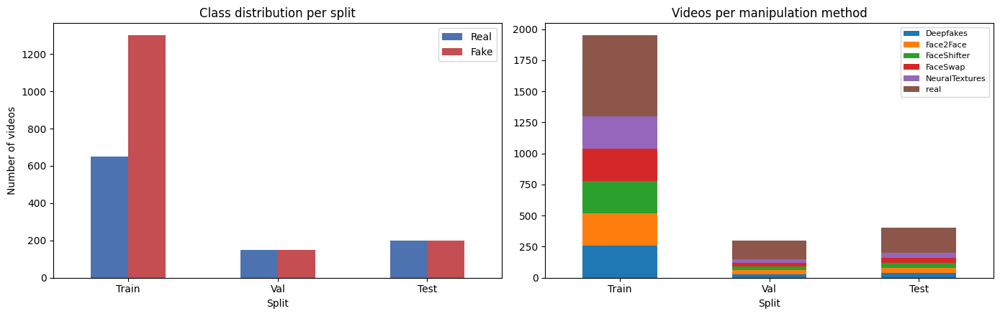


Face-detector statistics over 2650 videos with stored boxes: mean detection rate=0.98, median=1.00, videos below 50% detection=12, centre-crop fallbacks=5


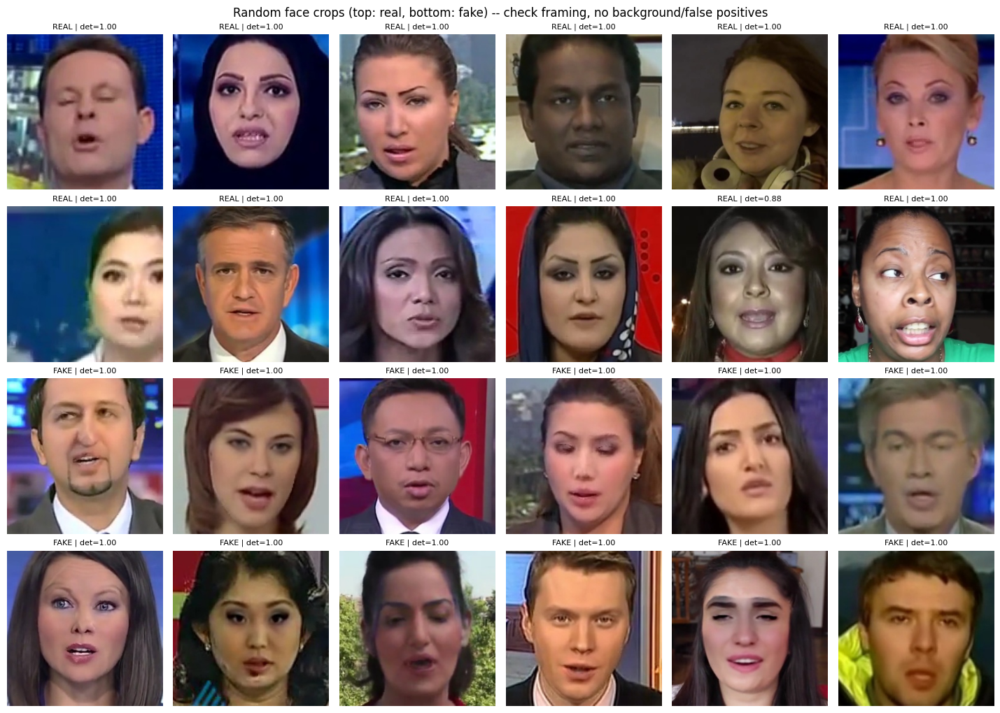

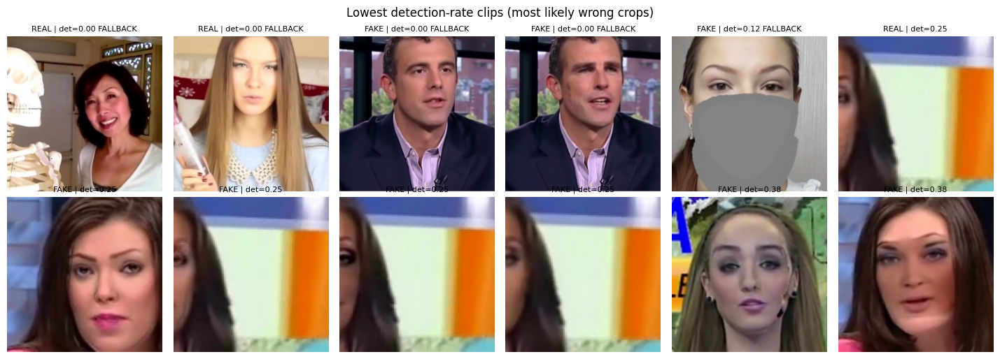

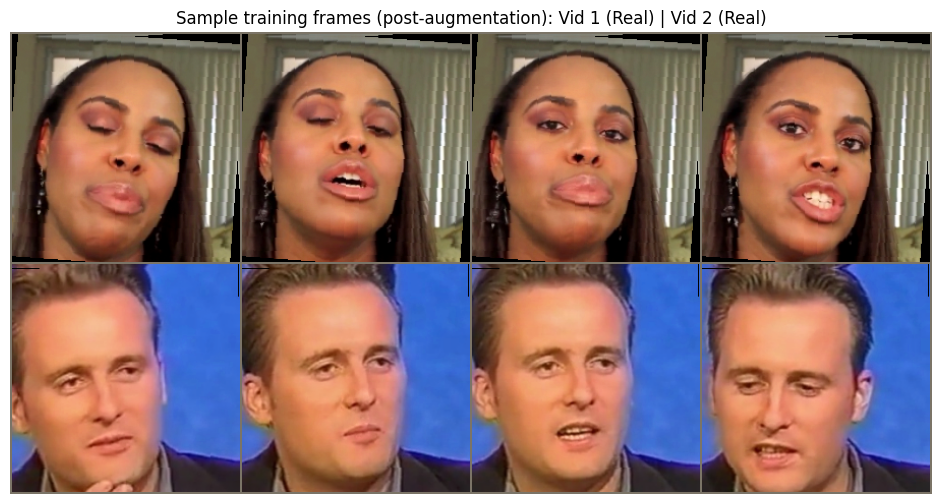


TIP (review item 8): after this run, 'Save Version' and add /kaggle/working/face_frames as a Kaggle dataset; set CONFIG['face_cache_input_dir'] to its path to skip extraction next time.


In [3]:
# ============================================================
# CELL 3: Data distribution analysis and face-crop QA (review item 8)
# ============================================================
# (The v4 sampler demo was removed: on balanced data it compared 0 all-fake batches with 0.)

split_counts = pd.DataFrame([
    {"Split": name,
     "Real": sum(1 for _, l in recs if l == 0),
     "Fake": sum(1 for _, l in recs if l == 1)}
    for name, recs in [("Train", train_records), ("Val", val_records), ("Test", test_records)]
])
print("Class distribution per split:")
print(split_counts.to_string(index=False))

method_rows = []
for name, recs in [("Train", train_records), ("Val", val_records), ("Test", test_records)]:
    cnt = pd.Series([record_info[f]["method"] for f, _ in recs]).value_counts()
    for m, c in cnt.items():
        method_rows.append({"Split": name, "Method": m, "Videos": int(c)})
method_df = pd.DataFrame(method_rows)
print("\nVideos per split and manipulation method:")
print(method_df.pivot(index="Method", columns="Split", values="Videos").fillna(0).astype(int).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
split_counts.set_index("Split")[["Real", "Fake"]].plot(kind="bar", ax=axes[0], color=["#4C72B0", "#C44E52"])
axes[0].set_title("Class distribution per split")
axes[0].set_ylabel("Number of videos")
axes[0].tick_params(axis="x", rotation=0)
method_df.pivot(index="Split", columns="Method", values="Videos").fillna(0).loc[["Train", "Val", "Test"]].plot(
    kind="bar", stacked=True, ax=axes[1])
axes[1].set_title("Videos per manipulation method")
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(OUT_DIR + "/class_distribution_by_split_and_method.png", dpi=150)
plt.show()

# ---- Face-crop quality: detection rates and a visual grid (inspect this before trusting any result) ----
def _box_info(folder):
    return FACE_BOXES.get(Path(folder).name)


infos = [(f, l, _box_info(f)) for f, l in extracted_records]
rates = [i["detect_rate"] for _, _, i in infos if i is not None]
n_fb = sum(1 for _, _, i in infos if i is not None and not i["ok"])
n_unknown = sum(1 for _, _, i in infos if i is None)
if rates:
    print(f"\nFace-detector statistics over {len(rates)} videos with stored boxes: "
          f"mean detection rate={np.mean(rates):.2f}, median={np.median(rates):.2f}, "
          f"videos below 50% detection={sum(r < 0.5 for r in rates)}, centre-crop fallbacks={n_fb}")
if n_unknown:
    print(f"({n_unknown} videos came from a cache without box metadata; they cannot be scored.)")


def _mid_frame(folder):
    files = sorted(Path(folder).glob("*.jpg"))
    return cv2.cvtColor(cv2.imread(str(files[len(files) // 2])), cv2.COLOR_BGR2RGB)


def show_crop_grid(items, title, path, ncols=6):
    nrows = int(math.ceil(len(items) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(2.4 * ncols, 2.6 * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis("off")
    for ax, (folder, label, info) in zip(axes, items):
        ax.imshow(_mid_frame(folder))
        rate = f"{info['detect_rate']:.2f}" if info else "n/a"
        ax.set_title(f"{'FAKE' if label else 'REAL'} | det={rate}" + ("" if (info is None or info['ok']) else " FALLBACK"),
                     fontsize=8)
    fig.suptitle(title, fontsize=12)
    plt.tight_layout()
    plt.savefig(path, dpi=130)
    plt.show()


_qa_rng = random.Random(0)
real_items = [x for x in infos if x[1] == 0]
fake_items = [x for x in infos if x[1] == 1]
qa_items = _qa_rng.sample(real_items, min(12, len(real_items))) + _qa_rng.sample(fake_items, min(12, len(fake_items)))
show_crop_grid(qa_items, "Random face crops (top: real, bottom: fake) -- check framing, no background/false positives",
               OUT_DIR + "/face_crop_qa_random.png")

scored = sorted([x for x in infos if x[2] is not None], key=lambda x: x[2]["detect_rate"])[:12]
if scored:
    show_crop_grid(scored, "Lowest detection-rate clips (most likely wrong crops)", OUT_DIR + "/face_crop_qa_worst.png")

# ---- Sample training frames (post-augmentation) ----
images, labels = next(iter(train_loader))
images_to_show = torch.cat([images[0, :4], images[1, :4]], dim=0)
grid = make_grid(images_to_show, nrow=4)
mean_t = torch.tensor(IMAGENET_MEAN, device=grid.device).view(3, 1, 1)
std_t = torch.tensor(IMAGENET_STD, device=grid.device).view(3, 1, 1)
grid_unnorm = torch.clamp(grid * std_t + mean_t, 0.0, 1.0)
label_mapping = {0: "Real", 1: "Fake"}
titles = f"Vid 1 ({label_mapping[int(labels[0].item())]}) | Vid 2 ({label_mapping[int(labels[1].item())]})"
plt.figure(figsize=(12, 6))
plt.imshow(grid_unnorm.permute(1, 2, 0).cpu().numpy())
plt.title(f"Sample training frames (post-augmentation): {titles}")
plt.axis("off")
plt.show()
print("\nTIP (review item 8): after this run, 'Save Version' and add /kaggle/working/face_frames as a Kaggle "
      "dataset; set CONFIG['face_cache_input_dir'] to its path to skip extraction next time.")

In [4]:
# ============================================================
# CELL 4: Model architecture (unchanged from v4-v7)
# ============================================================
# MAIN model: EfficientNet-B1 (pretrained, frame-level feature extractor) -> 1280 -> Linear
# projection -> 512 -> 2-layer UNIDIRECTIONAL LSTM (hidden=512) -> MEAN pooling -> classifier ->
# 1 logit. The attention-pooling path exists only as an optional switch and is NOT enabled.

class TemporalAttentionPooling(nn.Module):
    """Optional (ablation-only) alternative to mean pooling."""
    def __init__(self, input_dim):
        super().__init__()
        self.attn = nn.Sequential(
            nn.Linear(input_dim, input_dim // 2),
            nn.Tanh(),
            nn.Linear(input_dim // 2, 1),
        )

    def forward(self, x):
        scores = self.attn(x)
        weights = torch.softmax(scores, dim=1)
        pooled = torch.sum(weights * x, dim=1)
        return pooled, weights.squeeze(-1)


class FFPPDeepfakeDetectorV2(nn.Module):
    def __init__(self, lstm_hidden_size=None, num_layers=None, bidirectional=None,
                 dropout=None, use_attention=None):
        super().__init__()
        lstm_hidden_size = lstm_hidden_size or CONFIG["lstm_hidden_size"]
        num_layers = num_layers or CONFIG["lstm_num_layers"]
        bidirectional = CONFIG["lstm_bidirectional"] if bidirectional is None else bidirectional
        dropout = CONFIG["dropout"] if dropout is None else dropout
        use_attention = CONFIG["use_temporal_attention"] if use_attention is None else use_attention

        # ---- EfficientNet-B1 spatial feature extractor (pretrained, unchanged) ----
        weights = EfficientNet_B1_Weights.DEFAULT
        base_model = efficientnet_b1(weights=weights)
        self.feature_extractor = nn.Sequential(*list(base_model.children())[:-1])  # [stages, avgpool]
        self.feature_dim = 1280
        self.dropout_cnn = nn.Dropout(p=dropout)
        self.flatten = nn.Flatten()

        # ---- Projection: 1280 -> 512 ----
        self.projection = nn.Sequential(
            nn.Linear(self.feature_dim, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(p=dropout),
        )

        # ---- Temporal model: 2-layer UNIDIRECTIONAL LSTM by default ----
        self.bidirectional = bidirectional
        self.use_attention = use_attention
        self.lstm = nn.LSTM(
            input_size=512,
            hidden_size=lstm_hidden_size,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=bidirectional,
            dropout=(dropout if num_layers > 1 else 0.0),
        )
        lstm_out_dim = lstm_hidden_size * (2 if bidirectional else 1)

        self.temporal_pool = TemporalAttentionPooling(lstm_out_dim) if use_attention else None

        # ---- Classification head ----
        self.classifier = nn.Sequential(
            nn.Linear(lstm_out_dim, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(p=dropout),
            nn.Linear(256, 1),
        )

        self.last_attention_weights = None

    def forward(self, x, verbose_shape_check=False):
        batch_size, seq_len, c, h, w = x.shape
        assert (c, h, w) == (3, CONFIG["img_size"], CONFIG["img_size"]), (
            f"Expected input channels/H/W = (3,{CONFIG['img_size']},{CONFIG['img_size']}), got {(c, h, w)}"
        )
        if verbose_shape_check:
            print(f"  Input                    : {tuple(x.shape)}")

        x = x.view(batch_size * seq_len, c, h, w)
        if verbose_shape_check:
            print(f"  Reshaped for CNN         : {tuple(x.shape)}")

        features = self.feature_extractor(x)
        features = self.flatten(features)
        if verbose_shape_check:
            print(f"  EfficientNet-B1 output   : {tuple(features.shape)}")
        assert features.shape[1] == self.feature_dim, (
            f"Expected {self.feature_dim}-D EfficientNet-B1 features, got {features.shape[1]}"
        )

        features = self.dropout_cnn(features)
        features = self.projection(features)
        if verbose_shape_check:
            print(f"  After projection (->512) : {tuple(features.shape)}")
        assert features.shape[1] == 512, f"Expected 512-D projected features, got {features.shape[1]}"

        features = features.view(batch_size, seq_len, -1)
        if verbose_shape_check:
            print(f"  Reshaped for LSTM        : {tuple(features.shape)}")

        lstm_out, _ = self.lstm(features)
        if verbose_shape_check:
            print(f"  LSTM output              : {tuple(lstm_out.shape)}")

        if self.use_attention:
            pooled, attn_weights = self.temporal_pool(lstm_out)
            self.last_attention_weights = attn_weights.detach()
        else:
            pooled = torch.mean(lstm_out, dim=1)
            self.last_attention_weights = None
        if verbose_shape_check:
            print(f"  Pooled ({'attention' if self.use_attention else 'mean':<9}) : {tuple(pooled.shape)}")

        out = self.classifier(pooled)
        if verbose_shape_check:
            print(f"  Classifier output        : {tuple(out.shape)}")

        out = out.squeeze(1)
        if verbose_shape_check:
            print(f"  Final logits (per video) : {tuple(out.shape)}")
        return out

    def train(self, mode=True):
        """FIX: model.train() used to put the FROZEN backbone's BatchNorm layers in train
        mode, so their running stats drifted every batch while their weights stayed frozen.
        BN layers with no trainable params are now kept in eval mode."""
        super().train(mode)
        if mode:
            bn_eval = getattr(self, "bn_eval", False)      # set True during FGSM-AT -> ALL BN layers use running stats
            for m in self.feature_extractor.modules():
                if isinstance(m, nn.modules.batchnorm._BatchNorm) and \
                        (bn_eval or not any(p.requires_grad for p in m.parameters())):
                    m.eval()
        return self

    # ---- Staged transfer-learning helpers ----
    def freeze_backbone(self):
        for p in self.feature_extractor.parameters():
            p.requires_grad = False

    def unfreeze_last_n_blocks(self, n):
        backbone_blocks = list(self.feature_extractor[0].children())
        for block in backbone_blocks[-n:]:
            for p in block.parameters():
                p.requires_grad = True

    def backbone_param_groups(self, backbone_lr, head_lr):
        backbone_params = [p for p in self.feature_extractor.parameters() if p.requires_grad]
        head_params = (
            list(self.projection.parameters())
            + list(self.lstm.parameters())
            + (list(self.temporal_pool.parameters()) if self.use_attention else [])
            + list(self.classifier.parameters())
        )
        groups = [{"params": head_params, "lr": head_lr}]
        if backbone_params:
            groups.append({"params": backbone_params, "lr": backbone_lr})
        return groups


def build_model(**overrides):
    m = FFPPDeepfakeDetectorV2(**overrides).to(CONFIG["device"])
    m.freeze_backbone()  # backbone starts frozen; run_staged_training unfreezes the last N blocks
    return m


model = build_model()
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print("Model initialized:")
print(f"  EfficientNet-B1 -> projection(1280->512) -> "
      f"{'Bi' if CONFIG['lstm_bidirectional'] else ''}LSTM(hidden={CONFIG['lstm_hidden_size']}, "
      f"layers={CONFIG['lstm_num_layers']}, bidirectional={CONFIG['lstm_bidirectional']}) -> "
      f"{'attention' if CONFIG['use_temporal_attention'] else 'mean'} pooling -> classifier(256) -> 1 logit")
print(f"  Total params: {total_params:,} | Trainable (Phase 1, backbone frozen): {trainable_params:,}")

print("\nShape verification (dummy forward pass, batch_size=2):")
with torch.no_grad():
    dummy_input = torch.randn(2, CONFIG["seq_len"], 3, CONFIG["img_size"], CONFIG["img_size"],
                               device=CONFIG["device"])
    _ = model(dummy_input, verbose_shape_check=True)
print("Shape verification passed.")

Downloading: "https://download.pytorch.org/models/efficientnet_b1-c27df63c.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b1-c27df63c.pth


100%|██████████| 30.1M/30.1M [00:00<00:00, 232MB/s]


Model initialized:
  EfficientNet-B1 -> projection(1280->512) -> LSTM(hidden=512, layers=2, bidirectional=False) -> mean pooling -> classifier(256) -> 1 logit
  Total params: 11,503,137 | Trainable (Phase 1, backbone frozen): 4,989,953

Shape verification (dummy forward pass, batch_size=2):
  Input                    : (2, 16, 3, 224, 224)
  Reshaped for CNN         : (32, 3, 224, 224)
  EfficientNet-B1 output   : (32, 1280)
  After projection (->512) : (32, 512)
  Reshaped for LSTM        : (2, 16, 512)
  LSTM output              : (2, 16, 512)
  Pooled (mean     ) : (2, 512)
  Classifier output        : (2, 1)
  Final logits (per video) : (2,)
Shape verification passed.


In [5]:
# ============================================================
# CELL 5: FGSM attack library, prediction helpers and 12 automated unit tests
# ============================================================
# FGSM is the ONLY adversarial attack in this notebook (single gradient step, L-inf):
#       x_adv = clip_[0,1]( x + eps * sign( grad_x  BCEWithLogits(model(x), y) ) )
# Conventions (verified by the unit tests below):
#   * label 1 = FAKE = positive class; the model outputs ONE logit z, P(fake) = sigmoid(z).
#   * The loss is the plain BCE of the logit against the label that is being ATTACKED (true label for evaluation), so
#     ascending it pushes a fake towards z<0 and a real towards z>0.
#   * Tensors are [B,T,3,H,W] in ImageNet-NORMALISED space. eps is a PIXEL-scale (0..1) budget; it is converted per channel
#     with eps/std, and the result is clamped to the normalised image of [0,1]. Every frame of the video is perturbed.
#   * Attack mode: BatchNorm/Dropout in eval (frozen running statistics, deterministic). cuDNN's LSTM backward only exists in
#     train mode, so LSTM modules are switched to train() with dropout 0.0 for the gradient pass and restored afterwards.
#   * The gradient is taken with torch.autograd.grad w.r.t. the INPUT only: no parameter .grad is written, no graph is retained,
#     no optimizer/EMA is touched. The returned tensor is detached.
#   * The gradient does not depend on eps, so an epsilon sweep computes sign(grad) once per batch (`fgsm_sweep_logits`) --
#     mathematically identical to calling fgsm_attack once per epsilon (checked in the unit tests).

_MEAN = torch.tensor(IMAGENET_MEAN).view(1, 1, 3, 1, 1)
_STD = torch.tensor(IMAGENET_STD).view(1, 1, 3, 1, 1)
ATTACK_DIAG = {"samples": 0, "zero_grad_samples": 0, "nonfinite_grad_samples": 0}


def reset_attack_diag():
    for k in ATTACK_DIAG:
        ATTACK_DIAG[k] = 0


def _prepare_model_for_attack(model):
    prev = {m: m.training for m in model.modules()}
    model.eval()
    for m in model.modules():
        if isinstance(m, (nn.LSTM, nn.GRU, nn.RNN)):
            m.train()
            m._stored_dropout = m.dropout
            m.dropout = 0.0
    return prev


def _restore_model_modes(model, prev):
    for m in model.modules():
        if m in prev:
            m.train(prev[m])
        if isinstance(m, (nn.LSTM, nn.GRU, nn.RNN)) and hasattr(m, "_stored_dropout"):
            m.dropout = m._stored_dropout
            del m._stored_dropout


def _norm_bounds(device):
    mean, std = _MEAN.to(device), _STD.to(device)
    return (0.0 - mean) / std, (1.0 - mean) / std


def _eps_normalized(eps, device):
    if not torch.is_tensor(eps):
        eps = torch.tensor(float(eps))
    return eps.to(device).float() / _STD.to(device)


def fgsm_grad(model, videos, labels, use_amp=False, label_source="true"):
    """Input gradient of the summed BCE (the sum keeps fp16 gradients away from underflow; sign() is scale-free).
    label_source='pred' attacks the model's OWN hard prediction (no label information used); 'flipped' (audit only) uses 1-y.
    Returns (grad, clean_logits_float). Model modes are restored; parameters/BN/EMA are untouched."""
    prev = _prepare_model_for_attack(model)
    try:
        x = videos.detach().clone().requires_grad_(True)
        ctx = torch.amp.autocast("cuda") if (use_amp and videos.is_cuda) else nullcontext()
        with ctx:
            logits = model(x)
        logits = logits.float()
        if label_source == "pred":
            y = (logits.detach() > 0).float()
        elif label_source == "flipped":                      # audit only: ascend the loss of the WRONG label (a 'helpful' perturbation)
            y = 1.0 - labels.float()
        else:
            y = labels.float()
        loss = Fn.binary_cross_entropy_with_logits(logits, y, reduction="sum")
        if use_amp and videos.is_cuda:
            scale = 1024.0
            grad = torch.autograd.grad(loss * scale, x)[0] / scale
        else:
            grad = torch.autograd.grad(loss, x)[0]
    finally:
        _restore_model_modes(model, prev)
    finite = torch.isfinite(grad.flatten(1)).all(dim=1)
    ATTACK_DIAG["nonfinite_grad_samples"] += int((~finite).sum().item())
    grad = torch.nan_to_num(grad, nan=0.0, posinf=0.0, neginf=0.0)
    zero = (grad.flatten(1).abs().amax(dim=1) == 0)
    ATTACK_DIAG["samples"] += int(grad.size(0))
    ATTACK_DIAG["zero_grad_samples"] += int(zero.sum().item())
    return grad.detach(), logits.detach()


def fgsm_apply(x0, grad, eps):
    """x_adv = clamp(x0 + eps*sign(grad)); eps: float or tensor broadcastable to [B,1,1,1,1] (pixel scale)."""
    vmin, vmax = _norm_bounds(x0.device)
    eps_n = _eps_normalized(eps, x0.device)
    with torch.no_grad():
        x_adv = x0.detach() + eps_n * torch.sign(grad)
        x_adv = torch.max(torch.min(x_adv, vmax), vmin)
    return x_adv.detach()


def fgsm_attack(model, videos, labels, epsilon, use_amp=False, label_source="true", return_info=False):
    grad, logits = fgsm_grad(model, videos, labels, use_amp=use_amp, label_source=label_source)
    x_adv = fgsm_apply(videos, grad, epsilon)
    if return_info:
        return x_adv, {"grad": grad, "logits": logits}
    return x_adv


def gradient_alignment(model, videos, labels, eps, use_amp=False):
    """Catastrophic-overfitting heuristic: mean cosine similarity between the input gradients at two INDEPENDENT random
    points of the eps-ball. Close to 1 = locally linear loss (FGSM is a good attack); close to 0 = FGSM is unreliable."""
    vmin, vmax = _norm_bounds(videos.device)
    eps_n = _eps_normalized(eps, videos.device)
    gs = []
    for _ in range(2):
        noise = (torch.rand_like(videos) * 2 - 1) * eps_n
        xr = torch.max(torch.min(videos + noise, vmax), vmin)
        g, _ = fgsm_grad(model, xr, labels, use_amp=use_amp)
        gs.append(g.flatten(1))
    return float(Fn.cosine_similarity(gs[0], gs[1], dim=1, eps=1e-12).mean().item())


# ---- Prediction helpers (shared by every later cell) ----
def get_logits(model, loader, attack_fn=None, use_amp=None, desc="Evaluating"):
    """(labels, raw logits) in loader order. attack_fn(model, videos, labels)->adv_videos or None. fp32 by default."""
    use_amp = CONFIG["eval_use_amp"] if use_amp is None else use_amp
    model.eval()
    all_logits, all_labels = [], []
    for videos, labels in tqdm(loader, desc=desc, leave=False):
        videos = videos.to(CONFIG["device"], non_blocking=True)
        labels_dev = labels.to(CONFIG["device"], non_blocking=True)
        if attack_fn is not None:
            videos = attack_fn(model, videos, labels_dev)
        with torch.no_grad():
            ctx = torch.amp.autocast("cuda") if (use_amp and CONFIG["device"].type == "cuda") else nullcontext()
            with ctx:
                logits = model(videos)
        all_logits.append(logits.float().cpu().numpy())
        all_labels.append(labels.numpy())
    return np.concatenate(all_labels).astype(int), np.concatenate(all_logits)


def fgsm_sweep_logits(model, loader, eps_list, label_source="true", desc="FGSM sweep"):
    """Clean logits and FGSM logits for EVERY epsilon in `eps_list` (pixel scale) in one pass over `loader`.
    Returns labels, {eps: logits}; eps=0 is the clean forward pass. Same videos / same order for any model."""
    model.eval()
    labels_all, out = [], {float(e): [] for e in eps_list}
    for videos, labels in tqdm(loader, desc=desc, leave=False):
        videos = videos.to(CONFIG["device"], non_blocking=True)
        labels_dev = labels.to(CONFIG["device"], non_blocking=True)
        grad = None
        for e in eps_list:
            if e == 0:
                x = videos
            else:
                if grad is None:
                    grad, _ = fgsm_grad(model, videos, labels_dev, use_amp=False, label_source=label_source)
                x = fgsm_apply(videos, grad, e)
            with torch.no_grad():
                out[float(e)].append(model(x).float().cpu().numpy())
        labels_all.append(labels.numpy())
    return np.concatenate(labels_all).astype(int), {e: np.concatenate(v) for e, v in out.items()}


def quantize_to_8bit(x_norm):
    """Round a normalised video to the 8-bit pixel grid (what a saved/re-decoded image could actually contain)."""
    mean, std = _MEAN.to(x_norm.device), _STD.to(x_norm.device)
    pix = torch.round((x_norm * std + mean).clamp(0, 1) * 255.0) / 255.0
    return (pix - mean) / std


# ============================================================
# UNIT TESTS (all must pass before any training)
# ============================================================
def _valid_batch(B=3, T=4, seed=0, lo=0.05, hi=0.95):
    g = torch.Generator().manual_seed(seed)
    pix = lo + (hi - lo) * torch.rand(B, T, 3, CONFIG["img_size"], CONFIG["img_size"], generator=g)
    return ((pix - _MEAN) / _STD).to(CONFIG["device"]), torch.tensor([0, 1, 0][:B] + [1] * max(0, B - 3)).to(CONFIG["device"])


def _pix(x):               # normalised -> pixel scale
    return x * _STD.to(x.device) + _MEAN.to(x.device)


def run_fgsm_unit_tests(model):
    results = []
    dev = CONFIG["device"]

    def record(name, ok, detail=""):
        results.append((name, bool(ok), detail))
        print(f"  [{'PASS' if ok else 'FAIL'}] {name}  {detail}")

    was_training = model.training
    x, y = _valid_batch()
    model.train()                                  # tests also prove the attack handles / restores a model left in train mode
    n_params0 = {k: v.detach().clone() for k, v in model.state_dict().items()}

    # 1. epsilon = 0 -> identity
    xa = fgsm_attack(model, x, y, 0.0)
    record("1. eps=0 returns the input unchanged", torch.equal(xa, x), f"max|diff|={float((xa - x).abs().max()):.2e}")

    # 2. L-inf bound (pixel space)
    worst = 0.0
    for e in [0.25, 1, 4, 16]:
        xa = fgsm_attack(model, x, y, e / 255)
        worst = max(worst, float((_pix(xa) - _pix(x)).abs().max()) * 255 - e)
    record("2. L-inf perturbation <= eps (pixel space)", worst <= 1e-3, f"max excess over eps = {worst:.2e}/255")

    # 3. valid pixel range, including inputs sitting exactly on 0 and 1
    xe, _ = _valid_batch(lo=0.0, hi=1.0)
    xe[:, :, :, :8, :8] = ((0.0 - _MEAN) / _STD).to(dev)
    xe[:, :, :, -8:, -8:] = ((1.0 - _MEAN) / _STD).to(dev)
    xa = fgsm_attack(model, xe, y, 16 / 255)
    pa = _pix(xa)
    record("3. adversarial pixels stay in [0,1]", float(pa.min()) >= -1e-5 and float(pa.max()) <= 1 + 1e-5,
           f"range=[{float(pa.min()):.5f}, {float(pa.max()):.5f}]")

    # 4. perturbation is non-zero (and exactly eps) wherever the gradient is non-zero and not clipped
    eps4 = 2 / 255
    xa, info = fgsm_attack(model, x, y, eps4, return_info=True)
    d = (_pix(xa) - _pix(x)).abs()
    interior = (_pix(x) > eps4 + 1e-4) & (_pix(x) < 1 - eps4 - 1e-4)
    mask = (info["grad"].abs() > 0) & interior
    frac_nonzero_grad = float((info["grad"].abs() > 0).float().mean())
    ok4 = mask.any() and bool((torch.abs(d[mask] - eps4) < 1e-5).all())
    record("4. non-zero perturbation (= eps) wherever grad != 0", ok4, f"fraction of pixels with non-zero grad = {frac_nonzero_grad:.3f}")

    # 5. finite gradients, zero-gradient samples counted
    reset_attack_diag()
    _, info = fgsm_attack(model, x, y, 1 / 255, return_info=True)
    ok5 = bool(torch.isfinite(info["grad"]).all()) and ATTACK_DIAG["zero_grad_samples"] == 0 and ATTACK_DIAG["nonfinite_grad_samples"] == 0
    record("5. gradients finite; zero-gradient samples = 0", ok5,
           f"zero-grad {ATTACK_DIAG['zero_grad_samples']}/{ATTACK_DIAG['samples']}, non-finite {ATTACK_DIAG['nonfinite_grad_samples']}")

    # 6. deterministic evaluation (clean forward exactly; attack sign pattern up to cuDNN LSTM-backward non-determinism)
    model.eval()
    with torch.no_grad():
        z1, z2 = model(x).float(), model(x).float()
    a1, a2 = fgsm_attack(model, x, y, 2 / 255), fgsm_attack(model, x, y, 2 / 255)
    agree = float((a1 == a2).float().mean())
    record("6. deterministic evaluation", torch.equal(z1, z2) and agree >= 0.99, f"clean logits identical={torch.equal(z1, z2)}, adversarial pixel agreement={agree:.5f}")

    # 7/8. parameters and BatchNorm statistics unchanged; module modes restored; no parameter gradients written
    model.train()
    sd_before = {k: v.detach().clone() for k, v in model.state_dict().items()}
    modes_before = {m: m.training for m in model.modules()}
    model.zero_grad(set_to_none=True)
    _ = fgsm_attack(model, x, y, 4 / 255)
    sd_after = model.state_dict()
    params_same = all(torch.equal(sd_before[k], sd_after[k]) for k, v in sd_before.items()
                      if k in dict(model.named_parameters()))
    buffers_same = all(torch.equal(sd_before[k], sd_after[k]) for k in sd_before if k not in dict(model.named_parameters()))
    grads_clean = all(p.grad is None for p in model.parameters())
    modes_same = all(m.training == modes_before[m] for m in model.modules())
    record("7. model parameters unchanged (and no .grad written)", params_same and grads_clean, f"params identical={params_same}, grads None={grads_clean}")
    record("8. BatchNorm running stats / counters unchanged; modes restored", buffers_same and modes_same,
           f"buffers identical={buffers_same}, training flags restored={modes_same}")

    # 9. temporal dimension: any number of frames, every frame perturbed, shape preserved
    ok9, det9 = True, []
    for T in (2, 6):
        xt, yt = _valid_batch(B=2, T=T, seed=T)
        xa = fgsm_attack(model, xt, yt[:2], 2 / 255)
        per_frame = (xa - xt).abs().flatten(2).amax(dim=2)          # [B,T]
        ok9 &= (xa.shape == xt.shape) and bool((per_frame > 0).all())
        det9.append(f"T={T}: shape ok, min per-frame |delta|={float(per_frame.min()):.3e}")
    record("9. temporal dimension preserved, every frame perturbed", ok9, "; ".join(det9))

    # 10. last incomplete batch (5 videos, batch size 4 -> batches of 4 and 1)
    model.eval()
    xs, ys = _valid_batch(B=5, T=2, seed=7)
    ys = torch.tensor([0, 1, 0, 1, 1])
    loader = DataLoader(torch.utils.data.TensorDataset(xs.cpu(), ys), batch_size=4, shuffle=False)
    sizes, outs = [], []
    for xb, yb in loader:
        sizes.append(len(xb))
        outs.append(fgsm_attack(model, xb.to(dev), yb.to(dev), 2 / 255).cpu())
    whole = fgsm_attack(model, xs, ys.to(dev), 2 / 255).cpu()
    cat = torch.cat(outs)
    record("10. last incomplete batch handled (4+1), same result as one batch of 5", sizes == [4, 1] and cat.shape == whole.shape and float((cat == whole).float().mean()) >= 0.99,
           f"batch sizes={sizes}, agreement={float((cat == whole).float().mean()):.5f}")

    # 11. direction + label convention: margin (1-2y)*logit must increase, the BCE must increase.
    #     Run on a tiny deterministic LINEAR probe (logit = scaled mean of w*x) so the test is guaranteed to be sensitive to the input: a freshly
    #     initialised head (logits ~ 0) or a random-init backbone cannot hide a sign error in float noise. The backbone model is tested
    #     for the same property below as an INFORMATION line only (it can legitimately be insensitive before training).
    class _LinearProbe(nn.Module):
        def __init__(self):
            super().__init__()
            g = torch.Generator().manual_seed(11)
            self.w = nn.Parameter(torch.randn(1, 1, 3, CONFIG["img_size"], CONFIG["img_size"], generator=g))
        def forward(self, x):
            return 400.0 * (x * self.w).mean(dim=(1, 2, 3, 4))
    probe = _LinearProbe().to(dev).eval()
    xb, yb = _valid_batch(B=4, T=4, seed=3)
    yb = torch.tensor([0, 1, 0, 1]).to(dev)
    with torch.no_grad():
        z0 = probe(xb).float()
    xa = fgsm_attack(probe, xb, yb, 2 / 255)
    with torch.no_grad():
        z1 = probe(xa).float()
    yf = yb.float()
    l0 = Fn.binary_cross_entropy_with_logits(z0, yf).item()
    l1 = Fn.binary_cross_entropy_with_logits(z1, yf).item()
    dm = ((1 - 2 * yf) * (z1 - z0))
    record("11. FGSM ascends the loss (fake -> lower logit, real -> higher logit)", l1 > l0 and bool((dm > 0).all()),
           f"BCE {l0:.4f}->{l1:.4f}; margin change per sample={[round(float(v), 4) for v in dm]}")
    del probe
    xb2, yb2 = _valid_batch(B=3, T=4, seed=3)
    xb2a = fgsm_attack(model, xb2, yb2, 8 / 255)          # (needs autograd: attack OUTSIDE no_grad)
    with torch.no_grad():
        zb0 = model(xb2).float()
        zb1 = model(xb2a).float()
    print(f"  [INFO] backbone model, same direction check at 8/255: margin change {[round(float(v), 4) for v in (1 - 2 * yb2.float()) * (zb1 - zb0)]} "
          f"(~0 is normal for an untrained head; the linear probe above is the binding test)")

    # 12. no retained graph, and sweep == per-epsilon attack
    xa = fgsm_attack(model, x, y, 2 / 255)
    g, _ = fgsm_grad(model, x, y)
    same = torch.equal(fgsm_apply(x, g, 2 / 255), xa) or float((fgsm_apply(x, g, 2 / 255) == xa).float().mean()) >= 0.99
    record("12. output detached (no graph); sweep path == single-eps attack", (not xa.requires_grad) and xa.grad_fn is None and same,
           f"requires_grad={xa.requires_grad}, grad_fn={xa.grad_fn}")

    model.train(was_training)
    failed = [n for n, ok, _ in results if not ok]
    print(f"\nFGSM unit tests: {len(results) - len(failed)}/{len(results)} passed.")
    assert not failed, f"FGSM unit tests FAILED: {failed}"
    return results


print("FGSM library ready (fgsm_grad / fgsm_apply / fgsm_attack / gradient_alignment / fgsm_sweep_logits).")
print("Running the automated FGSM unit tests on the freshly built model (before any training):")
UNIT_TEST_RESULTS = run_fgsm_unit_tests(model)
atomic_json_save([{"test": n, "passed": ok, "detail": d} for n, ok, d in UNIT_TEST_RESULTS], os.path.join(OUT_DIR, "fgsm_unit_tests.json"))

FGSM library ready (fgsm_grad / fgsm_apply / fgsm_attack / gradient_alignment / fgsm_sweep_logits).
Running the automated FGSM unit tests on the freshly built model (before any training):
  [PASS] 1. eps=0 returns the input unchanged  max|diff|=0.00e+00
  [PASS] 2. L-inf perturbation <= eps (pixel space)  max excess over eps = 2.94e-05/255
  [PASS] 3. adversarial pixels stay in [0,1]  range=[0.00000, 1.00000]
  [PASS] 4. non-zero perturbation (= eps) wherever grad != 0  fraction of pixels with non-zero grad = 1.000
  [PASS] 5. gradients finite; zero-gradient samples = 0  zero-grad 0/3, non-finite 0
  [PASS] 6. deterministic evaluation  clean logits identical=True, adversarial pixel agreement=1.00000
  [PASS] 7. model parameters unchanged (and no .grad written)  params identical=True, grads None=True
  [PASS] 8. BatchNorm running stats / counters unchanged; modes restored  buffers identical=True, training flags restored=True
  [PASS] 9. temporal dimension preserved, every frame perturbe

In [6]:
# ============================================================
# CELL 6: Training machinery (clean control + FGSM adversarial training), resumable, with stability guards (v9)
# ============================================================
# One shared train_epoch / run_fit is used for BOTH models so the control and the FGSM-trained model differ ONLY in the
# adversarial component. Design decisions (all documented here, all logged per epoch):
#   * Batch composition: `adv_ratio` of every batch is replaced by its FGSM version, the rest stays clean (configurable;
#     0.5 = half clean / half adversarial). The perturbed samples keep their TRUE labels as targets.
#   * Label leakage: (a) the perturbation is crafted from the TRUE label only when adv_label_source == "true" (standard
#     Goodfellow-style FGSM-AT); "pred" crafts it from the model's own prediction so no label information reaches the
#     perturbation. (b) Cell 15 measures the leaking signature directly (FGSM accuracy above clean accuracy; true-label vs
#     pred-label FGSM; transfer attack). (c) Test labels are never used for any decision (GuardedLoader).
#   * BatchNorm: all BN layers use their (frozen) running statistics during FGSM-AT (model.bn_eval=True). The attack, the
#     clean half and the adversarial half therefore see exactly the same network and the BN statistics cannot drift towards
#     adversarial inputs. The clean-trained control keeps the v6/v7 behaviour (only unfrozen BN layers update).
#   * EMA: the averaged weights are what is validated / saved / evaluated; the attack always runs on the LIVE model during
#     training and on the evaluated model at test time. verify_ema() checks finiteness and that EMA != live after training.
#   * Numerical safety (v9): a non-finite fp16 loss is first RE-COMPUTED in fp32 on the same batch (v8 simply skipped 3 steps and could not say
#     why); only if fp32 is non-finite too is the step skipped. Every event is logged (max |logit|, which part was non-finite, input finite?).
#     10 consecutive skips abort. GradScaler overflow skips are detected and the LR scheduler is NOT advanced for a skipped optimizer step.
#   * Gradient clipping (v9): AdamW is invariant to a UNIFORM rescaling of the gradient, so v8's fixed clip at 1.0 (66-76% of steps clipped, mean
#     norm 5-7) did almost nothing useful. "adaptive" clipping clips only spikes (> mult x running mean norm); rate and threshold are logged.
#   * Anti-hedging (v9): adversarial logit pairing Huber(z_adv, stopgrad(z_clean)) + eps ramp + adversarial-ratio ramp + lower LR + EMA 0.995.
#   * Early stopping (v9): never before `early_stop_min_epochs`, and only if the gates failed several epochs in a row AND the raw score is not rising.

criterion = nn.BCEWithLogitsLoss()          # plain BCE: validation, attacks and the FGSM-AT losses


class SmoothBCEWithLogits(nn.Module):
    def __init__(self, smoothing=0.0):
        super().__init__()
        self.smoothing = smoothing

    def forward(self, logits, targets):
        t = targets * (1.0 - self.smoothing) + 0.5 * self.smoothing
        return Fn.binary_cross_entropy_with_logits(logits, t)


train_criterion = SmoothBCEWithLogits(CONFIG["label_smoothing"])
train_labels_arr = np.array([r[1] for r in train_records])
print(f"Train label distribution -> real={int((train_labels_arr == 0).sum())}, fake={int((train_labels_arr == 1).sum())}")


class ModelEMA:
    """Exponential moving average of weights and BN statistics; `module` is what gets validated / checkpointed / evaluated."""
    def __init__(self, model, decay):
        self.module = copy.deepcopy(model).eval()
        self.module.lstm.flatten_parameters()
        self.decay = decay
        self.n = 0

    @torch.no_grad()
    def update(self, model):
        self.n += 1
        d = min(self.decay, (1.0 + self.n) / (10.0 + self.n))
        msd = model.state_dict()
        for k, v in self.module.state_dict().items():
            if v.dtype.is_floating_point:
                v.mul_(d).add_(msd[k].detach(), alpha=1.0 - d)
            else:
                v.copy_(msd[k])


@torch.no_grad()
def verify_ema(ema, model):
    """EMA sanity: all finite; after >1 update it differs from the live weights (otherwise it is not averaging)."""
    finite = all(torch.isfinite(v).all().item() for v in ema.module.state_dict().values() if v.dtype.is_floating_point)
    live = model.state_dict()
    dist = max(float((v - live[k]).abs().max()) for k, v in ema.module.state_dict().items()
               if v.dtype.is_floating_point and v.numel() > 1)
    return {"ema_finite": bool(finite), "ema_max_abs_diff_to_live": dist, "ema_updates": ema.n,
            "ema_differs_from_live": bool(dist > 0 or ema.n <= 1)}


def build_optimizer(model, lr_scale=1.0):
    groups = model.backbone_param_groups(backbone_lr=CONFIG["backbone_lr"] * lr_scale, head_lr=CONFIG["head_lr"] * lr_scale)
    return torch.optim.AdamW(groups, lr=CONFIG["head_lr"] * lr_scale, weight_decay=CONFIG["weight_decay"])


def build_scheduler(optimizer, total_steps, warmup_steps=0, min_ratio=0.02):
    """PER-STEP linear warm-up then cosine decay to min_ratio x peak. Stepped AFTER optimizer.step() and only when the
    optimizer actually stepped."""
    total_steps = max(int(total_steps), 1)
    warmup_steps = int(warmup_steps)

    def lr_lambda(step):
        if warmup_steps > 0 and step < warmup_steps:
            return max(1e-3, (step + 1) / warmup_steps)
        p = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        return min_ratio + (1.0 - min_ratio) * 0.5 * (1.0 + math.cos(math.pi * min(p, 1.0)))

    return torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)


def config_snapshot():
    return {k: (str(v) if isinstance(v, (torch.device, Path)) else v) for k, v in CONFIG.items()}


def make_meta(kind, extra=None):
    m = {"kind": kind, "split_fingerprint": SPLIT_FINGERPRINT, "arch_fingerprint": ARCH_FINGERPRINT,
         "torch": torch.__version__, "seed": CONFIG["seed"], "config": config_snapshot()}
    m.update(extra or {})
    return m


def check_provenance(ckpt, kind):
    """Reuse of a checkpoint is allowed ONLY if it was trained on this exact split and architecture."""
    meta = ckpt.get("meta")
    if meta is None:
        return False, "checkpoint has no provenance metadata (legacy file)"
    if meta.get("kind") != kind:
        return False, f"checkpoint kind is {meta.get('kind')!r}, expected {kind!r}"
    if meta.get("split_fingerprint") != SPLIT_FINGERPRINT:
        return False, f"split fingerprint {meta.get('split_fingerprint')} != current {SPLIT_FINGERPRINT}"
    if meta.get("arch_fingerprint") != ARCH_FINGERPRINT:
        return False, f"architecture fingerprint {meta.get('arch_fingerprint')} != current {ARCH_FINGERPRINT}"
    return True, "ok"


def _clip_gradients(params, cfg, state):
    """Global-norm clipping. fixed: clip at cfg['norm'].  adaptive: clip at max(norm_floor, mult x running mean of the clipped norm), i.e. only
    genuine spikes are clipped. Returns (total norm before clipping, threshold used).
    Why: AdamW's update size is invariant to a UNIFORM rescaling of the gradient, so clipping every step (v8: 66-76% of steps clipped at 1.0
    while the mean norm was 5-7) changes nothing except the relative weight of steps; its only useful job is to stop single spikes from
    poisoning Adam's second-moment estimate. Adaptive clipping does exactly that and its rate is logged."""
    if cfg is None:
        return torch.nn.utils.clip_grad_norm_(params, 1e9), float("inf")
    if cfg["mode"] == "fixed":
        thr = cfg["norm"]
    else:
        ema = state.get("clip_ema")
        thr = max(cfg["norm"], cfg["mult"] * ema) if ema is not None else 1e9
    gn = torch.nn.utils.clip_grad_norm_(params, thr)
    if cfg["mode"] != "fixed" and torch.isfinite(gn):
        g = float(min(gn, thr))
        state["clip_ema"] = g if state.get("clip_ema") is None else 0.98 * state["clip_ema"] + 0.02 * g
    return gn, thr


def train_epoch(model, loader, optimizer, scaler, use_amp, scheduler, ema, adv_cfg=None, grad_clip_cfg=None,
                max_steps=None, desc="Training", step_state=None):
    """One epoch (optionally capped at `max_steps` batches). adv_cfg=None -> clean training (label-smoothed BCE).
    adv_cfg -> FGSM adversarial training: the first n_adv videos of every batch are replaced by their FGSM version (eps ramped, optional
    per-sample random eps), the rest stays clean; every video is used exactly once per step.
    loss = clean_w*BCE(clean part) + adv_w*BCE(adversarial part) + alp_w*Huber(z_adv, stopgrad(z_clean of the same video))."""
    model.train()
    step_state = step_state if step_state is not None else {"step": 0}
    S = dict(loss=0.0, clean_loss=0.0, adv_loss=0.0, alp=0.0, n=0, n_adv=0, n_clean=0, correct_clean=0, correct_adv=0,
             grad_norm=0.0, clipped=0, stepped=0, nan_skips=0, fp32_retries=0, clip_thr=0.0, thr_n=0, eps_t=0.0, ratio_t=0.0)
    nan_events, ga_vals, consecutive_bad = [], [], 0
    reset_attack_diag()
    n_batches = min(len(loader), max_steps) if max_steps else len(loader)
    t0 = time.time()
    attack_amp = bool(adv_cfg.get("attack_amp", use_amp)) and use_amp if adv_cfg else False

    for bi, (videos, labels) in enumerate(tqdm(loader, desc=desc, leave=False, total=n_batches)):
        if max_steps and bi >= max_steps:
            break
        videos = videos.to(CONFIG["device"], non_blocking=True)
        labels = labels.to(CONFIG["device"], non_blocking=True)
        bs = videos.size(0)
        yf = labels.float()
        n_adv, z_ref = 0, None
        if adv_cfg is not None:
            st = step_state["step"]
            ratio_t = adv_cfg["ratio_start"] + (adv_cfg["ratio_end"] - adv_cfg["ratio_start"]) * min(1.0, st / max(1, adv_cfg["ratio_ramp_steps"]))
            n_adv = int(round(ratio_t * bs))
            if ratio_t > 0:
                n_adv = max(1, n_adv)
            eps_t = adv_cfg["eps"] * min(1.0, (st + 1) / max(1, adv_cfg["ramp_steps"]))
            S["eps_t"], S["ratio_t"] = eps_t, ratio_t
            eps_arg = eps_t
            if adv_cfg.get("random_eps") and n_adv > 0:
                eps_arg = (eps_t * torch.rand(n_adv, device=videos.device)).view(-1, 1, 1, 1, 1)
        step_state["step"] += 1

        if n_adv > 0:
            adv, info = fgsm_attack(model, videos[:n_adv], labels[:n_adv], eps_arg, use_amp=attack_amp,
                                    label_source=adv_cfg["label_source"], return_info=True)
            z_ref = info["logits"].float()                     # clean logits of the attacked videos (attack mode, no grad)
            if adv_cfg.get("ga_every") and step_state["step"] % adv_cfg["ga_every"] == 0:
                ga_vals.append(gradient_alignment(model, videos[:n_adv], labels[:n_adv], eps_t, use_amp=attack_amp))
            model.train()
            inp = torch.cat([videos[n_adv:], adv], dim=0)          # [clean part ; adversarial part]
        else:
            inp = videos
        n_clean = bs - n_adv

        def compute_losses(lg):
            if adv_cfg is None:
                c = train_criterion(lg, yf)
                zero = torch.zeros((), device=lg.device)
                return c, c, zero, zero
            cl = criterion(lg[:n_clean], yf[n_adv:]) if n_clean > 0 else torch.zeros((), device=lg.device)
            al = criterion(lg[n_clean:], yf[:n_adv]) if n_adv > 0 else torch.zeros((), device=lg.device)
            alp = (Fn.huber_loss(lg[n_clean:], z_ref, delta=adv_cfg["alp_delta"]) if (n_adv > 0 and adv_cfg["alp_w"] > 0)
                   else torch.zeros((), device=lg.device))
            if n_clean > 0 and n_adv > 0:
                tot = adv_cfg["clean_w"] * cl + adv_cfg["adv_w"] * al + adv_cfg["alp_w"] * alp
            else:
                tot = (cl if n_adv == 0 else al + adv_cfg["alp_w"] * alp)
            return tot, cl, al, alp

        optimizer.zero_grad(set_to_none=True)
        ctx = torch.amp.autocast("cuda") if use_amp else nullcontext()
        with ctx:
            logits = model(inp)
        logits = logits.float()
        loss, clean_loss, adv_loss, alp_loss = compute_losses(logits)
        amp_step = use_amp

        if not torch.isfinite(loss):
            ev = {"step": step_state["step"], "n_adv": n_adv, "max_abs_logit": float(torch.nan_to_num(logits.detach(), nan=1e9).abs().max()),
                  "nonfinite_logits": int((~torch.isfinite(logits)).sum()), "input_nonfinite": bool(not torch.isfinite(inp).all()),
                  "clean_part_finite": bool(torch.isfinite(clean_loss)), "adv_part_finite": bool(torch.isfinite(adv_loss)),
                  "amp": bool(use_amp), "fp32_retry_finite": None}
            if CONFIG["nan_fp32_retry"] and use_amp:        # was it an fp16 overflow? re-compute this very batch in fp32
                logits32 = model(inp).float()
                loss32, c32, a32, p32 = compute_losses(logits32)
                ev["fp32_retry_finite"] = bool(torch.isfinite(loss32))
                if torch.isfinite(loss32):
                    logits, loss, clean_loss, adv_loss, alp_loss, amp_step = logits32, loss32, c32, a32, p32, False
                    S["fp32_retries"] += 1
            if len(nan_events) < 20:
                nan_events.append(ev)
            if not torch.isfinite(loss):
                S["nan_skips"] += 1
                consecutive_bad += 1
                optimizer.zero_grad(set_to_none=True)
                if consecutive_bad >= 10:
                    raise FloatingPointError("10 consecutive non-finite losses -- training aborted (see nan_events in the log).")
                continue
        consecutive_bad = 0

        params = [p for p in model.parameters() if p.requires_grad]
        stepped = True
        if amp_step:
            scale_before = scaler.get_scale()
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            gn, thr = _clip_gradients(params, grad_clip_cfg, step_state)
            scaler.step(optimizer)
            scaler.update()
            stepped = scaler.get_scale() >= scale_before            # a lowered scale means the step was skipped (inf/nan grads)
        else:
            loss.backward()
            gn, thr = _clip_gradients(params, grad_clip_cfg, step_state)
            if torch.isfinite(gn):
                optimizer.step()
            else:
                stepped = False
        if stepped:
            S["stepped"] += 1
            if scheduler is not None:
                scheduler.step()                                    # AFTER optimizer.step()
            if ema is not None:
                ema.update(model)
        gnf = float(gn) if torch.isfinite(gn) else float("nan")
        if gnf == gnf:
            S["grad_norm"] += gnf
            if thr < 1e6:                                   # the first steps have no running mean yet (no clipping): not averaged
                S["clip_thr"] += thr; S["thr_n"] += 1
            S["clipped"] += int(gnf > thr)

        with torch.no_grad():
            pred = (logits > 0).long()
            S["n"] += bs; S["n_adv"] += n_adv; S["n_clean"] += n_clean
            S["loss"] += float(loss) * bs
            S["clean_loss"] += float(clean_loss) * max(n_clean, 0)
            S["adv_loss"] += float(adv_loss) * n_adv
            S["alp"] += float(alp_loss) * n_adv
            if adv_cfg is None:
                S["correct_clean"] += int((pred == labels).sum())
            else:
                S["correct_clean"] += int((pred[:n_clean] == labels[n_adv:]).sum())
                S["correct_adv"] += int((pred[n_clean:] == labels[:n_adv]).sum())
        del logits, loss, inp
        if (bi + 1) % 25 == 0:
            free_cuda_memory()

    n_steps = max(S["stepped"], 1)
    m = {"loss": S["loss"] / max(S["n"], 1), "clean_loss": S["clean_loss"] / max(S["n_clean"], 1),
         "acc": S["correct_clean"] / max(S["n_clean"], 1), "grad_norm": S["grad_norm"] / n_steps,
         "clip_rate": S["clipped"] / n_steps, "clip_thr": S["clip_thr"] / max(S["thr_n"], 1), "nan_skips": S["nan_skips"],
         "fp32_retries": S["fp32_retries"], "optimizer_steps": S["stepped"], "seconds": time.time() - t0,
         "zero_grad_samples": ATTACK_DIAG["zero_grad_samples"], "attacked_samples": ATTACK_DIAG["samples"],
         "nan_events": nan_events}
    if adv_cfg is not None:
        m.update({"adv_loss": S["adv_loss"] / max(S["n_adv"], 1), "alp_loss": S["alp"] / max(S["n_adv"], 1),
                  "adv_acc": S["correct_adv"] / max(S["n_adv"], 1), "eps_t_255": S["eps_t"] * 255, "ratio_t": S["ratio_t"],
                  "grad_align": float(np.mean(ga_vals)) if ga_vals else float("nan")})
    return m


def validate_epoch(model, loader, loss_fn, threshold=0.5, use_amp=False):
    model.eval()
    probs, labs, run, n = [], [], 0.0, 0
    with torch.no_grad():
        for videos, labels in tqdm(loader, desc="Validating", leave=False):
            videos = videos.to(CONFIG["device"], non_blocking=True)
            labels = labels.to(CONFIG["device"], non_blocking=True)
            ctx = torch.amp.autocast("cuda") if (use_amp and CONFIG["device"].type == "cuda") else nullcontext()
            with ctx:
                z = model(videos)
            run += float(loss_fn(z.float(), labels.float())) * videos.size(0)
            n += videos.size(0)
            probs.extend(torch.sigmoid(z.float()).cpu().numpy())
            labs.extend(labels.cpu().numpy())
    m = compute_metrics(labs, probs, threshold=threshold)
    m["loss"] = run / n
    return m


# ---------------- generic resumable fit loop ----------------
def run_fit(model, tag, kind, epochs, loader, steps_per_epoch, lr_scale, warmup_steps, adv_cfg, eval_fn, select_fn,
            ema_decay, grad_clip_cfg, best_path=None, soft_path=None, resume_path=None, patience_no_improve=None,
            early_stop=None, extra_meta=None, unfreeze=True):
    """Trains `model`; validates the EMA weights every epoch with eval_fn(ema_module)->dict; select_fn(history)->
    {'score','raw','gate_ok'} decides the best epoch (validation only). Saves (atomically) the best GATED checkpoint, the best SOFT
    (raw score, gate ignored) checkpoint if `soft_path` is given, and every epoch a resume file; resumes from it when it exists AND
    passes the provenance check. early_stop = {min_epochs, bad_epochs, no_gain}: stop only after min_epochs, with `bad_epochs`
    consecutive failed gates AND no raw-score gain over the earlier best (v8 stopped at epoch 3 while still improving)."""
    if unfreeze:
        model.unfreeze_last_n_blocks(CONFIG["unfreeze_last_n_blocks"])
    steps_per_epoch = steps_per_epoch or len(loader)
    total_steps = epochs * steps_per_epoch
    optimizer = build_optimizer(model, lr_scale)
    scheduler = build_scheduler(optimizer, total_steps, warmup_steps, CONFIG["min_lr_ratio"])
    scaler = torch.amp.GradScaler("cuda") if USE_AMP else None
    ema = ModelEMA(model, ema_decay)
    history, best, step_state, start_epoch = [], {"score": -1e9, "epoch": None, "soft_raw": -1e9, "soft_epoch": None}, {"step": 0}, 0
    no_improve = bad_run = 0

    if resume_path and Path(resume_path).exists():
        ck = torch.load(resume_path, map_location=CONFIG["device"], weights_only=False)
        ok, why = check_provenance(ck, kind + "_resume")
        if ok and ck["meta"].get("tag") == tag and ck["meta"].get("epochs") == epochs:
            model.load_state_dict(ck["model"]); ema.module.load_state_dict(ck["ema"]); ema.n = ck["ema_n"]
            optimizer.load_state_dict(ck["optimizer"]); scheduler.load_state_dict(ck["scheduler"])
            if scaler is not None and ck.get("scaler"):
                scaler.load_state_dict(ck["scaler"])
            history, best, step_state = ck["history"], ck["best"], ck["step_state"]
            start_epoch, no_improve, bad_run = ck["epoch"], ck["no_improve"], ck["bad_run"]
            print(f"[{tag}] RESUMED from {resume_path} after epoch {start_epoch} (provenance ok).")
        else:
            print(f"[{tag}] resume file ignored: {why if not ok else 'tag/epochs differ'} -> starting from scratch.")

    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"\n{'=' * 64}\n[{tag}] {epochs} epochs x {steps_per_epoch} steps | trainable params {trainable:,} | "
          f"warm-up {warmup_steps} steps | LR scale {lr_scale}\n{'=' * 64}")
    stopped_early = False
    for epoch in range(start_epoch + 1, epochs + 1):
        t_ep = time.time()
        tm = train_epoch(model, loader, optimizer, scaler, USE_AMP, scheduler, ema, adv_cfg, grad_clip_cfg,
                         max_steps=steps_per_epoch, desc=f"{tag} ep{epoch}", step_state=step_state)
        evm = eval_fn(ema.module)
        em = verify_ema(ema, model)
        row = {"epoch": epoch, "lr": optimizer.param_groups[0]["lr"], **{f"train_{k}": v for k, v in tm.items()}, **evm, **em}
        history.append(row)
        sel = select_fn(history)
        row.update({"select_raw": sel["raw"], "select_score": sel["score"], "gate_ok": sel["gate_ok"]})
        extra = (f", adv {tm['adv_loss']:.4f}, ALP {tm['alp_loss']:.4f}, adv-acc {tm['adv_acc']:.3f}, GA cos {tm['grad_align']:.3f}, "
                 f"eps {tm['eps_t_255']:.2f}/255, adv-ratio {tm['ratio_t']:.2f}") if adv_cfg else f", acc {tm['acc']:.3f}"
        print(f"[{tag}] epoch {epoch}/{epochs} [{time.time() - t_ep:.0f}s]  train loss {tm['loss']:.4f} (clean {tm['clean_loss']:.4f}{extra}) | "
              f"gradnorm {tm['grad_norm']:.2f} clip {tm['clip_rate']:.0%} (thr~{tm['clip_thr']:.1f}) nan-skips {tm['nan_skips']} "
              f"fp32-retries {tm['fp32_retries']} zero-grad {tm['zero_grad_samples']}")
        if tm["nan_events"]:
            print(f"      NON-FINITE EVENTS: {tm['nan_events'][:3]}")
        print("      " + " | ".join(f"{k}={evm[k]:.4f}" for k in evm if isinstance(evm[k], float) and k.startswith(
            ("val_clean_auc", "val_fgsm_mean", "val_fgsm_min", "val_fgsm_target_auc", "val_fgsm_target_sens", "val_fgsm_target_spec",
             "val_clean_logit_std", "val_auc", "val_acc")))
              + f" | select raw={sel['raw']:.4f} score={sel['score']:.4f} gate={'OK' if sel['gate_ok'] else 'FAIL'}")
        if not em["ema_finite"]:
            raise FloatingPointError("EMA weights contain NaN/Inf")

        meta_row = {k: v for k, v in row.items() if not isinstance(v, (dict, list))}
        if sel["gate_ok"] and sel["score"] > best["score"]:
            best.update({"score": float(sel["score"]), "epoch": epoch})
            no_improve = 0
            if best_path:
                atomic_torch_save({"model_state_dict": ema.module.state_dict(), "val_score": float(sel["score"]), "epoch": epoch,
                                   "weights": "ema", "val_row": meta_row, "meta": make_meta(kind, extra_meta)}, best_path)
                print(f"      --> best {tag} checkpoint saved (epoch {epoch}, selection score {sel['score']:.4f})")
        else:
            no_improve += 1
        if soft_path and sel["raw"] > best["soft_raw"]:
            best.update({"soft_raw": float(sel["raw"]), "soft_epoch": epoch})
            atomic_torch_save({"model_state_dict": ema.module.state_dict(), "val_score": float("nan"), "epoch": epoch,
                               "weights": "ema (soft best: gate ignored)", "val_row": meta_row,
                               "meta": make_meta(kind, {**(extra_meta or {}), "gate_never_passed": True})}, soft_path)
        bad_run = 0 if sel["gate_ok"] else bad_run + 1

        if resume_path:
            atomic_torch_save({"model": model.state_dict(), "ema": ema.module.state_dict(), "ema_n": ema.n,
                               "optimizer": optimizer.state_dict(), "scheduler": scheduler.state_dict(),
                               "scaler": scaler.state_dict() if scaler is not None else None, "history": history, "best": best,
                               "step_state": step_state, "epoch": epoch, "no_improve": no_improve, "bad_run": bad_run,
                               "meta": make_meta(kind + "_resume", {"tag": tag, "epochs": epochs})}, resume_path)
        if patience_no_improve and no_improve >= patience_no_improve:
            print(f"[{tag}] early stopping: no improvement for {no_improve} epochs.")
            break
        if early_stop and epoch >= early_stop["min_epochs"] and bad_run >= early_stop["bad_epochs"]:
            raws = [h["select_raw"] for h in history]
            recent, earlier = max(raws[-3:]), (max(raws[:-3]) if len(raws) > 3 else -1.0)
            if recent < earlier + early_stop["no_gain"]:
                print(f"[{tag}] EARLY STOP at epoch {epoch}: gate failed {bad_run} epochs in a row and the raw score gained "
                      f"{recent - earlier:+.4f} (< {early_stop['no_gain']}) over the earlier best -> validation FGSM metrics unusable.")
                stopped_early = True
                break
    del optimizer, scheduler, scaler
    free_cuda_memory()
    best["stopped_early_bad_gate"] = stopped_early
    best["ema_module"] = ema.module
    return history, best


# ---------------- clean control ----------------
def clean_eval_fn(ema_module):
    m = validate_epoch(ema_module, val_loader, criterion, threshold=0.5, use_amp=USE_AMP)
    return {"val_loss": m["loss"], "val_accuracy": m["accuracy"], "val_f1": m["f1"], "val_roc_auc": m["roc_auc"]}


def clean_select_fn(history):
    a = history[-1]["val_roc_auc"]
    ok = a == a
    return {"raw": a if ok else -1.0, "score": a if ok else -1.0, "gate_ok": ok}


def train_clean_model(seed, best_path, resume_path):
    set_global_seed(seed)
    m = build_model()
    hist, best = run_fit(m, f"clean-seed{seed}", "clean", CONFIG["phase2_epochs"], train_loader, None, 1.0,
                         int(CONFIG["warmup_epochs"] * len(train_loader)), None, clean_eval_fn, clean_select_fn,
                         CONFIG["ema_decay"], {"mode": "fixed", "norm": CONFIG["grad_clip_norm"]}, best_path=best_path, resume_path=resume_path,
                         patience_no_improve=CONFIG["early_stopping_patience"], extra_meta={"seed": seed})
    return m, hist, best


print("Training machinery ready: ModelEMA/verify_ema, train_epoch (clean or FGSM-AT), resumable run_fit, provenance checks.")

Train label distribution -> real=650, fake=1300
Training machinery ready: ModelEMA/verify_ema, train_epoch (clean or FGSM-AT), resumable run_fit, provenance checks.


In [7]:
# ============================================================
# CELL 7: Clean-trained CONTROL model, validation curves, calibration and validation-only threshold
# ============================================================
# The control is trained exactly like v6/v7. A checkpoint from an earlier session may be re-used ONLY if its provenance
# (split fingerprint + architecture fingerprint + kind) matches this run; otherwise it is ignored and the model is retrained.
# Nothing here reads the test set.

def _history_path(ckpt_path):
    return str(Path(ckpt_path).with_suffix("")) + "_history.json"


def load_clean_if_valid(path):
    if not path or not Path(path).exists():
        return None
    ck = torch.load(path, map_location=CONFIG["device"], weights_only=False)
    ok, why = check_provenance(ck, "clean")
    if not ok:
        print(f"Clean checkpoint {path} REJECTED ({why}) -> will retrain.")
        return None
    print(f"Clean checkpoint {path} accepted (epoch {ck['epoch']}, val ROC-AUC {ck['val_score']:.4f}, provenance ok).")
    return ck


def discover_clean_checkpoint():
    """v9: look for best_clean_model.pth under /kaggle/input (<=4 levels) so an uploaded checkpoint is picked up without editing CONFIG."""
    if not CONFIG.get("auto_discover_inputs") or not os.path.isdir("/kaggle/input"):
        return None
    base = "/kaggle/input"
    for root, dirs, files in os.walk(base):
        if root[len(base):].count(os.sep) >= 4:
            dirs[:] = []
        if "best_clean_model.pth" in files:
            return os.path.join(root, "best_clean_model.pth")
    return None


_disc = None if CONFIG["clean_checkpoint_input"] else discover_clean_checkpoint()
if _disc:
    print(f"Auto-discovered clean checkpoint: {_disc}")
    CONFIG["clean_checkpoint_input"] = _disc
T_CLEAN0 = time.time()
_ck = load_clean_if_valid(CONFIG["clean_checkpoint_input"]) or (
    load_clean_if_valid(CONFIG["save_clean_checkpoint"]) if Path(_history_path(CONFIG["save_clean_checkpoint"])).exists() else None)
clean_model = build_model()
if _ck is not None:
    import shutil
    clean_model.load_state_dict(_ck["model_state_dict"])
    clean_best_val_auc = float(_ck["val_score"])
    if CONFIG["clean_checkpoint_input"] and str(Path(CONFIG["clean_checkpoint_input"]).resolve()) != str(Path(CONFIG["save_clean_checkpoint"]).resolve()):
        shutil.copy(CONFIG["clean_checkpoint_input"], CONFIG["save_clean_checkpoint"])
    _hp = _history_path(CONFIG["clean_checkpoint_input"] or CONFIG["save_clean_checkpoint"])
    clean_history = json.load(open(_hp)) if Path(_hp).exists() else [
        {"epoch": int(_ck["epoch"]), "lr": float("nan"), "train_loss": float("nan"), "train_acc": float("nan"),
         "val_loss": float("nan"), "val_accuracy": float("nan"), "val_f1": float("nan"), "val_roc_auc": clean_best_val_auc}]
    print("Clean training SKIPPED (verified checkpoint re-used).")
else:
    with timed("clean_training"):
        clean_model, clean_history, _best = train_clean_model(CONFIG["seed"], CONFIG["save_clean_checkpoint"], CONFIG["resume_clean_path"])
    clean_best_val_auc = _best["score"]
    atomic_json_save(clean_history, _history_path(CONFIG["save_clean_checkpoint"]))
    del _best
print(f"Clean control ready. Best validation ROC-AUC (EMA weights): {clean_best_val_auc:.4f}   ({(time.time() - T_CLEAN0) / 60:.1f} min)")

# ---- load the BEST-validation weights (what is evaluated is exactly what was selected) ----
free_cuda_memory()
clean_checkpoint = torch.load(CONFIG["save_clean_checkpoint"], map_location=CONFIG["device"], weights_only=False)
clean_model.load_state_dict(clean_checkpoint["model_state_dict"])
clean_model.eval()
assert abs(clean_checkpoint["val_score"] - clean_best_val_auc) < 1e-9, "checkpoint val AUC != tracked best val AUC"
clean_df = pd.DataFrame(clean_history)
print(f"Loaded best clean checkpoint: epoch {clean_checkpoint['epoch']} of {int(clean_df['epoch'].max())} run, val ROC-AUC {clean_checkpoint['val_score']:.4f}")


# ---- calibration + threshold (VALIDATION ONLY) ----
def select_threshold(labels, probs):
    """EER threshold (FPR = FNR), macro-F1-optimal threshold on a grid, and the one selected by CONFIG['threshold_method']."""
    fpr, tpr, thr = roc_curve(labels, probs)
    fnr = 1.0 - tpr
    i = int(np.nanargmin(np.abs(fpr - fnr)))
    eer_thr = float(np.clip(thr[i], 0.0, 1.0))
    grid = np.arange(CONFIG["threshold_search_min"], CONFIG["threshold_search_max"] + 1e-9, CONFIG["threshold_search_step"])
    f1s = [compute_metrics(labels, probs, float(t))["f1"] for t in grid]
    f1_thr = float(grid[int(np.argmax(f1s))])
    selected = eer_thr if CONFIG["threshold_method"] == "eer" else f1_thr
    return {"eer": eer_thr, "f1": f1_thr, "selected": selected, "eer_value": float((fpr[i] + fnr[i]) / 2)}


def calibrate_and_threshold(model, tag=""):
    labels, logits = get_logits(model, val_loader, None, desc=f"val {tag}")
    T = fit_temperature(logits, labels)
    probs = sigmoid_np(logits, T)
    thr = select_threshold(labels, probs)
    print(f"[{tag}] temperature T={T:.3f}  ECE {expected_calibration_error(labels, sigmoid_np(logits, 1.0)):.4f}->"
          f"{expected_calibration_error(labels, probs):.4f}  | threshold EER={thr['eer']:.3f} (EER={thr['eer_value']:.3f}) "
          f"F1-opt={thr['f1']:.3f} -> using {CONFIG['threshold_method']}={thr['selected']:.3f}")
    return T, thr["selected"], thr


clean_T, clean_selected_threshold, clean_thr_info = calibrate_and_threshold(clean_model, "Clean-trained")

# ---- convention audit (positive class = FAKE; tells 'AUC ~ 0' = inverted ranking apart from a label/sign bug) ----
_lab, _z = get_logits(clean_model, val_loader, None, desc="audit")
_auc_plain = safe_roc_auc(_lab, _z)
_auc_inv = safe_roc_auc(_lab, -_z)
_zf, _zr = float(np.mean(_z[_lab == 1])), float(np.mean(_z[_lab == 0]))
print(f"Convention audit (validation): mean logit of FAKE={_zf:+.3f}, REAL={_zr:+.3f}; AUC(score=+logit)={_auc_plain:.4f}, "
      f"AUC(score=-logit)={_auc_inv:.4f}")
assert _zf > _zr and _auc_plain > 0.5 and abs(_auc_plain + _auc_inv - 1.0) < 1e-6, \
    "convention bug: label 1 (fake) must receive the HIGHER logit and sklearn must be fed P(fake)"
print("Verified: positive class = FAKE (label 1); roc_auc_score(labels, P(fake)); AUC(-logit) = 1 - AUC(+logit).")

# ---- clean-trained model on the VALIDATION adversarial subset: reference for pilot gates and acceptance criteria ----
_eps_ref = sorted({0.0, CONFIG["target_eval_eps"] * EPS_UNIT, *[e * EPS_UNIT for e in CONFIG["val_eps_grid"]]})
_l, _zz = fgsm_sweep_logits(clean_model, val_adv_loader, _eps_ref, desc="clean model val FGSM")
_tgt = CONFIG["target_eval_eps"] * EPS_UNIT
_aucs = [safe_roc_auc(_l, _zz[e * EPS_UNIT]) for e in CONFIG["val_eps_grid"]]
BASELINE_VAL = {"clean_val_auc_full": float(clean_best_val_auc),
                "clean_val_auc_subset": safe_roc_auc(_l, _zz[0.0]),
                "clean_val_logit_std": float(np.std(_zz[0.0])),
                "fgsm_target_auc": safe_roc_auc(_l, _zz[_tgt]),
                "fgsm_target_acc": float(np.mean((_zz[_tgt] > 0).astype(int) == _l)),
                "fgsm_target_sens_at0": float(np.mean(_zz[_tgt][_l == 1] > 0)),
                "fgsm_target_spec_at0": float(np.mean(_zz[_tgt][_l == 0] <= 0)),
                "fgsm_mean_auc": float(np.nanmean(_aucs)), "fgsm_min_auc": float(np.nanmin(_aucs))}
print(f"Clean-trained reference on the validation FGSM subset: clean AUC {BASELINE_VAL['clean_val_auc_subset']:.4f}, "
      f"FGSM {CONFIG['target_eval_eps']:g}/255 AUC {BASELINE_VAL['fgsm_target_auc']:.4f} acc {BASELINE_VAL['fgsm_target_acc']:.4f} "
      f"(fake recall {BASELINE_VAL['fgsm_target_sens_at0']:.3f}, real specificity {BASELINE_VAL['fgsm_target_spec_at0']:.3f} at logit 0); "
      f"mean/min AUC over val eps {BASELINE_VAL['fgsm_mean_auc']:.3f}/{BASELINE_VAL['fgsm_min_auc']:.3f}")


[clean-seed42] 16 epochs x 243 steps | trainable params 11,394,795 | warm-up 243 steps | LR scale 1.0


[clean-seed42] epoch 1/16 [192s]  train loss 0.6887 (clean 0.6887, acc 0.543) | gradnorm 0.41 clip 0% (thr~5.0) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.6800 | select raw=0.7281 score=0.7281 gate=OK
      --> best clean-seed42 checkpoint saved (epoch 1, selection score 0.7281)


[clean-seed42] epoch 2/16 [180s]  train loss 0.5833 (clean 0.5833, acc 0.717) | gradnorm 1.60 clip 1% (thr~5.0) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8000 | select raw=0.8864 score=0.8864 gate=OK
      --> best clean-seed42 checkpoint saved (epoch 2, selection score 0.8864)


[clean-seed42] epoch 3/16 [181s]  train loss 0.4805 (clean 0.4805, acc 0.798) | gradnorm 2.06 clip 0% (thr~5.0) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8133 | select raw=0.8913 score=0.8913 gate=OK
      --> best clean-seed42 checkpoint saved (epoch 3, selection score 0.8913)


[clean-seed42] epoch 4/16 [180s]  train loss 0.4238 (clean 0.4238, acc 0.835) | gradnorm 2.37 clip 3% (thr~5.0) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8300 | select raw=0.9054 score=0.9054 gate=OK
      --> best clean-seed42 checkpoint saved (epoch 4, selection score 0.9054)


[clean-seed42] epoch 5/16 [179s]  train loss 0.3914 (clean 0.3914, acc 0.858) | gradnorm 2.41 clip 2% (thr~5.0) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8533 | select raw=0.9170 score=0.9170 gate=OK
      --> best clean-seed42 checkpoint saved (epoch 5, selection score 0.9170)


[clean-seed42] epoch 6/16 [179s]  train loss 0.3585 (clean 0.3585, acc 0.870) | gradnorm 2.57 clip 5% (thr~5.0) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8433 | select raw=0.9106 score=0.9106 gate=OK


[clean-seed42] epoch 7/16 [178s]  train loss 0.3387 (clean 0.3387, acc 0.878) | gradnorm 2.56 clip 7% (thr~5.0) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8600 | select raw=0.9242 score=0.9242 gate=OK
      --> best clean-seed42 checkpoint saved (epoch 7, selection score 0.9242)


[clean-seed42] epoch 8/16 [179s]  train loss 0.3003 (clean 0.3003, acc 0.909) | gradnorm 2.50 clip 3% (thr~5.0) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8600 | select raw=0.9276 score=0.9276 gate=OK
      --> best clean-seed42 checkpoint saved (epoch 8, selection score 0.9276)


[clean-seed42] epoch 9/16 [178s]  train loss 0.3179 (clean 0.3179, acc 0.891) | gradnorm 2.70 clip 10% (thr~5.0) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8767 | select raw=0.9277 score=0.9277 gate=OK
      --> best clean-seed42 checkpoint saved (epoch 9, selection score 0.9277)


[clean-seed42] epoch 10/16 [177s]  train loss 0.2760 (clean 0.2760, acc 0.921) | gradnorm 2.76 clip 12% (thr~5.0) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8633 | select raw=0.9290 score=0.9290 gate=OK
      --> best clean-seed42 checkpoint saved (epoch 10, selection score 0.9290)


[clean-seed42] epoch 11/16 [178s]  train loss 0.2677 (clean 0.2677, acc 0.921) | gradnorm 2.66 clip 14% (thr~5.0) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8700 | select raw=0.9290 score=0.9290 gate=OK


[clean-seed42] epoch 12/16 [179s]  train loss 0.2648 (clean 0.2648, acc 0.928) | gradnorm 2.68 clip 10% (thr~5.0) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8567 | select raw=0.9280 score=0.9280 gate=OK


[clean-seed42] epoch 13/16 [179s]  train loss 0.2416 (clean 0.2416, acc 0.938) | gradnorm 2.60 clip 14% (thr~5.0) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8567 | select raw=0.9297 score=0.9297 gate=OK
      --> best clean-seed42 checkpoint saved (epoch 13, selection score 0.9297)


[clean-seed42] epoch 14/16 [179s]  train loss 0.2521 (clean 0.2521, acc 0.925) | gradnorm 2.91 clip 19% (thr~5.0) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8633 | select raw=0.9298 score=0.9298 gate=OK
      --> best clean-seed42 checkpoint saved (epoch 14, selection score 0.9298)


[clean-seed42] epoch 15/16 [180s]  train loss 0.2413 (clean 0.2413, acc 0.937) | gradnorm 2.60 clip 15% (thr~5.0) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8633 | select raw=0.9302 score=0.9302 gate=OK
      --> best clean-seed42 checkpoint saved (epoch 15, selection score 0.9302)


[clean-seed42] epoch 16/16 [181s]  train loss 0.2181 (clean 0.2181, acc 0.945) | gradnorm 2.38 clip 12% (thr~5.0) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8600 | select raw=0.9309 score=0.9309 gate=OK
      --> best clean-seed42 checkpoint saved (epoch 16, selection score 0.9309)
Clean control ready. Best validation ROC-AUC (EMA weights): 0.9309   (48.3 min)
Loaded best clean checkpoint: epoch 16 of 16 run, val ROC-AUC 0.9309


[Clean-trained] temperature T=1.487  ECE 0.0745->0.0396  | threshold EER=0.405 (EER=0.140) F1-opt=0.650 -> using eer=0.405


Convention audit (validation): mean logit of FAKE=+2.512, REAL=-2.716; AUC(score=+logit)=0.9307, AUC(score=-logit)=0.0693
Verified: positive class = FAKE (label 1); roc_auc_score(labels, P(fake)); AUC(-logit) = 1 - AUC(+logit).


Clean-trained reference on the validation FGSM subset: clean AUC 0.9275, FGSM 1/255 AUC 0.0000 acc 0.0000 (fake recall 0.000, real specificity 0.000 at logit 0); mean/min AUC over val eps 0.000/0.000


In [8]:
# ============================================================
# CELL 7b: END-TO-END ATTACK AUDIT of the clean-trained model (validation data only)
# ============================================================
# Question: is the clean model's collapse under tiny FGSM (v8: 0% accuracy / AUC 0.000 at <1/255) a REAL fragility or a pipeline bug?
# Each check isolates one possible bug. Nothing here touches the test set or changes any model.
#   A1 class-wise logits / probabilities / sensitivity / specificity under attack (what does the ranking actually look like?)
#   A2 epsilon units: the realised max |x_adv - x| in 0-255 pixel units must equal eps*255 (unless clipped at 0/1)
#   A3 positive controls: FLIPPED-label FGSM must RAISE AUC (gradient direction is meaningful), a RANDOM-sign perturbation of the
#      same size must barely move it (fragility is adversarial, not noise), true-label FGSM must lower it
#   A4 loss linearity: actual loss increase vs first-order prediction <g, delta> (FGSM is only a good attack if ~linear)
#   A5 AMP vs fp32 attack: sign agreement of the input gradient and resulting AUC -> decides whether training attacks may use fp16
#   A6 8-bit quantisation: does rounding the adversarial image to integer pixels change the result? (eps < 0.5/255 is sub-quantum)

def _audit_batch(n_total):
    per = max(1, n_total // 2)
    xs, ys, cnt = [], [], {0: 0, 1: 0}
    for v, l in val_adv_loader:
        keep = [i for i in range(len(l)) if cnt[int(l[i])] < per]
        for i in keep:
            cnt[int(l[i])] += 1
        if keep:
            xs.append(v[keep]); ys.append(l[keep])
        if min(cnt.values()) >= per:
            break
    return torch.cat(xs), torch.cat(ys)


def _pix_np(x_norm):
    return (x_norm.detach().cpu() * _STD + _MEAN).numpy()


def run_attack_audit(model, tag, n_videos, eps_list_255=(0.25, 0.5, 1.0, 2.0), decide_amp=False):
    dev = CONFIG["device"]
    model.eval()
    X, Y = _audit_batch(n_videos)
    bs = max(1, CONFIG["eval_attack_batch_size"])
    eps_list = [e * EPS_UNIT for e in eps_list_255]
    keys = ["clean", "true", "flipped", "random", "amp", "true_q"]
    Z = {k: {e: [] for e in eps_list} for k in keys}
    unit_err, lin_pred, lin_act, sign_agree = [], {e: [] for e in eps_list}, {e: [] for e in eps_list}, []
    amp_ok = (dev.type == "cuda")
    for i in range(0, len(X), bs):
        xb, yb = X[i:i + bs].to(dev), Y[i:i + bs].to(dev)
        g_true, z0 = fgsm_grad(model, xb, yb, use_amp=False, label_source="true")
        g_flip, _ = fgsm_grad(model, xb, yb, use_amp=False, label_source="flipped")
        g_amp = fgsm_grad(model, xb, yb, use_amp=True, label_source="true")[0] if amp_ok else g_true
        sign_agree.append(float((torch.sign(g_amp) == torch.sign(g_true)).float().mean()))
        with torch.no_grad():
            base_loss = Fn.binary_cross_entropy_with_logits(z0, yb.float(), reduction="none")
        for e in eps_list:
            with torch.no_grad():
                Z["clean"][e].append(z0.float().cpu().numpy())
            xa = fgsm_apply(xb, g_true, e)
            pa, p0 = _pix_np(xa), _pix_np(xb)
            unit_err.append(float(np.abs(pa - p0).max() * 255.0 / (e * 255.0)))
            with torch.no_grad():
                za = model(xa).float()
                Z["true"][e].append(za.cpu().numpy())
                Z["flipped"][e].append(model(fgsm_apply(xb, g_flip, e)).float().cpu().numpy())
                Z["random"][e].append(model(fgsm_apply(xb, torch.randn_like(xb), e)).float().cpu().numpy())
                Z["amp"][e].append(model(fgsm_apply(xb, g_amp, e)).float().cpu().numpy())
                Z["true_q"][e].append(model(quantize_to_8bit(xa)).float().cpu().numpy())
                adv_loss = Fn.binary_cross_entropy_with_logits(za, yb.float(), reduction="none")
            # first-order prediction: <grad of summed BCE, delta> per video (delta = realised perturbation)
            lin_pred[e].append(((g_true * (xa - xb)).flatten(1).sum(1)).cpu().numpy())
            lin_act[e].append((adv_loss - base_loss).cpu().numpy())
    Yn = Y.numpy().astype(int)
    cat = lambda k, e: np.concatenate(Z[k][e])
    res = {"tag": tag, "n_videos": int(len(Yn)), "eps_255": list(eps_list_255)}
    base_auc = safe_roc_auc(Yn, cat("clean", eps_list[0]))
    res["clean_auc"] = base_auc
    res["clean_logit_mean_fake"] = float(cat("clean", eps_list[0])[Yn == 1].mean())
    res["clean_logit_mean_real"] = float(cat("clean", eps_list[0])[Yn == 0].mean())
    rows = []
    for e255, e in zip(eps_list_255, eps_list):
        zt = cat("true", e)
        rows.append({
            "eps_255": e255,
            "A1_logit_fake": float(zt[Yn == 1].mean()), "A1_logit_real": float(zt[Yn == 0].mean()),
            "A1_prob_fake_given_fake": float(sigmoid_np(zt[Yn == 1]).mean()), "A1_prob_fake_given_real": float(sigmoid_np(zt[Yn == 0]).mean()),
            "A1_fake_recall@0": float((zt[Yn == 1] > 0).mean()), "A1_real_spec@0": float((zt[Yn == 0] <= 0).mean()),
            "A2_max_perturbation_ratio": float(np.max(unit_err)),     # <= 1.0 (clipping can only shrink it)
            "A3_auc_true": safe_roc_auc(Yn, zt), "A3_auc_flipped": safe_roc_auc(Yn, cat("flipped", e)),
            "A3_auc_random": safe_roc_auc(Yn, cat("random", e)),
            "A4_linearity_ratio": float(np.mean(np.concatenate(lin_act[e])) / (np.mean(np.concatenate(lin_pred[e])) + 1e-12)),
            "A5_auc_amp": safe_roc_auc(Yn, cat("amp", e)),
            "A6_auc_quantised": safe_roc_auc(Yn, cat("true_q", e)),
            "A6_sub_quantum": bool(e255 < 0.5),
        })
    res["rows"] = rows
    res["A5_sign_agreement_amp_vs_fp32"] = float(np.mean(sign_agree))
    df = pd.DataFrame(rows)
    pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
    print(f"\n=== ATTACK AUDIT [{tag}]  ({res['n_videos']} validation videos, clean AUC {base_auc:.3f}, mean logit fake {res['clean_logit_mean_fake']:+.2f} / real {res['clean_logit_mean_real']:+.2f}) ===")
    print(df.round(3).to_string(index=False))
    print(f"A5 input-gradient sign agreement AMP vs fp32: {res['A5_sign_agreement_amp_vs_fp32']:.3f}" + ("" if amp_ok else "  (CPU: AMP not available, identical by construction)"))
    # ---- verdicts ----
    v = {}
    v["A1_convention_ok"] = bool(res["clean_logit_mean_fake"] > res["clean_logit_mean_real"])
    v["A2_units_ok"] = bool(max(r["A2_max_perturbation_ratio"] for r in rows) <= 1.0 + 1e-3)
    v["A3_flipped_raises_auc"] = bool(all(r["A3_auc_flipped"] >= base_auc - 0.02 for r in rows))
    v["A3_true_lowers_auc"] = bool(rows[-1]["A3_auc_true"] < base_auc - 0.05)
    v["A3_random_noise_harmless"] = bool(all(r["A3_auc_random"] >= base_auc - 0.1 for r in rows))
    v["A4_linearity_ok"] = bool(all(0.3 <= r["A4_linearity_ratio"] <= 3.0 for r in rows))
    v["A5_amp_fp32_agree"] = bool(res["A5_sign_agreement_amp_vs_fp32"] >= 0.95
                                  and max(abs(r["A5_auc_amp"] - r["A3_auc_true"]) for r in rows) <= 0.03)
    v["A6_quantisation_changes_little"] = bool(all(abs(r["A6_auc_quantised"] - r["A3_auc_true"]) <= 0.05
                                                   for r in rows if not r["A6_sub_quantum"]))
    res["verdicts"] = v
    for k, b in v.items():
        print(f"  {'PASS' if b else 'CHECK'}  {k}")
    if v["A1_convention_ok"] and v["A2_units_ok"] and v["A3_flipped_raises_auc"] and v["A3_true_lowers_auc"] and v["A3_random_noise_harmless"]:
        print("  => The collapse is a REAL adversarial fragility: right sign convention, right epsilon units, a meaningful gradient direction "
              "(flipped labels help, true labels hurt) and random noise of the same size is harmless. It is not a pipeline bug.")
    else:
        print("  => At least one end-to-end check did not behave as expected: read the CHECK lines before trusting any attacked number.")
    if any(r["A6_sub_quantum"] for r in rows):
        print("  NOTE: eps < 0.5/255 cannot survive saving as an 8-bit image; those rows measure the float-input threat model only.")
    return res


AUDIT = run_attack_audit(clean_model, "clean-trained", CONFIG["audit_n_videos"], decide_amp=True)
atomic_json_save(AUDIT, os.path.join(OUT_DIR, "fgsm_attack_audit.json"))
if CONFIG["train_attack_amp"] is None:
    CONFIG["train_attack_amp"] = bool(USE_AMP and AUDIT["verdicts"]["A5_amp_fp32_agree"])
    print(f"\ntrain_attack_amp decided by audit A5 -> {CONFIG['train_attack_amp']} "
          f"({'fp16 attack is faithful' if CONFIG['train_attack_amp'] else 'training attacks use fp32 so the perturbation matches the fp32 evaluation attack'})")


=== ATTACK AUDIT [clean-trained]  (24 validation videos, clean AUC 0.986, mean logit fake +2.99 / real -3.29) ===
 eps_255  A1_logit_fake  A1_logit_real  A1_prob_fake_given_fake  A1_prob_fake_given_real  A1_fake_recall@0  A1_real_spec@0  A2_max_perturbation_ratio  A3_auc_true  A3_auc_flipped  A3_auc_random  A4_linearity_ratio  A5_auc_amp  A6_auc_quantised  A6_sub_quantum
    0.25         -4.091          4.080                    0.019                    0.983               0.0             0.0                        1.0          0.0             1.0          0.986               1.141         0.0             0.986            True
    0.50         -4.317          4.164                    0.014                    0.985               0.0             0.0                        1.0          0.0             1.0          0.979               0.593         0.0             0.000           False
    1.00         -4.376          4.182                    0.013                    0.985               0.

In [9]:
# ============================================================
# CELL 8: FGSM validation metrics, selection rule (with hedge gate) and the recipe PILOT (validation data only)
# ============================================================
# v8 failure being fixed: the FGSM-trained model "hedged" (logits ~ 0, loss = ln 2), which makes a label-aware FGSM invert the ranking
# (AUC < 0.5) and puts fakes below the clean-EER threshold. v9 therefore (1) detects hedging directly (clean logit std gate),
# (2) pilots four recipes (fixed / random epsilon, with / without adversarial logit pairing) and (3) selects with mean/min FGSM AUC over
# several validation epsilons instead of a single one. Training epsilon != evaluation epsilon; test data is never touched here.

W = CONFIG["select_weights"]
VAL_EPS = [e * EPS_UNIT for e in CONFIG["val_eps_grid"]]
TARGET = CONFIG["target_eval_eps"] * EPS_UNIT


def make_fgsm_eval_fn(full_val=True):
    """eval_fn(ema_module) -> validation metrics: clean (full val or subset), FGSM AUC at every val epsilon (mean/min), target-epsilon
    sensitivity/specificity at logit 0, hedge indicator (clean logit std), label-leak margin. FGSM attacks run in fp32."""
    eps_list = sorted({0.0, float(TARGET), *[float(e) for e in VAL_EPS]})

    def eval_fn(module):
        out = {}
        if full_val:
            m = validate_epoch(module, val_loader, criterion, threshold=0.5, use_amp=False)
            out.update({"val_loss": m["loss"], "val_accuracy": m["accuracy"], "val_f1": m["f1"], "val_clean_auc": m["roc_auc"]})
        lab, zz = fgsm_sweep_logits(module, val_adv_loader, eps_list, desc="val FGSM")
        acc = lambda z: float(np.mean((z > 0).astype(int) == lab))
        out["val_subset_clean_auc"] = safe_roc_auc(lab, zz[0.0])
        out["val_subset_clean_acc"] = acc(zz[0.0])
        if not full_val:
            out["val_clean_auc"] = out["val_subset_clean_auc"]
        aucs = [safe_roc_auc(lab, zz[float(e)]) for e in VAL_EPS]
        out["val_fgsm_mean_auc"] = float(np.mean(aucs)) if all(a == a for a in aucs) else float("nan")
        out["val_fgsm_min_auc"] = float(np.min(aucs)) if all(a == a for a in aucs) else float("nan")
        zt = zz[float(TARGET)]
        out["val_fgsm_target_auc"] = safe_roc_auc(lab, zt)
        out["val_fgsm_target_acc"] = acc(zt)
        out["val_fgsm_target_sens"] = float(np.mean(zt[lab == 1] > 0))      # fake recall at logit 0
        out["val_fgsm_target_spec"] = float(np.mean(zt[lab == 0] <= 0))     # real specificity at logit 0
        out["val_clean_logit_std"] = float(np.std(zz[0.0]))
        out["val_leak_margin"] = float(max(acc(zz[float(e)]) for e in VAL_EPS) - out["val_subset_clean_acc"])
        return out
    return eval_fn


def make_fgsm_select_fn(full_val=True):
    """VALIDATION-ONLY. raw = 0.4*clean AUC + 0.4*mean FGSM AUC + 0.2*min FGSM AUC. GATES (all must hold): finite; clean AUC >= clean-trained
    baseline - select_max_clean_auc_drop; mean AND target FGSM AUC >= select_min_fgsm_auc; clean logit std >= select_min_logit_std (no hedge);
    FGSM accuracy <= clean accuracy + label-leak margin. score = mean(raw of last K epochs) - penalty*std (rewards stable epochs)."""
    base = BASELINE_VAL["clean_val_auc_full" if full_val else "clean_val_auc_subset"]

    def select_fn(history):
        r = history[-1]
        vals = [r["val_clean_auc"], r["val_fgsm_mean_auc"], r["val_fgsm_min_auc"], r["val_fgsm_target_auc"]]
        finite = all(v == v for v in vals)
        raw = (W["clean_auc"] * r["val_clean_auc"] + W["fgsm_mean_auc"] * r["val_fgsm_mean_auc"]
               + W["fgsm_min_auc"] * r["val_fgsm_min_auc"]) if finite else -1.0
        r["select_raw"] = raw
        gate = bool(finite and r["val_clean_auc"] >= base - CONFIG["select_max_clean_auc_drop"]
                    and r["val_fgsm_mean_auc"] >= CONFIG["select_min_fgsm_auc"]
                    and r["val_fgsm_target_auc"] >= CONFIG["select_min_fgsm_auc"]
                    and r["val_clean_logit_std"] >= CONFIG["select_min_logit_std"]
                    and r["val_leak_margin"] <= CONFIG["accept_max_label_leak_margin"])
        raws = [h.get("select_raw", raw) for h in history[-CONFIG["select_smooth_epochs"]:]]
        score = float(np.mean(raws) - CONFIG["select_stability_penalty"] * (np.std(raws) if len(raws) > 1 else 0.0))
        return {"raw": float(raw), "score": score, "gate_ok": gate}
    return select_fn


def fgsm_adv_cfg(eps, ramp_epochs, steps_per_epoch, random_eps=False, alp_w=None, label_source=None):
    return {"eps": eps, "ramp_steps": int(ramp_epochs * steps_per_epoch), "random_eps": random_eps,
            "ratio_start": CONFIG["adv_ratio_start"], "ratio_end": CONFIG["adv_ratio"],
            "ratio_ramp_steps": int(CONFIG["adv_ratio_ramp_epochs"] * steps_per_epoch),
            "label_source": label_source or CONFIG["adv_label_source"],
            "clean_w": CONFIG["fgsm_clean_loss_weight"], "adv_w": CONFIG["fgsm_adv_loss_weight"],
            "alp_w": CONFIG["alp_weight"] if alp_w is None else alp_w, "alp_delta": CONFIG["alp_huber_delta"],
            "ga_every": CONFIG["ga_check_every"], "attack_amp": bool(CONFIG["train_attack_amp"])}


def fgsm_clip_cfg():
    return {"mode": CONFIG["fgsm_grad_clip_mode"], "norm": CONFIG["fgsm_grad_clip_norm"], "mult": CONFIG["fgsm_grad_clip_mult"]}


def new_fgsm_model_from_clean(path=None):
    m = build_model()
    m.load_state_dict(torch.load(path or CONFIG["save_clean_checkpoint"], map_location=CONFIG["device"], weights_only=False)["model_state_dict"])
    m.bn_eval = CONFIG["fgsm_bn_eval"]
    return m


PILOT_ROWS = []
PILOT_ALL_FAILED = False
if CONFIG["fgsm_train_eps"] is not None:
    print(f"fgsm_train_eps fixed in CONFIG ({fmt_eps(CONFIG['fgsm_train_eps'])}/255): pilot skipped.")
else:
    base_c = BASELINE_VAL["clean_val_auc_subset"]
    for (vname, v_eps, v_rand, v_alp) in CONFIG["pilot_variants"]:
        set_global_seed(CONFIG["seed"])
        pm = new_fgsm_model_from_clean()
        spe = CONFIG["pilot_steps"]
        with timed("pilot"):
            hist, _ = run_fit(pm, f"pilot {vname}", "fgsm_pilot", CONFIG["pilot_epochs"], train_loader_fgsm, spe,
                              CONFIG["fgsm_lr_scale"], 30, fgsm_adv_cfg(v_eps * EPS_UNIT, CONFIG["pilot_ramp_epochs"], spe, v_rand, v_alp),
                              make_fgsm_eval_fn(full_val=False), make_fgsm_select_fn(full_val=False), CONFIG["ema_decay_fgsm"],
                              fgsm_clip_cfg(), best_path=None, resume_path=None)
        r = hist[-1]
        healthy = bool(r["val_clean_auc"] >= base_c - CONFIG["pilot_min_clean_auc_drop"]
                       and r["val_clean_logit_std"] >= CONFIG["pilot_min_clean_logit_std"]
                       and r["val_fgsm_target_auc"] >= CONFIG["select_min_fgsm_auc"]
                       and r["val_leak_margin"] <= CONFIG["accept_max_label_leak_margin"]
                       and math.isfinite(r["train_adv_loss"]) and r["train_nan_skips"] == 0)
        PILOT_ROWS.append({"variant": vname, "train_eps_255": v_eps, "random_eps": v_rand, "alp_weight": v_alp,
                           "val_clean_auc": r["val_clean_auc"], "val_fgsm_mean_auc": r["val_fgsm_mean_auc"],
                           "val_fgsm_target_auc": r["val_fgsm_target_auc"], "val_fgsm_target_sens": r["val_fgsm_target_sens"],
                           "val_fgsm_target_spec": r["val_fgsm_target_spec"], "val_clean_logit_std": r["val_clean_logit_std"],
                           "val_clean_acc": r["val_subset_clean_acc"], "adv_loss_first": hist[0]["train_adv_loss"],
                           "adv_loss_last": r["train_adv_loss"], "grad_align": r["train_grad_align"],
                           "nan_skips": r["train_nan_skips"], "fp32_retries": r["train_fp32_retries"], "healthy": healthy,
                           "compare_score": 0.4 * r["val_clean_auc"] + 0.4 * r["val_fgsm_mean_auc"] + 0.2 * r["val_fgsm_min_auc"],
                           "sec_per_step": r["train_seconds"] / max(r["train_optimizer_steps"], 1)})
        del pm, hist
        free_cuda_memory()
    pilot_df = pd.DataFrame(PILOT_ROWS)
    pilot_df.to_csv(os.path.join(OUT_DIR, "fgsm_pilot.csv"), index=False)
    pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
    print(f"\nPILOT RESULTS (validation subset). Clean-trained reference: clean AUC {base_c:.4f}, clean logit std "
          f"{BASELINE_VAL['clean_val_logit_std']:.2f}, FGSM@{CONFIG['target_eval_eps']:g}/255 AUC {BASELINE_VAL['fgsm_target_auc']:.4f}")
    print(pilot_df.round(4).to_string(index=False))
    ok = pilot_df[pilot_df["healthy"]]
    PILOT_ALL_FAILED = ok.empty
    if PILOT_ALL_FAILED:
        pick = pilot_df.sort_values("compare_score", ascending=False).iloc[0]
        print("\n!! NO variant passed the pilot health gates (no hedge, clean AUC kept, FGSM AUC above chance, finite). Falling back to the variant "
              "with the best validation compare score; the main run is still gated. Treat all later results as a FAILURE analysis.")
    else:
        pick = ok.sort_values("compare_score", ascending=False).iloc[0]
    CONFIG["fgsm_train_eps"] = float(pick["train_eps_255"]) * EPS_UNIT
    CONFIG["adv_random_eps"] = bool(pick["random_eps"])
    CONFIG["alp_weight"] = float(pick["alp_weight"])
    print(f"\nCHOSEN recipe: '{pick['variant']}' -> train eps {pick['train_eps_255']:g}/255, random-per-sample {bool(pick['random_eps'])}, "
          f"ALP {pick['alp_weight']:g} (compare score {pick['compare_score']:.4f})")

    sps = float(pilot_df["sec_per_step"].median())
    ep_sec = sps * CONFIG["fgsm_steps_per_epoch"] + 120
    elapsed_h = (time.time() - NOTEBOOK_START) / 3600
    n_extra = len(CONFIG["extra_seeds"])
    # reserve: evaluation (~0.7 h) + (optionally) extra seeds are time-guarded later, so they do not shrink the main run
    avail_h = CONFIG["time_budget_hours"] - elapsed_h - 0.8
    fit = int(max(0, avail_h) * 3600 // ep_sec)
    CONFIG["fgsm_epochs_effective"] = int(max(CONFIG["early_stop_min_epochs"], min(CONFIG["fgsm_epochs"], fit)))
    print(f"\nRuntime: {sps:.2f} s/step -> ~{ep_sec / 60:.1f} min per FGSM epoch; elapsed {elapsed_h:.2f} h; {avail_h:.2f} h left before the "
          f"evaluation reserve -> main run = {CONFIG['fgsm_epochs_effective']} epochs (~{CONFIG['fgsm_epochs_effective'] * ep_sec / 3600:.2f} h). "
          f"Extra seeds ({n_extra}) start only if the time guard in Cell 18 says they fit.")


[pilot fixed 1/255 + ALP] 3 epochs x 150 steps | trainable params 11,394,795 | warm-up 30 steps | LR scale 0.25


[pilot fixed 1/255 + ALP] epoch 1/3 [150s]  train loss 1.2408 (clean 0.4670, adv 1.5409, ALP 1.7212, adv-acc 0.303, GA cos 0.925, eps 0.67/255, adv-ratio 0.31) | gradnorm 7.89 clip 8% (thr~18.9) nan-skips 0 fp32-retries 0 zero-grad 0
      val_clean_auc=0.7731 | val_fgsm_mean_auc=0.0030 | val_fgsm_min_auc=0.0023 | val_fgsm_target_auc=0.0039 | val_fgsm_target_sens=0.6750 | val_fgsm_target_spec=0.0000 | val_clean_logit_std=0.0617 | select raw=0.3109 score=0.3109 gate=FAIL


[pilot fixed 1/255 + ALP] epoch 2/3 [153s]  train loss 0.6977 (clean 0.6913, adv 0.7056, ALP 0.0036, adv-acc 0.457, GA cos 0.637, eps 1.00/255, adv-ratio 0.37) | gradnorm 1.23 clip 4% (thr~3.0) nan-skips 0 fp32-retries 0 zero-grad 0
      val_clean_auc=0.7447 | val_fgsm_mean_auc=0.0169 | val_fgsm_min_auc=0.0131 | val_fgsm_target_auc=0.0200 | val_fgsm_target_sens=0.7625 | val_fgsm_target_spec=0.0000 | val_clean_logit_std=0.0213 | select raw=0.3073 score=0.3082 gate=FAIL


[pilot fixed 1/255 + ALP] epoch 3/3 [146s]  train loss 0.6945 (clean 0.6918, adv 0.6977, ALP 0.0017, adv-acc 0.491, GA cos 0.661, eps 1.00/255, adv-ratio 0.44) | gradnorm 0.48 clip 5% (thr~1.0) nan-skips 0 fp32-retries 1 zero-grad 0
      NON-FINITE EVENTS: [{'step': 402, 'n_adv': 3, 'max_abs_logit': 1000000000.0, 'nonfinite_logits': 1, 'input_nonfinite': False, 'clean_part_finite': True, 'adv_part_finite': False, 'amp': True, 'fp32_retry_finite': True}]
      val_clean_auc=0.7692 | val_fgsm_mean_auc=0.0130 | val_fgsm_min_auc=0.0031 | val_fgsm_target_auc=0.0114 | val_fgsm_target_sens=0.7750 | val_fgsm_target_spec=0.0000 | val_clean_logit_std=0.0117 | select raw=0.3135 score=0.3088 gate=FAIL

[pilot random U(0,1/255) + ALP] 3 epochs x 150 steps | trainable params 11,394,795 | warm-up 30 steps | LR scale 0.25


[pilot random U(0,1/255) + ALP] epoch 1/3 [143s]  train loss 1.0285 (clean 0.4156, adv 1.2338, ALP 1.4283, adv-acc 0.303, GA cos 0.929, eps 0.67/255, adv-ratio 0.31) | gradnorm 10.66 clip 22% (thr~14.7) nan-skips 0 fp32-retries 0 zero-grad 0
      val_clean_auc=0.8553 | val_fgsm_mean_auc=0.0004 | val_fgsm_min_auc=0.0000 | val_fgsm_target_auc=0.0000 | val_fgsm_target_sens=0.1500 | val_fgsm_target_spec=0.0000 | val_clean_logit_std=0.4365 | select raw=0.3423 score=0.3423 gate=FAIL


[pilot random U(0,1/255) + ALP] epoch 2/3 [145s]  train loss 0.7220 (clean 0.6597, adv 0.7749, ALP 0.0809, adv-acc 0.207, GA cos 0.717, eps 1.00/255, adv-ratio 0.37) | gradnorm 1.78 clip 3% (thr~5.3) nan-skips 0 fp32-retries 0 zero-grad 0
      val_clean_auc=0.8297 | val_fgsm_mean_auc=0.0085 | val_fgsm_min_auc=0.0047 | val_fgsm_target_auc=0.0073 | val_fgsm_target_sens=0.2125 | val_fgsm_target_spec=0.0000 | val_clean_logit_std=0.1867 | select raw=0.3362 score=0.3377 gate=FAIL


[pilot random U(0,1/255) + ALP] epoch 3/3 [145s]  train loss 0.7032 (clean 0.6596, adv 0.7466, ALP 0.0439, adv-acc 0.296, GA cos 0.715, eps 1.00/255, adv-ratio 0.44) | gradnorm 1.08 clip 8% (thr~2.6) nan-skips 0 fp32-retries 0 zero-grad 0
      val_clean_auc=0.8327 | val_fgsm_mean_auc=0.0080 | val_fgsm_min_auc=0.0066 | val_fgsm_target_auc=0.0066 | val_fgsm_target_sens=0.2625 | val_fgsm_target_spec=0.0000 | val_clean_logit_std=0.1502 | select raw=0.3376 score=0.3365 gate=FAIL

[pilot random U(0,2/255) + ALP] 3 epochs x 150 steps | trainable params 11,394,795 | warm-up 30 steps | LR scale 0.25


[pilot random U(0,2/255) + ALP] epoch 1/3 [145s]  train loss 1.2907 (clean 0.4135, adv 1.6209, ALP 1.9712, adv-acc 0.243, GA cos 0.791, eps 1.33/255, adv-ratio 0.31) | gradnorm 10.26 clip 3% (thr~35.8) nan-skips 0 fp32-retries 0 zero-grad 0
      val_clean_auc=0.8670 | val_fgsm_mean_auc=0.0018 | val_fgsm_min_auc=0.0000 | val_fgsm_target_auc=0.0052 | val_fgsm_target_sens=0.3625 | val_fgsm_target_spec=0.0000 | val_clean_logit_std=0.3246 | select raw=0.3475 score=0.3475 gate=FAIL


[pilot random U(0,2/255) + ALP] epoch 2/3 [145s]  train loss 0.7256 (clean 0.6407, adv 0.7892, ALP 0.1279, adv-acc 0.203, GA cos 0.438, eps 2.00/255, adv-ratio 0.37) | gradnorm 2.05 clip 2% (thr~7.4) nan-skips 0 fp32-retries 0 zero-grad 0
      val_clean_auc=0.8491 | val_fgsm_mean_auc=0.0059 | val_fgsm_min_auc=0.0045 | val_fgsm_target_auc=0.0045 | val_fgsm_target_sens=0.2250 | val_fgsm_target_spec=0.0000 | val_clean_logit_std=0.4056 | select raw=0.3429 score=0.3441 gate=FAIL


[pilot random U(0,2/255) + ALP] epoch 3/3 [146s]  train loss 0.7403 (clean 0.6111, adv 0.8284, ALP 0.2116, adv-acc 0.260, GA cos 0.530, eps 2.00/255, adv-ratio 0.44) | gradnorm 2.50 clip 3% (thr~5.0) nan-skips 0 fp32-retries 0 zero-grad 0
      val_clean_auc=0.8505 | val_fgsm_mean_auc=0.0098 | val_fgsm_min_auc=0.0089 | val_fgsm_target_auc=0.0089 | val_fgsm_target_sens=0.2875 | val_fgsm_target_spec=0.0000 | val_clean_logit_std=0.3945 | select raw=0.3459 score=0.3437 gate=FAIL

[pilot random U(0,2/255), no ALP] 3 epochs x 150 steps | trainable params 11,394,795 | warm-up 30 steps | LR scale 0.25


[pilot random U(0,2/255), no ALP] epoch 1/3 [145s]  train loss 0.8509 (clean 0.3979, adv 1.5305, ALP 0.0000, adv-acc 0.177, GA cos 0.747, eps 1.33/255, adv-ratio 0.31) | gradnorm 6.02 clip 17% (thr~11.2) nan-skips 0 fp32-retries 0 zero-grad 0
      val_clean_auc=0.8547 | val_fgsm_mean_auc=0.0010 | val_fgsm_min_auc=0.0003 | val_fgsm_target_auc=0.0003 | val_fgsm_target_sens=0.1750 | val_fgsm_target_spec=0.0000 | val_clean_logit_std=0.4820 | select raw=0.3424 score=0.3424 gate=FAIL


[pilot random U(0,2/255), no ALP] epoch 2/3 [147s]  train loss 0.7007 (clean 0.5987, adv 0.8539, ALP 0.0000, adv-acc 0.214, GA cos 0.433, eps 2.00/255, adv-ratio 0.37) | gradnorm 2.11 clip 3% (thr~5.3) nan-skips 0 fp32-retries 0 zero-grad 0
      val_clean_auc=0.8411 | val_fgsm_mean_auc=0.0099 | val_fgsm_min_auc=0.0084 | val_fgsm_target_auc=0.0084 | val_fgsm_target_sens=0.2250 | val_fgsm_target_spec=0.0000 | val_clean_logit_std=0.4200 | select raw=0.3421 score=0.3422 gate=FAIL


[pilot random U(0,2/255), no ALP] epoch 3/3 [144s]  train loss 0.6702 (clean 0.5806, adv 0.8048, ALP 0.0000, adv-acc 0.253, GA cos 0.441, eps 2.00/255, adv-ratio 0.44) | gradnorm 1.81 clip 1% (thr~4.6) nan-skips 0 fp32-retries 0 zero-grad 0
      val_clean_auc=0.8359 | val_fgsm_mean_auc=0.0108 | val_fgsm_min_auc=0.0083 | val_fgsm_target_auc=0.0097 | val_fgsm_target_sens=0.2750 | val_fgsm_target_spec=0.0000 | val_clean_logit_std=0.4224 | select raw=0.3404 score=0.3408 gate=FAIL

PILOT RESULTS (validation subset). Clean-trained reference: clean AUC 0.9275, clean logit std 3.34, FGSM@1/255 AUC 0.0000
                  variant  train_eps_255  random_eps  alp_weight  val_clean_auc  val_fgsm_mean_auc  val_fgsm_target_auc  val_fgsm_target_sens  val_fgsm_target_spec  val_clean_logit_std  val_clean_acc  adv_loss_first  adv_loss_last  grad_align  nan_skips  fp32_retries  healthy  compare_score  sec_per_step
        fixed 1/255 + ALP            1.0       False         0.2         0.7692          

In [10]:
# ============================================================
# CELL 9: FGSM adversarial training (main run) with validation-only checkpoint selection
# ============================================================
# Starts from the clean checkpoint (never from scratch). Resumable: re-running the cell continues after the last finished
# epoch if resume_fgsm.pth exists and matches this split/architecture/config.

FGSM_EPS = CONFIG["fgsm_train_eps"]
assert FGSM_EPS is not None
set_global_seed(CONFIG["seed"])
fgsm_model = new_fgsm_model_from_clean()
E = CONFIG["fgsm_epochs_effective"]
SPE = CONFIG["fgsm_steps_per_epoch"]
print(f"FGSM-AT (v9): training eps {fmt_eps(FGSM_EPS)}/255 (random-per-sample={CONFIG['adv_random_eps']}), target eval eps {CONFIG['target_eval_eps']:g}/255, "
      f"adv ratio {CONFIG['adv_ratio_start']}->{CONFIG['adv_ratio']}, ALP {CONFIG['alp_weight']}, label source '{CONFIG['adv_label_source']}', "
      f"clip {CONFIG['fgsm_grad_clip_mode']}, attack AMP {CONFIG['train_attack_amp']}, epochs {E} x {SPE} steps")
SOFT_PATH = os.path.join(OUT_DIR, "soft_best_fgsm_model.pth")

with timed("fgsm_training"):
    fgsm_history, fgsm_best = run_fit(
        fgsm_model, "FGSM-AT", "fgsm", E, train_loader_fgsm, SPE, CONFIG["fgsm_lr_scale"], CONFIG["fgsm_warmup_steps"],
        fgsm_adv_cfg(FGSM_EPS, CONFIG["fgsm_eps_ramp_epochs"], SPE, CONFIG["adv_random_eps"], CONFIG["alp_weight"]),
        make_fgsm_eval_fn(True), make_fgsm_select_fn(True), CONFIG["ema_decay_fgsm"], fgsm_clip_cfg(),
        best_path=CONFIG["save_fgsm_checkpoint"], soft_path=SOFT_PATH, resume_path=CONFIG["resume_fgsm_path"],
        early_stop={"min_epochs": CONFIG["early_stop_min_epochs"], "bad_epochs": CONFIG["early_stop_bad_epochs"],
                    "no_gain": CONFIG["early_stop_no_gain"]},
        extra_meta={"train_eps": FGSM_EPS, "adv_ratio": CONFIG["adv_ratio"], "label_source": CONFIG["adv_label_source"],
                    "alp_weight": CONFIG["alp_weight"], "random_eps": CONFIG["adv_random_eps"]})
atomic_json_save(fgsm_history, os.path.join(OUT_DIR, "fgsm_training_history.json"))

FGSM_GATE_NEVER_PASSED = fgsm_best["epoch"] is None
if FGSM_GATE_NEVER_PASSED:
    print("\n!! No epoch passed ALL validation gates (clean AUC kept, FGSM AUC above chance, no hedge, no label leak). Using the SOFT-best "
          "checkpoint (best raw validation score, gates ignored) so the failure can be analysed; the acceptance criteria will report FAILURE.")
    import shutil
    if Path(SOFT_PATH).exists():
        shutil.copy(SOFT_PATH, CONFIG["save_fgsm_checkpoint"])
    else:
        atomic_torch_save({"model_state_dict": fgsm_best["ema_module"].state_dict(), "val_score": float("nan"),
                           "epoch": int(fgsm_history[-1]["epoch"]), "weights": "ema (gate never passed)",
                           "meta": make_meta("fgsm", {"train_eps": FGSM_EPS, "gate_never_passed": True})}, CONFIG["save_fgsm_checkpoint"])
del fgsm_model
free_cuda_memory()

# ---- load the SELECTED checkpoint and verify it ----
fgsm_ckpt = torch.load(CONFIG["save_fgsm_checkpoint"], map_location=CONFIG["device"], weights_only=False)
ok, why = check_provenance(fgsm_ckpt, "fgsm")
assert ok, f"FGSM checkpoint provenance failed: {why}"
fgsm_eval_model = build_model()
fgsm_eval_model.load_state_dict(fgsm_ckpt["model_state_dict"])
fgsm_eval_model.eval()
assert all(torch.isfinite(v).all() for v in fgsm_eval_model.state_dict().values() if v.dtype.is_floating_point)
_sel_row = next(r for r in fgsm_history if r["epoch"] == fgsm_ckpt["epoch"])
print(f"\nSelected FGSM checkpoint: epoch {fgsm_ckpt['epoch']} of {len(fgsm_history)} run (selection score {fgsm_ckpt['val_score']:.4f}); "
      f"val clean AUC {_sel_row['val_clean_auc']:.4f}, FGSM@{CONFIG['target_eval_eps']:g}/255 AUC {_sel_row['val_fgsm_target_auc']:.4f}, "
      f"mean/min FGSM AUC {_sel_row['val_fgsm_mean_auc']:.4f}/{_sel_row['val_fgsm_min_auc']:.4f}, clean logit std {_sel_row['val_clean_logit_std']:.2f}")
fgsm_T, fgsm_selected_threshold, fgsm_thr_info = calibrate_and_threshold(fgsm_eval_model, "FGSM-trained")
print(f"Thresholds (validation-selected) -- clean-trained: {clean_selected_threshold:.3f} | FGSM-trained: {fgsm_selected_threshold:.3f}")
fgsm_df = pd.DataFrame(fgsm_history)

# ---- ATTACK-AWARE threshold (validation only) ----
# v8 applied the CLEAN-EER threshold (0.666) to attacked scores; attacked logits are compressed towards 0, so most fakes fell below it
# (16/200 detected). The attack-aware threshold is the EER point of the POOLED validation scores {clean} U {FGSM at the target eps}.
# It is reported NEXT TO the clean threshold, for both models, and fixed here, before the test set is unlocked.
def attack_aware_threshold(model, T, tag):
    lab, zz = fgsm_sweep_logits(model, val_attack_loader, [0.0, float(TARGET)], desc=f"val pooled {tag}")
    pooled_lab = np.concatenate([lab, lab])
    pooled_p = np.concatenate([sigmoid_np(zz[0.0], T), sigmoid_np(zz[float(TARGET)], T)])
    thr = select_threshold(pooled_lab, pooled_p)
    pa = sigmoid_np(zz[float(TARGET)], T)
    print(f"[{tag}] attack-aware EER threshold {thr['eer']:.3f} (pooled EER {thr['eer_value']:.3f}); on attacked validation: fake recall "
          f"{np.mean(pa[lab == 1] >= thr['eer']):.3f}, real specificity {np.mean(pa[lab == 0] < thr['eer']):.3f}  "
          f"(clean-EER thr {'n/a' if tag.startswith('x') else ''}-> recall {np.mean(pa[lab == 1] >= (clean_selected_threshold if tag.startswith('Clean') else fgsm_selected_threshold)):.3f})")
    return float(thr["eer"])


ATTACK_AWARE_THR = {"clean": attack_aware_threshold(clean_model, clean_T, "Clean-trained"),
                    "fgsm": attack_aware_threshold(fgsm_eval_model, fgsm_T, "FGSM-trained")}

FGSM-AT (v9): training eps 2/255 (random-per-sample=True), target eval eps 1/255, adv ratio 0.25->0.5, ALP 0.2, label source 'true', clip adaptive, attack AMP True, epochs 14 x 300 steps

[FGSM-AT] 14 epochs x 300 steps | trainable params 11,394,795 | warm-up 150 steps | LR scale 0.25


[FGSM-AT] epoch 1/14 [220s]  train loss 0.9765 (clean 0.3289, adv 1.1457, ALP 1.6044, adv-acc 0.424, GA cos 0.981, eps 0.41/255, adv-ratio 0.30) | gradnorm 15.34 clip 26% (thr~25.4) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.6600 | val_clean_auc=0.8733 | val_fgsm_mean_auc=0.0000 | val_fgsm_min_auc=0.0000 | val_fgsm_target_auc=0.0000 | val_fgsm_target_sens=0.1875 | val_fgsm_target_spec=0.0000 | val_clean_logit_std=0.3402 | select raw=0.3493 score=0.3493 gate=FAIL


[FGSM-AT] epoch 2/14 [222s]  train loss 0.6963 (clean 0.6247, adv 0.7657, ALP 0.0784, adv-acc 0.292, GA cos 0.867, eps 0.81/255, adv-ratio 0.35) | gradnorm 1.16 clip 0% (thr~4.7) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.7700 | val_clean_auc=0.8592 | val_fgsm_mean_auc=0.1357 | val_fgsm_min_auc=0.1241 | val_fgsm_target_auc=0.1241 | val_fgsm_target_sens=0.1000 | val_fgsm_target_spec=0.3875 | val_clean_logit_std=0.2259 | select raw=0.4228 score=0.3677 gate=FAIL


[FGSM-AT] epoch 3/14 [222s]  train loss 0.6642 (clean 0.5064, adv 0.7518, ALP 0.2985, adv-acc 0.446, GA cos 0.765, eps 1.22/255, adv-ratio 0.40) | gradnorm 2.65 clip 5% (thr~5.0) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.7733 | val_clean_auc=0.8572 | val_fgsm_mean_auc=0.4156 | val_fgsm_min_auc=0.4073 | val_fgsm_target_auc=0.4195 | val_fgsm_target_sens=0.4125 | val_fgsm_target_spec=0.4625 | val_clean_logit_std=0.6847 | select raw=0.5906 score=0.4648 gate=FAIL


[FGSM-AT] epoch 4/14 [222s]  train loss 0.7318 (clean 0.2330, adv 0.6946, ALP 1.5708, adv-acc 0.633, GA cos 0.570, eps 1.62/255, adv-ratio 0.45) | gradnorm 10.03 clip 12% (thr~19.7) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8233 | val_clean_auc=0.8977 | val_fgsm_mean_auc=0.7712 | val_fgsm_min_auc=0.7383 | val_fgsm_target_auc=0.7383 | val_fgsm_target_sens=0.4250 | val_fgsm_target_spec=0.9375 | val_clean_logit_std=2.1866 | select raw=0.8152 score=0.6468 gate=FAIL


[FGSM-AT] epoch 5/14 [223s]  train loss 0.6584 (clean 0.2650, adv 0.5273, ALP 1.4422, adv-acc 0.783, GA cos 0.523, eps 2.00/255, adv-ratio 0.50) | gradnorm 12.23 clip 7% (thr~27.5) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8533 | val_clean_auc=0.9153 | val_fgsm_mean_auc=0.9053 | val_fgsm_min_auc=0.8714 | val_fgsm_target_auc=0.8714 | val_fgsm_target_sens=0.7750 | val_fgsm_target_spec=0.9000 | val_clean_logit_std=2.3625 | select raw=0.9025 score=0.8370 gate=OK
      --> best FGSM-AT checkpoint saved (epoch 5, selection score 0.8370)


[FGSM-AT] epoch 6/14 [223s]  train loss 0.4827 (clean 0.1871, adv 0.3706, ALP 1.1110, adv-acc 0.867, GA cos 0.463, eps 2.00/255, adv-ratio 0.50) | gradnorm 13.31 clip 5% (thr~31.3) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8567 | val_clean_auc=0.9223 | val_fgsm_mean_auc=0.9459 | val_fgsm_min_auc=0.9441 | val_fgsm_target_auc=0.9445 | val_fgsm_target_sens=0.8500 | val_fgsm_target_spec=0.9250 | val_clean_logit_std=2.6756 | select raw=0.9361 score=0.9109 gate=FAIL


[FGSM-AT] epoch 7/14 [222s]  train loss 0.4837 (clean 0.1777, adv 0.3321, ALP 1.2213, adv-acc 0.877, GA cos 0.483, eps 2.00/255, adv-ratio 0.50) | gradnorm 14.01 clip 5% (thr~34.6) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8500 | val_clean_auc=0.9244 | val_fgsm_mean_auc=0.9593 | val_fgsm_min_auc=0.9580 | val_fgsm_target_auc=0.9586 | val_fgsm_target_sens=0.8875 | val_fgsm_target_spec=0.9375 | val_clean_logit_std=2.9728 | select raw=0.9451 score=0.9383 gate=FAIL


[FGSM-AT] epoch 8/14 [222s]  train loss 0.4133 (clean 0.1608, adv 0.2614, ALP 1.0612, adv-acc 0.906, GA cos 0.508, eps 2.00/255, adv-ratio 0.50) | gradnorm 12.37 clip 8% (thr~29.9) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8533 | val_clean_auc=0.9273 | val_fgsm_mean_auc=0.9502 | val_fgsm_min_auc=0.9472 | val_fgsm_target_auc=0.9520 | val_fgsm_target_sens=0.8625 | val_fgsm_target_spec=0.9250 | val_clean_logit_std=3.0498 | select raw=0.9404 score=0.9416 gate=FAIL


[FGSM-AT] epoch 9/14 [219s]  train loss 0.4447 (clean 0.1037, adv 0.3016, ALP 1.3093, adv-acc 0.897, GA cos 0.464, eps 2.00/255, adv-ratio 0.50) | gradnorm 13.26 clip 6% (thr~31.3) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8567 | val_clean_auc=0.9222 | val_fgsm_mean_auc=0.9278 | val_fgsm_min_auc=0.9261 | val_fgsm_target_auc=0.9261 | val_fgsm_target_sens=0.8625 | val_fgsm_target_spec=0.8625 | val_clean_logit_std=3.3725 | select raw=0.9252 score=0.9290 gate=FAIL
[FGSM-AT] EARLY STOP at epoch 9: gate failed 4 epochs in a row and the raw score gained +0.0090 (< 0.01) over the earlier best -> validation FGSM metrics unusable.

Selected FGSM checkpoint: epoch 5 of 9 run (selection score 0.8370); val clean AUC 0.9153, FGSM@1/255 AUC 0.8714, mean/min FGSM AUC 0.9053/0.8714, clean logit std 2.36


[FGSM-trained] temperature T=1.132  ECE 0.0280->0.0133  | threshold EER=0.416 (EER=0.153) F1-opt=0.570 -> using eer=0.416
Thresholds (validation-selected) -- clean-trained: 0.405 | FGSM-trained: 0.416


[Clean-trained] attack-aware EER threshold 0.405 (pooled EER 0.570); on attacked validation: fake recall 0.000, real specificity 0.000  (clean-EER thr -> recall 0.000)


[FGSM-trained] attack-aware EER threshold 0.385 (pooled EER 0.168); on attacked validation: fake recall 0.800, real specificity 0.833  (clean-EER thr -> recall 0.773)


In [11]:
# ============================================================
# CELL 10: Freeze the ACCEPTANCE CRITERIA, re-run the unit tests on the trained models, then unlock the test set
# ============================================================
# Everything that decides "did the experiment succeed" is written to acceptance_criteria.json BEFORE the first test video is
# read (the test loader raises until TEST_UNLOCKED is set below). The file stores the thresholds, the selected checkpoint,
# the training / target epsilons and the validation-side evidence that already exists.

print("Unit tests re-run on the SELECTED (EMA) weights of both models:")
for _name, _m in [("clean-trained", clean_model), ("FGSM-trained", fgsm_eval_model)]:
    print(f"-- {_name}")
    run_fgsm_unit_tests(_m)
clean_model.eval(); fgsm_eval_model.eval()

val_row = _sel_row
val_gain = val_row["val_fgsm_target_auc"] - BASELINE_VAL["fgsm_target_auc"]
CRITERIA = {
    "frozen_before_test_access": True,
    "frozen_at_unix": time.time(),
    "split_fingerprint": SPLIT_FINGERPRINT,
    "scope": "FGSM only. Success here says NOTHING about iterative-attack (PGD-type) robustness; PGD was deliberately excluded.",
    "train_eps_255": FGSM_EPS * 255, "target_eps_255": CONFIG["target_eval_eps"],
    "selected_epoch": int(fgsm_ckpt["epoch"]), "gate_never_passed": bool(FGSM_GATE_NEVER_PASSED), "pilot_all_failed": bool(PILOT_ALL_FAILED),
    "thresholds": {"clean_trained": clean_selected_threshold, "fgsm_trained": fgsm_selected_threshold, "rule": CONFIG["threshold_method"] + " on validation",
                   "attack_aware": ATTACK_AWARE_THR, "attack_aware_rule": "EER of pooled validation scores {clean} U {FGSM at target eps}"},
    "recipe": {"random_eps": CONFIG["adv_random_eps"], "alp_weight": CONFIG["alp_weight"], "train_attack_amp": CONFIG["train_attack_amp"],
               "clip_mode": CONFIG["fgsm_grad_clip_mode"], "epochs_run": len(fgsm_history)},
    "criteria": {
        "C1_clean_auc_retained": f"test clean ROC-AUC of FGSM-trained >= {CONFIG['accept_min_test_clean_auc_ratio']} x clean-trained",
        "C2_val_fgsm_auc_target": f"validation FGSM AUC at target eps >= {CONFIG['accept_min_val_fgsm_auc_target']}",
        "C3_val_fgsm_auc_gain": f"validation FGSM AUC at target eps exceeds the clean-trained model's by >= {CONFIG['accept_min_val_fgsm_auc_gain']}",
        "C4_no_label_leak": f"test FGSM accuracy at any eps <= clean accuracy + {CONFIG['accept_max_label_leak_margin']}",
        "C5_paired_gain": "paired-bootstrap 95% CI of [AUC(FGSM-trained) - AUC(clean-trained)] has lower bound > 0 at the target AND the training epsilon (test)",
        "C6_numerics": "no NaN/Inf, zero-gradient samples = 0 during evaluation, and every non-finite TRAINING step rescued by the fp32 retry or skipped (counted)",
        "C7_class_balance_under_attack": f"test, FGSM at target eps, attack-aware threshold: BOTH fake recall and real specificity >= {CONFIG['accept_min_class_recall']} (v8: fake recall 8% at 1/255)",
        "C8_multi_seed": f"the FGSM validation gate passes in >= {CONFIG['accept_min_seeds_passing']} training seeds (evaluated after Cell 18)",
    },
    "validation_evidence_already_known": {
        "C2_value": val_row["val_fgsm_target_auc"], "C2_met": bool(val_row["val_fgsm_target_auc"] >= CONFIG["accept_min_val_fgsm_auc_target"]),
        "C3_value": val_gain, "C3_met": bool(val_gain >= CONFIG["accept_min_val_fgsm_auc_gain"]),
        "val_clean_auc_fgsm_model": val_row["val_clean_auc"], "val_clean_logit_std": val_row["val_clean_logit_std"],
        "val_fgsm_target_sens": val_row["val_fgsm_target_sens"], "val_fgsm_target_spec": val_row["val_fgsm_target_spec"], "val_clean_auc_clean_model": BASELINE_VAL["clean_val_auc_full"],
    },
}
atomic_json_save(CRITERIA, CONFIG["acceptance_json"])
atomic_json_save(config_snapshot(), CONFIG["run_config_json"])
CRITERIA_HASH = hashlib.md5(open(CONFIG["acceptance_json"], "rb").read()).hexdigest()[:12]
print(f"\nAcceptance criteria written to {CONFIG['acceptance_json']} (md5 {CRITERIA_HASH}) BEFORE test access:")
print(json.dumps(CRITERIA["criteria"], indent=2))
print("Validation-side evidence:", json.dumps(CRITERIA["validation_evidence_already_known"], indent=2))
TEST_UNLOCKED["open"] = True
print("\nTEST SET UNLOCKED (first test access happens after this line).")

Unit tests re-run on the SELECTED (EMA) weights of both models:
-- clean-trained
  [PASS] 1. eps=0 returns the input unchanged  max|diff|=0.00e+00
  [PASS] 2. L-inf perturbation <= eps (pixel space)  max excess over eps = 2.94e-05/255
  [PASS] 3. adversarial pixels stay in [0,1]  range=[0.00000, 1.00000]
  [PASS] 4. non-zero perturbation (= eps) wherever grad != 0  fraction of pixels with non-zero grad = 1.000
  [PASS] 5. gradients finite; zero-gradient samples = 0  zero-grad 0/3, non-finite 0
  [PASS] 6. deterministic evaluation  clean logits identical=True, adversarial pixel agreement=1.00000
  [PASS] 7. model parameters unchanged (and no .grad written)  params identical=True, grads None=True
  [PASS] 8. BatchNorm running stats / counters unchanged; modes restored  buffers identical=True, training flags restored=True
  [PASS] 9. temporal dimension preserved, every frame perturbed  T=2: shape ok, min per-frame |delta|=3.501e-02; T=6: shape ok, min per-frame |delta|=3.501e-02
  [PASS] 

In [12]:
# ============================================================
# CELL 11: Full test evaluation -- clean-trained vs FGSM-trained, every evaluation epsilon, same videos, fp32
# ============================================================
# Evaluation epsilons (/255): 0, 0.25, 0.5, 1, 1.5, 2, 4, 8, 12, 16 (NOT the training epsilon). All videos of the identity-disjoint
# test set are used for BOTH models, in the same order (paired tests). Probabilities are temperature-calibrated on validation;
# metrics are reported at the fixed 0.5 AND at the validation-selected threshold. The threshold is never re-tuned under attack.
#
# ASR (attack success rate), for a given threshold:  ASR = #{videos classified correctly when clean AND wrongly under FGSM}
#                                                         / #{videos classified correctly when clean}
#   ASR_real / ASR_fake restrict numerator and denominator to true-real / true-fake videos. "flips" are counts of videos whose
#   decision changes: correct->wrong (the ASR numerator), wrong->correct (recovered), and any prediction change.

EVAL_EPS = [e / 255 for e in CONFIG["eval_eps_grid"]]
MODELS = {"Clean-trained": (clean_model, clean_T, clean_selected_threshold),
          "FGSM-trained": (fgsm_eval_model, fgsm_T, fgsm_selected_threshold)}
THR_AA = {"Clean-trained": ATTACK_AWARE_THR["clean"], "FGSM-trained": ATTACK_AWARE_THR["fgsm"]}   # fixed on validation in Cell 9
# Three threshold types are reported: 0.5, the clean-EER threshold (v8's choice) and the ATTACK-AWARE threshold (EER of pooled clean +
# FGSM@target validation scores). The attack-aware one is the fix for v8's 16/200 fake recall; it is chosen on validation only.
test_attack_loader = make_test_attack_loader()
RAW = {}        # model tag -> (labels, {eps: logits})
reset_attack_diag()
for tag, (m, T_, thr_) in MODELS.items():
    with timed(f"test_eval_{tag}"):
        RAW[tag] = fgsm_sweep_logits(m, test_attack_loader, EVAL_EPS, desc=f"{tag} FGSM sweep")
EVAL_DIAG = dict(ATTACK_DIAG)
assert np.array_equal(RAW["Clean-trained"][0], RAW["FGSM-trained"][0]), "the two models saw different test samples/orders"
test_labels = RAW["Clean-trained"][0]
n_test = len(test_labels)
print(f"Test set: {n_test} videos (real={int((test_labels == 0).sum())}, fake={int((test_labels == 1).sum())}); "
      f"zero-gradient samples {EVAL_DIAG['zero_grad_samples']}/{EVAL_DIAG['samples']}, non-finite {EVAL_DIAG['nonfinite_grad_samples']}")
for e in EVAL_EPS[:1]:
    assert np.allclose(RAW["Clean-trained"][1][0.0], get_logits(clean_model, test_loader, None, desc="clean check")[1], atol=1e-4), \
        "eps=0 sweep logits differ from the plain clean forward pass"


def eval_rows(tag, labels, zdict, T_, thr_sel, thr_aa):
    """One row per (epsilon, threshold type)."""
    rows = []
    _auc_ci_cache = {}
    for thr_name, thr in (("0.5", 0.5), ("val_selected", thr_sel), ("attack_aware", thr_aa)):
        probs0 = sigmoid_np(zdict[0.0], T_)
        pred0 = (probs0 >= thr).astype(int)
        corr0 = pred0 == labels
        for e in EVAL_EPS:
            z = zdict[e]
            probs = sigmoid_np(z, T_)
            pred = (probs >= thr).astype(int)
            corr = pred == labels
            m = compute_metrics(labels, probs, threshold=thr)
            lo, hi = wilson_ci(int(corr.sum()), len(labels))
            if e not in _auc_ci_cache:      # AUC is threshold-free: one bootstrap per (model, eps) serves both threshold rows
                _auc_ci_cache[e] = bootstrap_ci(labels, probs, 0.5, seed=CONFIG["seed"])["auc"]
            auc_lo, auc_hi = _auc_ci_cache[e]
            def asr(mask):
                den = int((corr0 & mask).sum())
                return (int((corr0 & ~corr & mask).sum()) / den) if den else float("nan")
            real, fake = labels == 0, labels == 1
            rows.append({
                "model": tag, "eps_255": e * 255, "threshold_type": thr_name, **m,
                "acc_ci_lo": lo, "acc_ci_hi": hi, "auc_ci_lo": auc_lo, "auc_ci_hi": auc_hi,
                "asr": asr(np.ones_like(real)), "asr_real": asr(real), "asr_fake": asr(fake),
                "n_fake": int(fake.sum()), "n_fake_detected": int((pred[fake] == 1).sum()), "n_real": int(real.sum()), "n_real_kept": int((pred[real] == 0).sum()),
                "n_initially_correct": int(corr0.sum()), "flips_correct_to_wrong": int((corr0 & ~corr).sum()),
                "flips_wrong_to_correct": int((~corr0 & corr).sum()), "pred_changed": int((pred != pred0).sum()),
                "acc_drop_vs_own_clean": float(corr0.mean() - corr.mean()),
                "auc_drop_vs_own_clean": safe_roc_auc(labels, probs0) - m["roc_auc"],
                "mean_p_fake_real": float(probs[real].mean()), "mean_p_fake_fake": float(probs[fake].mean()),
                "mean_logit_real": float(z[real].mean()), "mean_logit_fake": float(z[fake].mean()),
                "logit_std": float(z.std()), "n_videos": len(labels)})
    return rows


rows = []
for tag, (m, T_, thr_) in MODELS.items():
    rows += eval_rows(tag, RAW[tag][0], RAW[tag][1], T_, thr_, THR_AA[tag])
metrics_df = pd.DataFrame(rows)

# FGSM-trained minus clean-trained, per epsilon and threshold type
key = ["eps_255", "threshold_type"]
a = metrics_df[metrics_df.model == "Clean-trained"].set_index(key)
b = metrics_df[metrics_df.model == "FGSM-trained"].set_index(key)
for col in ["accuracy", "roc_auc", "f1", "balanced_accuracy", "asr"]:
    metrics_df[f"delta_{col}_fgsm_minus_clean"] = [
        (b.loc[(r.eps_255, r.threshold_type), col] - a.loc[(r.eps_255, r.threshold_type), col]) for r in metrics_df.itertuples()]
metrics_df.to_csv(CONFIG["metrics_csv"], index=False)
print(f"\nMetrics CSV written: {CONFIG['metrics_csv']}  ({len(metrics_df)} rows, {metrics_df.shape[1]} columns)")

pd.set_option("display.width", 260); pd.set_option("display.max_columns", 40)
show = ["model", "eps_255", "accuracy", "acc_ci_lo", "acc_ci_hi", "roc_auc", "auc_ci_lo", "auc_ci_hi", "f1", "balanced_accuracy",
        "sensitivity", "specificity", "asr", "asr_real", "asr_fake", "flips_correct_to_wrong"]
print("\n=== TEST, threshold 0.5 ===")
print(metrics_df[metrics_df.threshold_type == "0.5"][show].round(4).to_string(index=False))
print("\n=== TEST, validation-selected (clean-EER) threshold ===")
print(metrics_df[metrics_df.threshold_type == "val_selected"][show].round(4).to_string(index=False))
print("\n=== TEST, ATTACK-AWARE threshold (fixed on validation) ===")
print(metrics_df[metrics_df.threshold_type == "attack_aware"][show + ["n_fake_detected", "n_fake"]].round(4).to_string(index=False))
_t = metrics_df[(np.isclose(metrics_df.eps_255, CONFIG["target_eval_eps"])) & (metrics_df.model == "FGSM-trained")]
for _, r in _t.iterrows():
    print(f"FGSM-trained @ {CONFIG['target_eval_eps']:g}/255, threshold {r['threshold_type']}: fakes detected {int(r['n_fake_detected'])}/{int(r['n_fake'])}, "
          f"real kept {int(r['n_real_kept'])}/{int(r['n_real'])}   (v8: 16/200 at the clean-EER threshold)")

# ---- detailed clean report (eps = 0) ----
for tag, (m, T_, thr_) in MODELS.items():
    p0 = sigmoid_np(RAW[tag][1][0.0], T_)
    print(f"\n[{tag}] clean test, classification report @ validation-selected threshold {thr_:.3f}:")
    print(classification_report(test_labels, (p0 >= thr_).astype(int), target_names=["Real", "Fake"], zero_division=0))
    r05 = metrics_df[(metrics_df.model == tag) & (metrics_df.eps_255 == 0) & (metrics_df.threshold_type == "0.5")].iloc[0]
    print(f"   @0.5: acc {r05['accuracy']:.4f} | ROC-AUC {r05['roc_auc']:.4f} [{r05['auc_ci_lo']:.4f}, {r05['auc_ci_hi']:.4f}] | "
          f"PR-AUC {r05['pr_auc']:.4f} | FPR {r05['fpr']:.4f} FNR {r05['fnr']:.4f}")

Test set: 400 videos (real=200, fake=200); zero-gradient samples 0/800, non-finite 0



Metrics CSV written: /kaggle/working/fgsm_v9_metrics.csv  (60 rows, 53 columns)

=== TEST, threshold 0.5 ===
        model  eps_255  accuracy  acc_ci_lo  acc_ci_hi  roc_auc  auc_ci_lo  auc_ci_hi     f1  balanced_accuracy  sensitivity  specificity    asr  asr_real  asr_fake  flips_correct_to_wrong
Clean-trained     0.00    0.8825     0.8472     0.9105   0.9509     0.9308     0.9681 0.8825             0.8825        0.890        0.875 0.0000    0.0000    0.0000                       0
Clean-trained     0.25    0.0025     0.0004     0.0140   0.0000     0.0000     0.0000 0.0025             0.0025        0.000        0.005 0.9972    0.9943    1.0000                     352
Clean-trained     0.50    0.0000     0.0000     0.0095   0.0000     0.0000     0.0000 0.0000             0.0000        0.000        0.000 1.0000    1.0000    1.0000                     353
Clean-trained     1.00    0.0000     0.0000     0.0095   0.0000     0.0000     0.0000 0.0000             0.0000        0.000        0.

In [13]:
# ============================================================
# CELL 12: Statistics -- test size/balance, paired comparisons FGSM-trained vs clean-trained
# ============================================================
# * Split is identity-disjoint (asserted in Cell 2). CIs: Wilson for accuracy (in the CSV), percentile bootstrap over videos for AUC.
# * Paired tests use the SAME videos for both models: exact McNemar on per-video correctness, and a paired bootstrap of
#   AUC(FGSM-trained) - AUC(clean-trained). 'significant' = p<0.05 / CI excluding 0; with ~500 videos, accuracy differences
#   below ~4 points are within sampling noise.

n_real, n_fake = int((test_labels == 0).sum()), int((test_labels == 1).sum())
print(f"Test size: {n_test} videos | real {n_real} ({n_real / n_test:.1%}) / fake {n_fake} ({n_fake / n_test:.1%}) | "
      f"identities in test: {len({i for f, _ in test_records for i in record_info[f]['ids']})}")
print(f"Minimum detectable accuracy change (approx., 95%): +/-{1.96 * math.sqrt(0.25 / n_test) * 100:.1f} points for a single model.")

lab = test_labels
rows = []
for e in EVAL_EPS:
    zc, zf = RAW["Clean-trained"][1][e], RAW["FGSM-trained"][1][e]
    pc, pf = sigmoid_np(zc, clean_T), sigmoid_np(zf, fgsm_T)
    cor_c = (pc >= clean_selected_threshold).astype(int) == lab
    cor_f = (pf >= fgsm_selected_threshold).astype(int) == lab
    cor_c_aa = (pc >= THR_AA["Clean-trained"]).astype(int) == lab
    cor_f_aa = (pf >= THR_AA["FGSM-trained"]).astype(int) == lab
    b, c, p = mcnemar_exact(cor_c, cor_f)          # b = clean-only correct, c = FGSM-only correct
    d, lo, hi = paired_bootstrap_auc_delta(lab, pc, pf, seed=CONFIG["seed"])
    rows.append({"eps_255": e * 255, "acc_clean_trained": cor_c.mean(), "acc_fgsm_trained": cor_f.mean(),
                 "acc_delta": cor_f.mean() - cor_c.mean(),
                 "acc_clean_trained_attack_aware_thr": cor_c_aa.mean(), "acc_fgsm_trained_attack_aware_thr": cor_f_aa.mean(), "clean_only_correct": b, "fgsm_only_correct": c,
                 "mcnemar_p": p, "auc_clean_trained": safe_roc_auc(lab, pc), "auc_fgsm_trained": safe_roc_auc(lab, pf),
                 "auc_delta": d, "auc_delta_ci_lo": lo, "auc_delta_ci_hi": hi,
                 "auc_gain_significant": bool(lo == lo and lo > 0), "auc_loss_significant": bool(hi == hi and hi < 0)})
paired_df = pd.DataFrame(rows)
paired_df.to_csv(os.path.join(OUT_DIR, "fgsm_v9_paired_comparison.csv"), index=False)
print("\nPaired comparison, FGSM-trained vs clean-trained (validation-selected thresholds):")
print(paired_df.round(4).to_string(index=False))

Test size: 400 videos | real 200 (50.0%) / fake 200 (50.0%) | identities in test: 200
Minimum detectable accuracy change (approx., 95%): +/-4.9 points for a single model.

Paired comparison, FGSM-trained vs clean-trained (validation-selected thresholds):
 eps_255  acc_clean_trained  acc_fgsm_trained  acc_delta  acc_clean_trained_attack_aware_thr  acc_fgsm_trained_attack_aware_thr  clean_only_correct  fgsm_only_correct  mcnemar_p  auc_clean_trained  auc_fgsm_trained  auc_delta  auc_delta_ci_lo  auc_delta_ci_hi  auc_gain_significant  auc_loss_significant
    0.00             0.8775            0.8650    -0.0125                              0.8775                             0.8650                  12                  7     0.3593             0.9509            0.9204    -0.0305          -0.0437          -0.0179                 False                  True
    0.25             0.0000            0.8425     0.8425                              0.0000                             0.8275          

In [14]:
# ============================================================
# CELL 13: Per-manipulation results with counts and uncertainty
# ============================================================
# Real videos: 'rate' = specificity (called real). Fake videos: 'rate' = detection rate (called fake). Wilson 95% intervals; the
# per-method sample sizes are small, so read the intervals, not the point estimates.

test_methods = np.array([record_info[f]["method"] for f, _ in test_records])
assert len(test_methods) == n_test, "test_records order/length does not match the evaluated videos"
PM_EPS = sorted({0.0, CONFIG["target_eval_eps"] * EPS_UNIT, FGSM_EPS, 8 * EPS_UNIT})
rows = []
for tag, (m, T_, thr_) in MODELS.items():
    for e in PM_EPS:
        probs = sigmoid_np(RAW[tag][1][e], T_)
        pred = (probs >= thr_).astype(int)
        for meth in sorted(set(test_methods)):
            idx = test_methods == meth
            ok = (pred[idx] == 0) if meth == "real" else (pred[idx] == 1)
            lo, hi = wilson_ci(int(ok.sum()), int(idx.sum()))
            rows.append({"model": tag, "eps_255": e * 255, "method": meth, "n_videos": int(idx.sum()), "n_correct": int(ok.sum()),
                         "rate": float(ok.mean()), "rate_type": "specificity" if meth == "real" else "detection", "ci_lo": lo, "ci_hi": hi,
                         "mean_p_fake": float(probs[idx].mean())})
per_method_df = pd.DataFrame(rows)
per_method_df.to_csv(os.path.join(OUT_DIR, "fgsm_v9_per_method.csv"), index=False)
for e in PM_EPS:
    sub = per_method_df[np.isclose(per_method_df.eps_255, e * 255)]
    wide = sub.pivot(index="method", columns="model", values="rate").round(3)
    cnt = sub[sub.model == "Clean-trained"].set_index("method")["n_videos"]
    wide.insert(0, "n", cnt)
    print(f"\nPer-method rate at eps={e * 255:g}/255:")
    print(wide.to_string())


Per-method rate at eps=0/255:
model             n  Clean-trained  FGSM-trained
method                                          
Deepfakes        40          0.950         0.975
Face2Face        40          0.975         0.950
FaceShifter      40          0.900         0.875
FaceSwap         40          0.875         0.875
NeuralTextures   40          0.825         0.800
real            200          0.850         0.835

Per-method rate at eps=1/255:
model             n  Clean-trained  FGSM-trained
method                                          
Deepfakes        40            0.0         0.950
Face2Face        40            0.0         0.900
FaceShifter      40            0.0         0.825
FaceSwap         40            0.0         0.850
NeuralTextures   40            0.0         0.850
real            200            0.0         0.870

Per-method rate at eps=2/255:
model             n  Clean-trained  FGSM-trained
method                                          
Deepfakes        40      

In [15]:
# ============================================================
# CELL 14: Failure-mode investigation (FGSM-only evidence; no iterative attack is used)
# ============================================================
# Every diagnostic below is measured on a balanced test subset (or reuses the full-test logits). They answer:
#  D1 AUC ~ 0 / inverted ranking?   -> AUC vs eps for both models + mean logit(fake) - mean logit(real); AUC<0.5 means the
#                                      attack REVERSES the ranking (a convention bug is excluded by the Cell 7 audit and test 11).
#  D2 non-monotonic accuracy / AUC?  -> flagged when a LARGER eps gives HIGHER accuracy/AUC by more than 2 binomial SE; explained with
#                                      D3 (linearity of the loss) and D4 (random-sign noise of the same L-inf size).
#  D3 FGSM linearity                 -> actual BCE increase / first-order prediction eps*||grad||_1. Ratio << 1 at large eps = the
#                                      single linear step overshoots (non-linear loss) -> weaker, non-monotonic FGSM.
#  D4 random-sign noise control      -> same L-inf budget, random signs: if the model collapses under noise too, the drop is not an
#                                      adversarial effect.
#  D5 label leaking                  -> FGSM with the true label vs with the model's own prediction; FGSM accuracy above clean accuracy.
#  D6 gradient masking               -> transfer attack (crafted on the OTHER model) must NOT be stronger than the white-box FGSM.
#  D7 gradient alignment             -> cosine of input gradients at two random points of the eps-ball (catastrophic-overfitting sign).
#  D8 hedging                        -> logit spread and mean confidence under attack.

n_d = CONFIG["diag_n_per_class"]
_diag_real = [r for r in test_records if r[1] == 0][:n_d]
_diag_fake = [r for r in test_records if r[1] == 1][:n_d]
diag_loader = GuardedLoader(make_eval_loader(
    PreextractedVideoDataset(_diag_real + _diag_fake, seq_len=CONFIG["seq_len"], img_size=CONFIG["img_size"], is_train=False),
    CONFIG["eval_attack_batch_size"]))
DIAG_EPS = [0.5 / 255, 1 / 255, 2 / 255, 4 / 255, 8 / 255, 16 / 255]
_m_c, _m_f = clean_model, fgsm_eval_model


def _bce_ps(z, y):
    return Fn.binary_cross_entropy_with_logits(z, y.float(), reduction="none")


def run_diag_pass(model, other):
    keys = ["z0", "z_true", "z_pred", "z_noise", "z_transfer", "loss0", "loss_true", "loss_pred_lin", "ga"]
    acc = {k: {e: [] for e in DIAG_EPS} for k in keys}
    labs = []
    model.eval(); other.eval()
    for videos, labels in tqdm(diag_loader, desc="diagnostics", leave=False):
        videos = videos.to(CONFIG["device"]); y = labels.to(CONFIG["device"])
        g_t, z0 = fgsm_grad(model, videos, y, label_source="true")
        g_p, _ = fgsm_grad(model, videos, y, label_source="pred")
        g_o, _ = fgsm_grad(other, videos, y, label_source="true")
        l1_pix = (g_t.abs() / _STD.to(videos.device)).flatten(1).sum(dim=1)      # sum |dL/dx_pixel| per sample
        vmin, vmax = _norm_bounds(videos.device)
        with torch.no_grad():
            for e in DIAG_EPS:
                xt = fgsm_apply(videos, g_t, e)
                xp = fgsm_apply(videos, g_p, e)
                xo = fgsm_apply(videos, g_o, e)
                rs = torch.sign(torch.randn_like(videos))
                xn = torch.max(torch.min(videos + _eps_normalized(e, videos.device) * rs, vmax), vmin)
                zt, zp, zn, zo = (model(x).float() for x in (xt, xp, xn, xo))
                acc["z0"][e].append(z0.cpu().numpy()); acc["z_true"][e].append(zt.cpu().numpy())
                acc["z_pred"][e].append(zp.cpu().numpy()); acc["z_noise"][e].append(zn.cpu().numpy())
                acc["z_transfer"][e].append(zo.cpu().numpy())
                acc["loss0"][e].append(_bce_ps(z0, y).cpu().numpy())
                acc["loss_true"][e].append(_bce_ps(zt, y).cpu().numpy())
                acc["loss_pred_lin"][e].append((_bce_ps(z0, y) + e * l1_pix).cpu().numpy())
        labs.append(labels.numpy())
    out = {k: {e: np.concatenate(v) for e, v in d.items() if len(v)} for k, d in acc.items() if k != "ga"}
    # D7 gradient alignment on the first diag batches
    ga = {e: [] for e in DIAG_EPS}
    for bi, (videos, labels) in enumerate(diag_loader):
        if bi >= 6:
            break
        for e in DIAG_EPS:
            ga[e].append(gradient_alignment(model, videos.to(CONFIG["device"]), labels.to(CONFIG["device"]), e))
    out["ga"] = {e: float(np.mean(v)) for e, v in ga.items()}
    return np.concatenate(labs).astype(int), out


with timed("diagnostics"):
    d_lab, D_clean = run_diag_pass(_m_c, _m_f)       # attacks crafted on clean-trained; transfer comes from the FGSM-trained model
    _, D_fgsm = run_diag_pass(_m_f, _m_c)            # attacks on FGSM-trained; transfer comes from the clean-trained model
DIAG = {"Clean-trained": D_clean, "FGSM-trained": D_fgsm}
acc_of = lambda z, y: float(np.mean((z > 0).astype(int) == y))
rows = []
for tag, D in DIAG.items():
    for e in DIAG_EPS:
        pred_ratio = (D["loss_true"][e].mean() - D["loss0"][e].mean()) / max(D["loss_pred_lin"][e].mean() - D["loss0"][e].mean(), 1e-12)
        rows.append({"model": tag, "eps_255": e * 255, "acc_clean": acc_of(D["z0"][e], d_lab),
                     "acc_fgsm_true_label": acc_of(D["z_true"][e], d_lab), "acc_fgsm_pred_label": acc_of(D["z_pred"][e], d_lab),
                     "acc_random_sign_noise": acc_of(D["z_noise"][e], d_lab),
                     "acc_transfer_from_other_model": acc_of(D["z_transfer"][e], d_lab),
                     "auc_fgsm_true_label": safe_roc_auc(d_lab, D["z_true"][e]), "auc_transfer": safe_roc_auc(d_lab, D["z_transfer"][e]),
                     "linearity_ratio_actual_over_predicted": pred_ratio, "grad_align_cos": D["ga"][e],
                     "logit_std_clean": float(D["z0"][e].std()), "logit_std_fgsm": float(D["z_true"][e].std()),
                     "mean_conf_clean": float(np.maximum(sigmoid_np(D["z0"][e]), 1 - sigmoid_np(D["z0"][e])).mean()),
                     "mean_conf_fgsm": float(np.maximum(sigmoid_np(D["z_true"][e]), 1 - sigmoid_np(D["z_true"][e])).mean())})
diag_df = pd.DataFrame(rows)
diag_df.to_csv(os.path.join(OUT_DIR, "fgsm_v9_diagnostics.csv"), index=False)
print(f"Diagnostic subset: {len(d_lab)} test videos ({n_d} real + {n_d} fake)")
print(diag_df.round(3).to_string(index=False))

FINDINGS = []        # human-readable, evidence-backed statements consumed by Cell 17
for tag, (m, T_, thr_) in MODELS.items():
    z = RAW[tag][1]
    aucs = np.array([safe_roc_auc(test_labels, sigmoid_np(z[e], T_)) for e in EVAL_EPS])
    accs = np.array([float(np.mean((sigmoid_np(z[e], T_) >= thr_).astype(int) == test_labels)) for e in EVAL_EPS])
    se = 2 * math.sqrt(0.25 / n_test)
    nonmono_acc = [(EVAL_EPS[i] * 255, EVAL_EPS[j] * 255) for i in range(len(EVAL_EPS)) for j in range(i + 1, len(EVAL_EPS)) if accs[j] > accs[i] + se]
    nonmono_auc = [(EVAL_EPS[i] * 255, EVAL_EPS[j] * 255) for i in range(len(EVAL_EPS)) for j in range(i + 1, len(EVAL_EPS)) if aucs[j] > aucs[i] + se]
    inverted = [EVAL_EPS[i] * 255 for i in range(len(EVAL_EPS)) if aucs[i] == aucs[i] and aucs[i] < 0.5]
    FINDINGS.append(f"[D1] {tag}: AUC<0.5 (inverted ranking) at eps(/255) = {inverted if inverted else 'none'}; lowest AUC {np.nanmin(aucs):.3f}.")
    FINDINGS.append(f"[D2] {tag}: non-monotonic accuracy (larger eps, higher acc by >2 SE) in pairs {nonmono_acc if nonmono_acc else 'none'}; "
                    f"AUC pairs {nonmono_auc if nonmono_auc else 'none'}.")
    dd = diag_df[diag_df.model == tag]
    FINDINGS.append(f"[D3] {tag}: loss-linearity ratio (actual/first-order) per eps 0.5,1,2,4,8,16 = {[round(v, 2) for v in dd.linearity_ratio_actual_over_predicted]}.")
    FINDINGS.append(f"[D4] {tag}: random-sign noise accuracy {[round(v, 3) for v in dd.acc_random_sign_noise]} vs FGSM {[round(v, 3) for v in dd.acc_fgsm_true_label]} "
                    f"(clean {dd.acc_clean.iloc[0]:.3f}).")
    leak = [(r.eps_255, round(r.acc_fgsm_true_label - r.acc_clean, 3)) for r in dd.itertuples() if r.acc_fgsm_true_label > r.acc_clean + CONFIG["accept_max_label_leak_margin"]]
    gap = [(r.eps_255, round(r.acc_fgsm_pred_label - r.acc_fgsm_true_label, 3)) for r in dd.itertuples()]
    FINDINGS.append(f"[D5] {tag}: FGSM accuracy exceeds clean accuracy by > margin at {leak if leak else 'no epsilon'}; pred-label minus true-label FGSM accuracy = {gap}.")
    mask = [(r.eps_255, round(r.acc_transfer_from_other_model - r.acc_fgsm_true_label, 3)) for r in dd.itertuples() if r.acc_transfer_from_other_model < r.acc_fgsm_true_label - 0.03]
    FINDINGS.append(f"[D6] {tag}: transfer attack STRONGER than white-box FGSM (masking signature) at {mask if mask else 'no epsilon'}.")
    FINDINGS.append(f"[D7] {tag}: gradient-alignment cosine per eps 0.5,1,2,4,8,16 = {[round(v, 3) for v in dd.grad_align_cos]}.")
    FINDINGS.append(f"[D8] {tag}: logit std clean->FGSM per eps = {[(round(a, 2), round(b, 2)) for a, b in zip(dd.logit_std_clean, dd.logit_std_fgsm)]}; "
                    f"mean confidence clean->FGSM {[(round(a, 3), round(b, 3)) for a, b in zip(dd.mean_conf_clean, dd.mean_conf_fgsm)]}.")
for tag, (m, T_, thr_) in MODELS.items():       # D9 class-wise behaviour at the target eps on the full test set
    zt_ = RAW[tag][1][CONFIG["target_eval_eps"] * EPS_UNIT]
    p_ = sigmoid_np(zt_, T_)
    f_, r_ = test_labels == 1, test_labels == 0
    FINDINGS.append(f"[D9] {tag} @ {CONFIG['target_eval_eps']:g}/255: mean logit fake {zt_[f_].mean():+.2f} / real {zt_[r_].mean():+.2f}; mean P(fake) "
                    f"fake {p_[f_].mean():.3f} / real {p_[r_].mean():.3f}; fake recall clean-EER thr {np.mean(p_[f_] >= thr_):.3f}, attack-aware thr "
                    f"{np.mean(p_[f_] >= THR_AA[tag]):.3f}, @0.5 {np.mean(p_[f_] >= 0.5):.3f}; real specificity attack-aware {np.mean(p_[r_] < THR_AA[tag]):.3f}.")
print("\nEVIDENCE-BASED FINDINGS (all numbers measured in this run):")
for f in FINDINGS:
    print(" -", f)

Diagnostic subset: 80 test videos (40 real + 40 fake)
        model  eps_255  acc_clean  acc_fgsm_true_label  acc_fgsm_pred_label  acc_random_sign_noise  acc_transfer_from_other_model  auc_fgsm_true_label  auc_transfer  linearity_ratio_actual_over_predicted  grad_align_cos  logit_std_clean  logit_std_fgsm  mean_conf_clean  mean_conf_fgsm
Clean-trained      0.5      0.875                0.000                0.125                  0.862                          0.375                0.000         0.306                                  0.471           0.908            3.235           4.283            0.917           0.986
Clean-trained      1.0      0.875                0.000                0.125                  0.825                          0.362                0.000         0.301                                  0.235           0.719            3.235           4.284            0.917           0.986
Clean-trained      2.0      0.875                0.000                0.125             

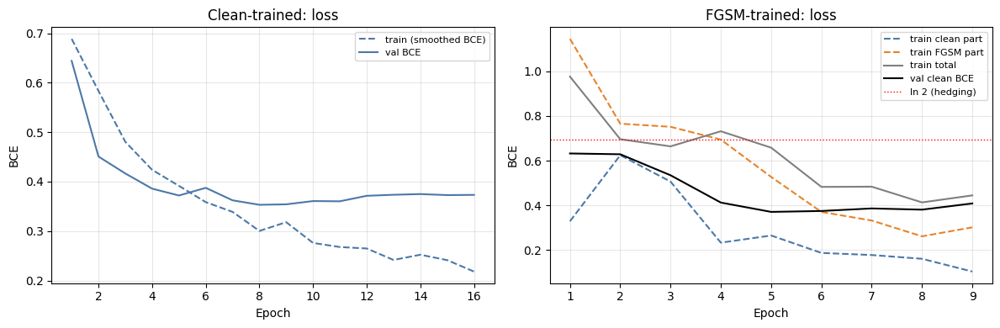

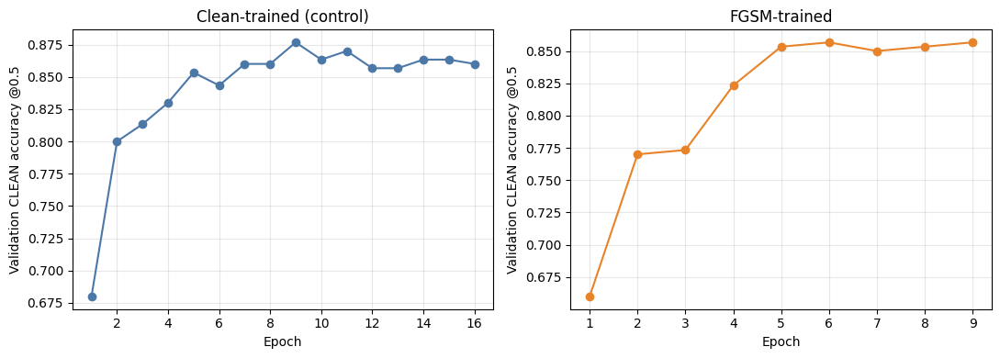

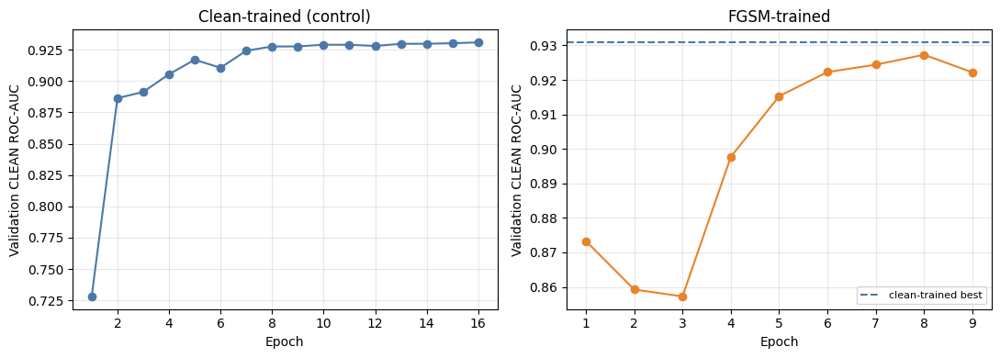

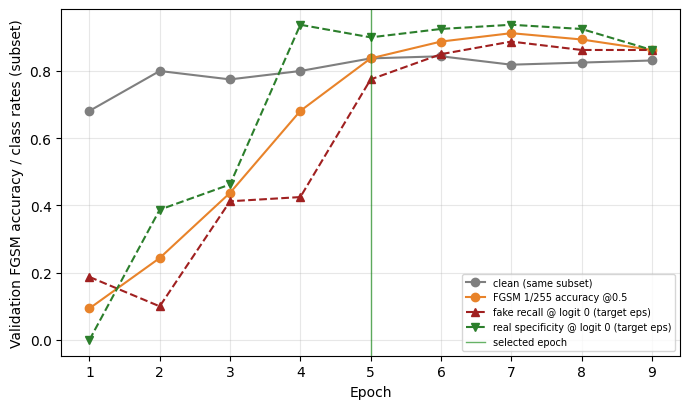

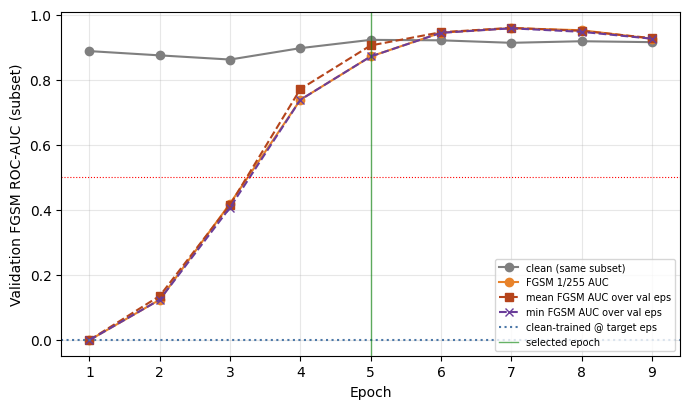

...

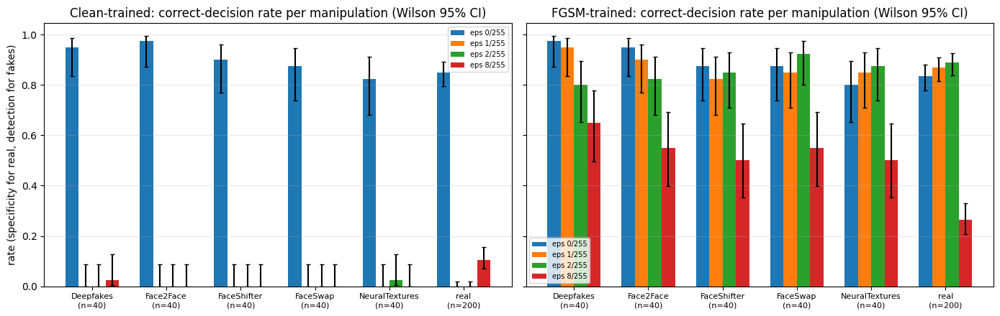

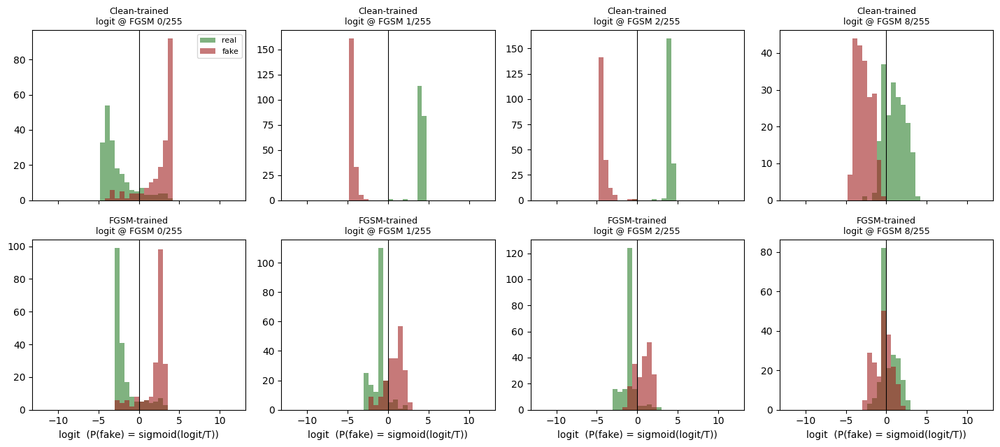

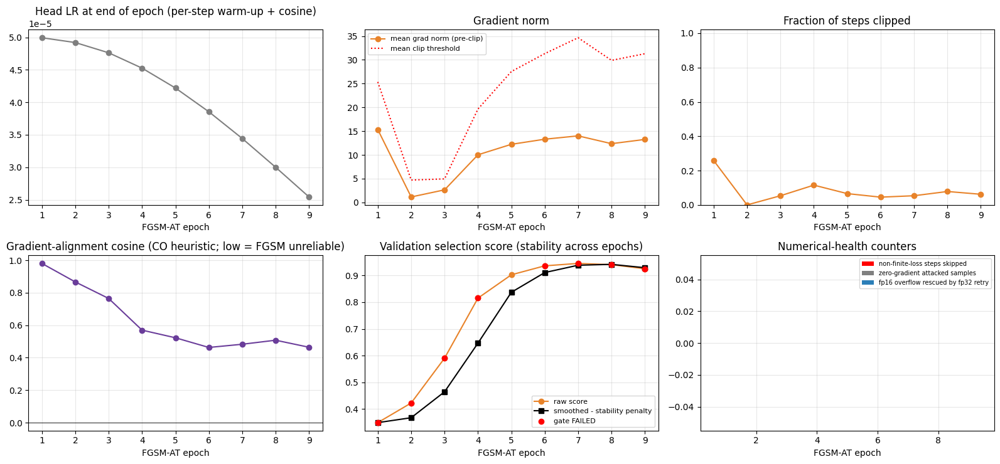

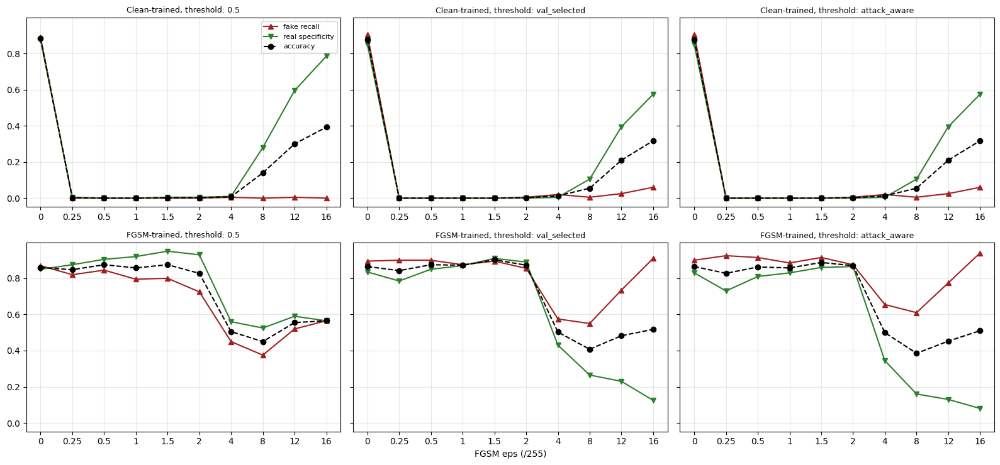

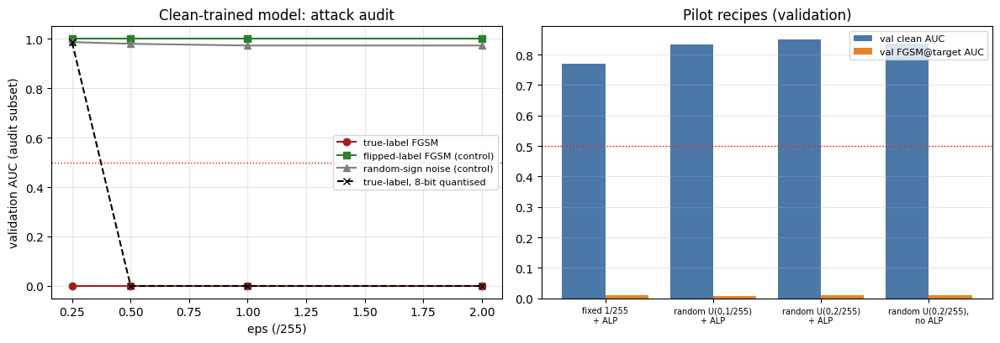


16 figures saved in /kaggle/working/figures
INTERPRETATION CAVEAT: Grad-CAM shows which spatial regions contributed to the prediction. It does NOT by itself prove the manipulation artifact -- a localisation aid, not ground-truth evidence.

  sample 0 (true=fake) | Clean-trained  | clean          | P(fake)=0.549 (thr 0.405) -> predicted fake
  sample 0 (true=fake) | Clean-trained  | FGSM 1/255     | P(fake)=0.042 (thr 0.405) -> predicted real
  sample 0 (true=fake) | Clean-trained  | FGSM 2/255     | P(fake)=0.043 (thr 0.405) -> predicted real
  sample 0 (true=fake) | FGSM-trained   | clean          | P(fake)=0.556 (thr 0.416) -> predicted fake
  sample 0 (true=fake) | FGSM-trained   | FGSM 1/255     | P(fake)=0.311 (thr 0.416) -> predicted real
  sample 0 (true=fake) | FGSM-trained   | FGSM 2/255     | P(fake)=0.571 (thr 0.416) -> predicted fake


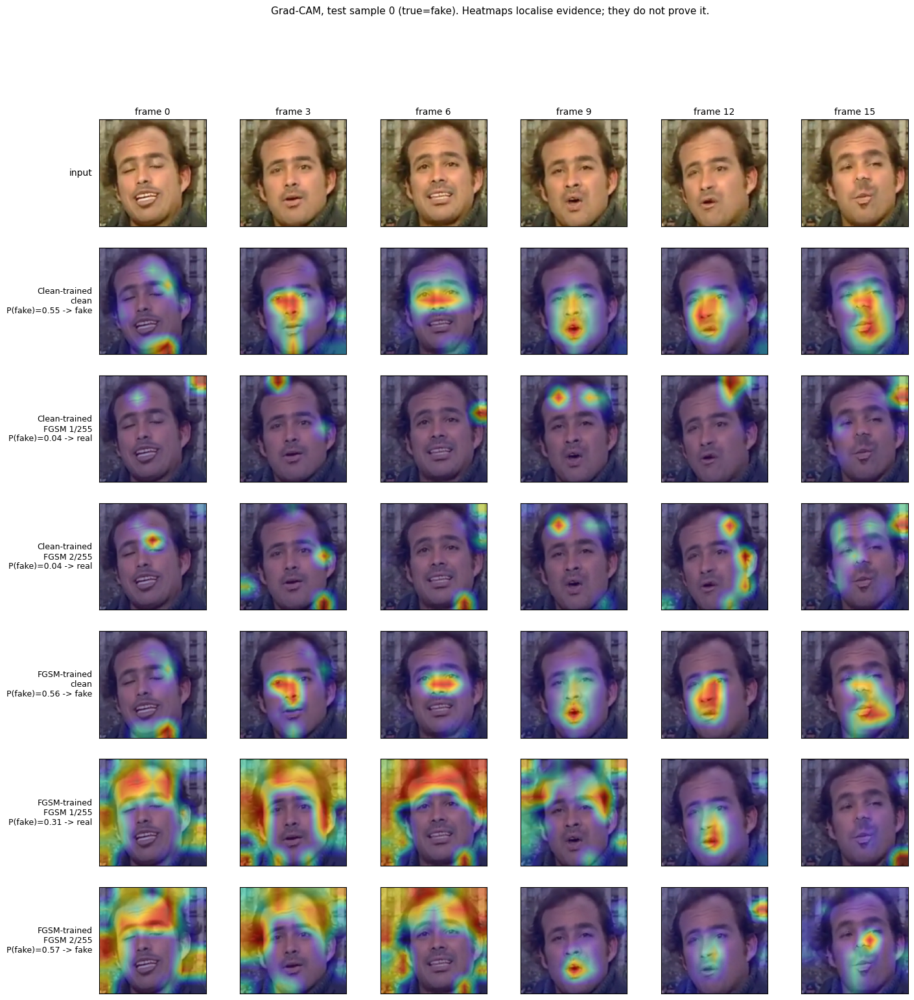

  sample 2 (true=real) | Clean-trained  | clean          | P(fake)=0.118 (thr 0.405) -> predicted real
  sample 2 (true=real) | Clean-trained  | FGSM 1/255     | P(fake)=0.940 (thr 0.405) -> predicted fake
  sample 2 (true=real) | Clean-trained  | FGSM 2/255     | P(fake)=0.937 (thr 0.405) -> predicted fake
  sample 2 (true=real) | FGSM-trained   | clean          | P(fake)=0.109 (thr 0.416) -> predicted real
  sample 2 (true=real) | FGSM-trained   | FGSM 1/255     | P(fake)=0.291 (thr 0.416) -> predicted real
  sample 2 (true=real) | FGSM-trained   | FGSM 2/255     | P(fake)=0.297 (thr 0.416) -> predicted real


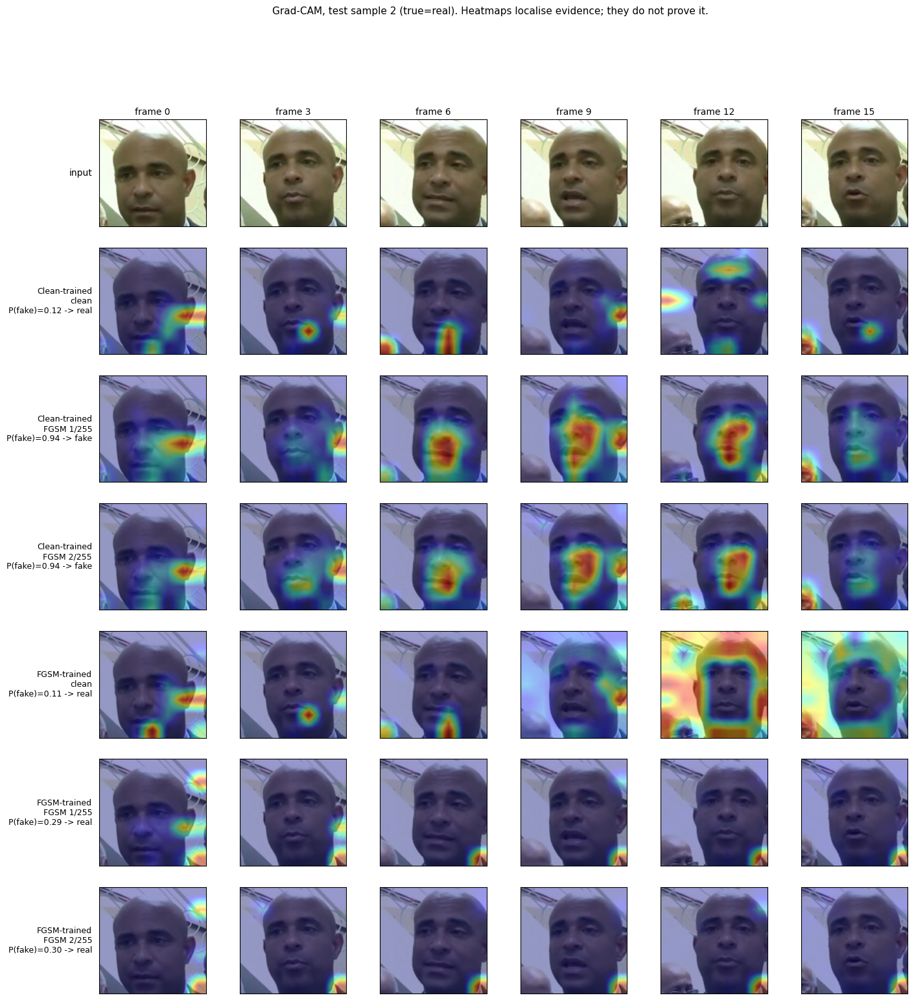

In [16]:
# ============================================================
# CELL 15: Figures (all saved to /kaggle/working/figures/)
# ============================================================
C_CLEAN, C_FGSM, C_GREY = "#4C78A8", "#E8832A", "#7f7f7f"
COL = {"Clean-trained": C_CLEAN, "FGSM-trained": C_FGSM}
XT = list(range(len(EVAL_EPS)))
XL = [f"{e * 255:g}" for e in EVAL_EPS]
FIGS = []


def _finish(fig, name):
    fig.tight_layout()
    FIGS.append(save_fig(fig, name))
    plt.show()


def _rows(tag, thr="val_selected"):
    return metrics_df[(metrics_df.model == tag) & (metrics_df.threshold_type == thr)].sort_values("eps_255")


# 1 loss curves
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(clean_df["epoch"], clean_df["train_loss"], "--", color=C_CLEAN, label="train (smoothed BCE)")
ax[0].plot(clean_df["epoch"], clean_df["val_loss"], color=C_CLEAN, label="val BCE")
ax[0].set_title("Clean-trained: loss")
ax[1].plot(fgsm_df["epoch"], fgsm_df["train_clean_loss"], "--", color=C_CLEAN, label="train clean part")
ax[1].plot(fgsm_df["epoch"], fgsm_df["train_adv_loss"], "--", color=C_FGSM, label="train FGSM part")
ax[1].plot(fgsm_df["epoch"], fgsm_df["train_loss"], color=C_GREY, label="train total")
if "val_loss" in fgsm_df:
    ax[1].plot(fgsm_df["epoch"], fgsm_df["val_loss"], color="black", label="val clean BCE")
ax[1].axhline(math.log(2), color="red", ls=":", lw=1, label="ln 2 (hedging)")
ax[1].set_title("FGSM-trained: loss")
for a in ax:
    a.set_xlabel("Epoch"); a.set_ylabel("BCE"); a.grid(alpha=.3); a.legend(fontsize=8)
_finish(fig, "fig01_loss_curves.png")

# 2 clean accuracy by epoch, 4 clean AUC by epoch
for name, col_c, col_f, ttl in [("fig02_clean_accuracy_by_epoch.png", "val_accuracy", "val_accuracy", "Validation CLEAN accuracy @0.5"),
                                ("fig04_clean_auc_by_epoch.png", "val_roc_auc", "val_clean_auc", "Validation CLEAN ROC-AUC")]:
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(clean_df["epoch"], clean_df[col_c], color=C_CLEAN, marker="o"); ax[0].set_title("Clean-trained (control)")
    ax[1].plot(fgsm_df["epoch"], fgsm_df[col_f], color=C_FGSM, marker="o"); ax[1].set_title("FGSM-trained")
    ref = BASELINE_VAL["clean_val_auc_full"] if "auc" in name else None
    if ref:
        ax[1].axhline(ref, color=C_CLEAN, ls="--", label="clean-trained best"); ax[1].legend(fontsize=8)
    for a in ax:
        a.set_xlabel("Epoch"); a.set_ylabel(ttl); a.grid(alpha=.3)
    _finish(fig, name)

# 3 FGSM accuracy by epoch, 5 FGSM AUC by epoch (validation subset)
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(fgsm_df["epoch"], fgsm_df["val_subset_clean_acc"], color=C_GREY, marker="o", label="clean (same subset)")
ax.plot(fgsm_df["epoch"], fgsm_df["val_fgsm_target_acc"], color=C_FGSM, marker="o", label=f"FGSM {CONFIG['target_eval_eps']:g}/255 accuracy @0.5")
ax.plot(fgsm_df["epoch"], fgsm_df["val_fgsm_target_sens"], color="#a02020", marker="^", ls="--", label="fake recall @ logit 0 (target eps)")
ax.plot(fgsm_df["epoch"], fgsm_df["val_fgsm_target_spec"], color="#2c7f2c", marker="v", ls="--", label="real specificity @ logit 0 (target eps)")
ax.axvline(fgsm_ckpt["epoch"], color="green", lw=1, alpha=.6, label="selected epoch")
ax.set_xlabel("Epoch"); ax.set_ylabel("Validation FGSM accuracy / class rates (subset)"); ax.grid(alpha=.3); ax.legend(fontsize=7)
_finish(fig, "fig03_fgsm_accuracy_by_epoch.png")
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(fgsm_df["epoch"], fgsm_df["val_subset_clean_auc"], color=C_GREY, marker="o", label="clean (same subset)")
ax.plot(fgsm_df["epoch"], fgsm_df["val_fgsm_target_auc"], color=C_FGSM, marker="o", label=f"FGSM {CONFIG['target_eval_eps']:g}/255 AUC")
ax.plot(fgsm_df["epoch"], fgsm_df["val_fgsm_mean_auc"], color="#B5441B", marker="s", ls="--", label="mean FGSM AUC over val eps")
ax.plot(fgsm_df["epoch"], fgsm_df["val_fgsm_min_auc"], color="#6a3d9a", marker="x", ls="--", label="min FGSM AUC over val eps")
ax.axhline(BASELINE_VAL["fgsm_target_auc"], color=C_CLEAN, ls=":", label="clean-trained @ target eps"); ax.axhline(0.5, color="red", lw=0.8, ls=":")
ax.axvline(fgsm_ckpt["epoch"], color="green", lw=1, alpha=.6, label="selected epoch")
ax.set_xlabel("Epoch"); ax.set_ylabel("Validation FGSM ROC-AUC (subset)"); ax.grid(alpha=.3); ax.legend(fontsize=7)
_finish(fig, "fig05_fgsm_auc_by_epoch.png")

# 6-8 accuracy / AUC / F1 vs epsilon (test)
for name, col, ttl, ci in [("fig06_accuracy_vs_eps.png", "accuracy", "Test accuracy", ("acc_ci_lo", "acc_ci_hi")),
                           ("fig07_auc_vs_eps.png", "roc_auc", "Test ROC-AUC", None),
                           ("fig08_f1_vs_eps.png", "f1", "Test macro F1", None)]:
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for tag in MODELS:
        r = _rows(tag, "0.5" if col == "roc_auc" else "val_selected")
        ax.plot(XT, r[col].values, marker="o", color=COL[tag], label=tag)
        if ci:
            ax.fill_between(XT, r[ci[0]].values, r[ci[1]].values, color=COL[tag], alpha=.15)
        if col == "roc_auc":
            ax.fill_between(XT, r["auc_ci_lo"].values, r["auc_ci_hi"].values, color=COL[tag], alpha=.15)
    if col == "roc_auc":
        ax.axhline(0.5, color="red", ls=":", lw=1)
    ax.axvline(XL.index(f"{CONFIG['target_eval_eps']:g}"), color=C_GREY, ls=":", lw=1)
    ax.axvline(XL.index(f"{FGSM_EPS * 255:g}") if f"{FGSM_EPS * 255:g}" in XL else 0, color=C_FGSM, ls=":", lw=1)
    ax.set_xticks(XT); ax.set_xticklabels(XL); ax.set_xlabel("FGSM evaluation epsilon (/255)"); ax.set_ylabel(ttl)
    ax.set_title(f"{ttl} vs FGSM epsilon (shaded: 95% CI; dotted verticals: target and training eps)")
    ax.grid(alpha=.3); ax.legend()
    _finish(fig, name)

# 9 ASR vs eps
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for a, tag in zip(ax, MODELS):
    r = _rows(tag)
    a.plot(XT, r["asr"], marker="o", color=COL[tag], label="overall")
    a.plot(XT, r["asr_real"], marker="s", ls="--", color="#2c7f2c", label="real videos")
    a.plot(XT, r["asr_fake"], marker="^", ls="--", color="#a02020", label="fake videos")
    a.set_xticks(XT); a.set_xticklabels(XL); a.set_xlabel("FGSM epsilon (/255)"); a.set_title(f"{tag}: attack success rate")
    a.grid(alpha=.3); a.legend(fontsize=8)
ax[0].set_ylabel("ASR (of initially-correct videos)")
_finish(fig, "fig09_asr_vs_eps.png")

# 10 clean-trained vs FGSM-trained comparison
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
w = 0.38
for a, col, ttl in zip(ax[:2], ["accuracy", "roc_auc"], ["Accuracy", "ROC-AUC"]):
    rc, rf = _rows("Clean-trained", "0.5"), _rows("FGSM-trained", "0.5")
    a.bar(np.array(XT) - w / 2, rc[col], w, color=C_CLEAN, label="Clean-trained")
    a.bar(np.array(XT) + w / 2, rf[col], w, color=C_FGSM, label="FGSM-trained")
    a.set_xticks(XT); a.set_xticklabels(XL); a.set_title(f"{ttl} @0.5 by FGSM eps"); a.set_xlabel("eps (/255)"); a.legend(fontsize=8); a.grid(alpha=.3, axis="y")
d = paired_df.sort_values("eps_255")
ax[2].bar(XT, d["auc_delta"], color=[C_FGSM if v > 0 else C_GREY for v in d["auc_delta"]])
ax[2].errorbar(XT, d["auc_delta"], yerr=[np.clip(d["auc_delta"] - d["auc_delta_ci_lo"], 0, None), np.clip(d["auc_delta_ci_hi"] - d["auc_delta"], 0, None)], fmt="none", ecolor="black", capsize=3)
ax[2].axhline(0, color="black", lw=.8); ax[2].set_xticks(XT); ax[2].set_xticklabels(XL)
ax[2].set_title("AUC(FGSM-trained) - AUC(clean-trained), paired 95% CI"); ax[2].set_xlabel("eps (/255)"); ax[2].grid(alpha=.3, axis="y")
_finish(fig, "fig10_clean_vs_fgsm_trained.png")

# 11 confusion matrices
CM_EPS = sorted({0.0, CONFIG["target_eval_eps"] * EPS_UNIT, FGSM_EPS, 8 * EPS_UNIT})
fig, ax = plt.subplots(2, len(CM_EPS), figsize=(3.6 * len(CM_EPS), 7))
for i, (tag, (m, T_, thr_)) in enumerate(MODELS.items()):
    for j, e in enumerate(CM_EPS):
        pred = (sigmoid_np(RAW[tag][1][e], T_) >= thr_).astype(int)
        sns.heatmap(confusion_matrix(test_labels, pred, labels=[0, 1]), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[i, j],
                    xticklabels=["Pred real", "Pred fake"], yticklabels=["True real", "True fake"])
        ax[i, j].set_title(f"{tag}\nFGSM {e * 255:g}/255 (thr {thr_:.2f})", fontsize=9)
_finish(fig, "fig11_confusion_matrices.png")

# 12 per-manipulation
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
methods = sorted(set(test_methods))
for a, tag in zip(ax, MODELS):
    for k, e in enumerate(PM_EPS):
        s = per_method_df[(per_method_df.model == tag) & np.isclose(per_method_df.eps_255, e * 255)].set_index("method").loc[methods]
        xs = np.arange(len(methods)) + (k - (len(PM_EPS) - 1) / 2) * 0.18
        a.bar(xs, s["rate"], 0.18, yerr=[np.clip(s["rate"] - s["ci_lo"], 0, None), np.clip(s["ci_hi"] - s["rate"], 0, None)], capsize=2, label=f"eps {e * 255:g}/255")
    a.set_xticks(np.arange(len(methods))); a.set_xticklabels([f"{m}\n(n={int((test_methods == m).sum())})" for m in methods], fontsize=8)
    a.set_title(f"{tag}: correct-decision rate per manipulation (Wilson 95% CI)"); a.grid(alpha=.3, axis="y"); a.legend(fontsize=7)
ax[0].set_ylabel("rate (specificity for real, detection for fakes)")
_finish(fig, "fig12_per_manipulation.png")

# 13 probability / logit distributions
fig, ax = plt.subplots(2, len(CM_EPS), figsize=(3.6 * len(CM_EPS), 6.5), sharex=True)
for i, (tag, (m, T_, thr_)) in enumerate(MODELS.items()):
    for j, e in enumerate(CM_EPS):
        z = RAW[tag][1][e]
        bins = np.linspace(min(-12, np.percentile(z, 0.5)), max(12, np.percentile(z, 99.5)), 41)
        ax[i, j].hist(z[test_labels == 0], bins=bins, alpha=.6, color="#2c7f2c", label="real")
        ax[i, j].hist(z[test_labels == 1], bins=bins, alpha=.6, color="#a02020", label="fake")
        ax[i, j].axvline(0, color="black", lw=.8)
        ax[i, j].set_title(f"{tag}\nlogit @ FGSM {e * 255:g}/255", fontsize=9)
        if i == 1:
            ax[i, j].set_xlabel("logit  (P(fake) = sigmoid(logit/T))")
ax[0, 0].legend(fontsize=8)
_finish(fig, "fig13_logit_distributions.png")

# 14 stability / learning rate / numerics
fig, ax = plt.subplots(2, 3, figsize=(16, 7.5))
ax[0, 0].plot(fgsm_df["epoch"], fgsm_df["lr"], color=C_GREY, marker="o"); ax[0, 0].set_title("Head LR at end of epoch (per-step warm-up + cosine)")
ax[0, 1].plot(fgsm_df["epoch"], fgsm_df["train_grad_norm"], color=C_FGSM, marker="o", label="mean grad norm (pre-clip)")
ax[0, 1].plot(fgsm_df["epoch"], fgsm_df["train_clip_thr"], color="red", ls=":", label="mean clip threshold"); ax[0, 1].legend(fontsize=8); ax[0, 1].set_title("Gradient norm")
ax[0, 2].plot(fgsm_df["epoch"], fgsm_df["train_clip_rate"], color=C_FGSM, marker="o"); ax[0, 2].set_ylim(0, 1.02); ax[0, 2].set_title("Fraction of steps clipped")
ax[1, 0].plot(fgsm_df["epoch"], fgsm_df["train_grad_align"], color="#6a3d9a", marker="o"); ax[1, 0].axhline(0, color="black", lw=.6)
ax[1, 0].set_title("Gradient-alignment cosine (CO heuristic; low = FGSM unreliable)")
ax[1, 1].plot(fgsm_df["epoch"], fgsm_df["select_raw"], color=C_FGSM, marker="o", label="raw score")
ax[1, 1].plot(fgsm_df["epoch"], fgsm_df["select_score"], color="black", marker="s", label="smoothed - stability penalty")
ax[1, 1].scatter(fgsm_df["epoch"][~fgsm_df["gate_ok"].astype(bool)], fgsm_df["select_raw"][~fgsm_df["gate_ok"].astype(bool)], color="red", zorder=5, label="gate FAILED")
ax[1, 1].legend(fontsize=8); ax[1, 1].set_title("Validation selection score (stability across epochs)")
ax[1, 2].bar(fgsm_df["epoch"] - 0.2, fgsm_df["train_nan_skips"], 0.4, color="red", label="non-finite-loss steps skipped")
ax[1, 2].bar(fgsm_df["epoch"] + 0.2, fgsm_df["train_zero_grad_samples"], 0.4, color=C_GREY, label="zero-gradient attacked samples"); ax[1, 2].bar(fgsm_df["epoch"], fgsm_df["train_fp32_retries"], 0.15, color="#2c7fb8", label="fp16 overflow rescued by fp32 retry"); ax[1, 2].legend(fontsize=7)
ax[1, 2].set_title("Numerical-health counters")
for a in ax.ravel():
    a.set_xlabel("FGSM-AT epoch"); a.grid(alpha=.3)
_finish(fig, "fig14_stability_and_lr.png")
# 16 class-wise rates vs eps for the three thresholds (the fake-recall problem)
fig, ax = plt.subplots(2, 3, figsize=(16, 7.5), sharey=True)
for i, tag in enumerate(MODELS):
    for j, thr in enumerate(["0.5", "val_selected", "attack_aware"]):
        r = _rows(tag, thr)
        ax[i, j].plot(XT, r["n_fake_detected"] / r["n_fake"], marker="^", color="#a02020", label="fake recall")
        ax[i, j].plot(XT, r["n_real_kept"] / r["n_real"], marker="v", color="#2c7f2c", label="real specificity")
        ax[i, j].plot(XT, r["accuracy"], marker="o", color="black", ls="--", label="accuracy")
        ax[i, j].set_xticks(XT); ax[i, j].set_xticklabels(XL); ax[i, j].set_title(f"{tag}, threshold: {thr}", fontsize=9); ax[i, j].grid(alpha=.3)
ax[0, 0].legend(fontsize=8); ax[1, 1].set_xlabel("FGSM eps (/255)")
_finish(fig, "fig16_classwise_rates_vs_eps.png")

# 17 attack audit of the clean-trained model (A3 controls) + 18 pilot comparison
_ad = pd.DataFrame(AUDIT["rows"])
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].plot(_ad.eps_255, _ad.A3_auc_true, marker="o", color="#a02020", label="true-label FGSM")
ax[0].plot(_ad.eps_255, _ad.A3_auc_flipped, marker="s", color="#2c7f2c", label="flipped-label FGSM (control)")
ax[0].plot(_ad.eps_255, _ad.A3_auc_random, marker="^", color=C_GREY, label="random-sign noise (control)")
ax[0].plot(_ad.eps_255, _ad.A6_auc_quantised, marker="x", ls="--", color="black", label="true-label, 8-bit quantised")
ax[0].axhline(0.5, color="red", ls=":", lw=1); ax[0].set_xlabel("eps (/255)"); ax[0].set_ylabel("validation AUC (audit subset)")
ax[0].set_title("Clean-trained model: attack audit"); ax[0].legend(fontsize=8); ax[0].grid(alpha=.3)
if len(PILOT_ROWS):
    _pd = pd.DataFrame(PILOT_ROWS)
    xx = np.arange(len(_pd))
    ax[1].bar(xx - 0.2, _pd["val_clean_auc"], 0.4, color=C_CLEAN, label="val clean AUC")
    ax[1].bar(xx + 0.2, _pd["val_fgsm_target_auc"], 0.4, color=C_FGSM, label="val FGSM@target AUC")
    ax[1].set_xticks(xx); ax[1].set_xticklabels([v.replace(" + ", "\n+ ").replace(", ", ",\n") for v in _pd["variant"]], fontsize=7)
    ax[1].axhline(0.5, color="red", ls=":", lw=1); ax[1].set_title("Pilot recipes (validation)"); ax[1].legend(fontsize=8); ax[1].grid(alpha=.3, axis="y")
_finish(fig, "fig17_audit_and_pilot.png")
print(f"\n{len(FIGS)} figures saved in {FIG_DIR}")


# ============================================================
# 15b: Grad-CAM -- clean-trained vs FGSM-trained, on clean AND FGSM input (white-box, crafted against each model)
# ============================================================
# Target layer: the last EfficientNet-B1 block. fp32, BN/dropout frozen via _prepare_model_for_attack (LSTM keeps its training-mode
# cuDNN backward). Hooks are removed after every call. CAVEAT: Grad-CAM shows where evidence came from; it does not prove the artifact.

class VideoGradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.gradients = None
        self.activations = None
        self.handles = [target_layer.register_forward_hook(self._save_act),
                        target_layer.register_full_backward_hook(self._save_grad)]

    def _save_act(self, module, inp, out):
        self.activations = out.detach()

    def _save_grad(self, module, grad_in, grad_out):
        self.gradients = grad_out[0].detach()

    def remove(self):
        for h in self.handles:
            h.remove()

    def heatmaps(self, video_tensor):
        """video_tensor: [1, T, 3, H, W] -> (P(fake) uncalibrated, per-frame heatmaps [T, h, w])."""
        prev = _prepare_model_for_attack(self.model)
        try:
            x = video_tensor.clone().detach().requires_grad_(True)
            logits = self.model(x)
            prob = torch.sigmoid(logits.float()).item()
            self.model.zero_grad()
            logits.sum().backward()
            weights = self.gradients.mean(dim=(2, 3), keepdim=True)
            cams = Fn.relu((weights * self.activations).sum(dim=1))
            maps = []
            for cam in cams:
                cam = cam - cam.min()
                maps.append((cam / (cam.max() + 1e-7)).cpu().numpy())
        finally:
            _restore_model_modes(self.model, prev)
            self.model.zero_grad(set_to_none=True)
        return prob, np.array(maps)


def _cam_maps(model, video):
    cam = VideoGradCAM(model, model.feature_extractor[0][-1])
    try:
        return cam.heatmaps(video)
    finally:
        cam.remove()


def _overlay(frame_norm, heat):
    img = np.clip(np.array(IMAGENET_STD) * frame_norm + np.array(IMAGENET_MEAN), 0, 1)
    img8 = (img * 255).astype(np.uint8)
    h = cv2.resize(heat, (img8.shape[1], img8.shape[0]))
    colour = cv2.cvtColor(cv2.applyColorMap(np.uint8(255 * h), cv2.COLORMAP_JET), cv2.COLOR_BGR2RGB)
    return img, cv2.addWeighted(img8, 0.6, colour, 0.4, 0)


def gradcam_comparison(sample_idx, n_show=6):
    video, label = test_dataset[sample_idx]
    video = video.unsqueeze(0).to(CONFIG["device"])
    y = torch.as_tensor(label).view(1).to(CONFIG["device"])
    attack_eps = sorted({CONFIG["target_eval_eps"] * EPS_UNIT, FGSM_EPS})
    kinds = ["clean"] + [f"FGSM {e * 255:g}/255" for e in attack_eps]
    results = {}
    for name, (mdl, T_, thr_) in MODELS.items():
        inputs = [video] + [fgsm_attack(mdl, video, y, e) for e in attack_eps]     # crafted against THIS model
        for kind, inp in zip(kinds, inputs):
            with torch.no_grad():
                p = float(torch.sigmoid(mdl(inp).float() / T_).item())
            _, maps = _cam_maps(mdl, inp)
            results[(name, kind)] = (inp, p, maps, thr_)
    fidx = np.linspace(0, CONFIG["seq_len"] - 1, n_show, dtype=int)
    nrows = 1 + len(MODELS) * len(kinds)
    fig, axes = plt.subplots(nrows, n_show, figsize=(2.3 * n_show + 2.5, 2.5 * nrows))
    base = video[0].cpu().numpy()
    for j, f in enumerate(fidx):
        axes[0, j].imshow(_overlay(base[f].transpose(1, 2, 0), np.zeros((7, 7)))[0])
        axes[0, j].set_title(f"frame {f}", fontsize=10)
    axes[0, 0].set_ylabel("input", fontsize=10, rotation=0, ha="right", va="center", labelpad=8)
    row = 1
    true_txt = "fake" if int(label) else "real"
    for name in MODELS:
        for kind in kinds:
            inp, p, maps, thr_ = results[(name, kind)]
            arr = inp[0].detach().cpu().numpy()
            for j, f in enumerate(fidx):
                axes[row, j].imshow(_overlay(arr[f].transpose(1, 2, 0), maps[min(f, len(maps) - 1)])[1])
            pred = "fake" if p >= thr_ else "real"
            axes[row, 0].set_ylabel(f"{name}\n{kind}\nP(fake)={p:.2f} -> {pred}", fontsize=9, rotation=0, ha="right", va="center", labelpad=8)
            print(f"  sample {sample_idx} (true={true_txt}) | {name:<14} | {kind:<14} | P(fake)={p:.3f} (thr {thr_:.3f}) -> predicted {pred}")
            row += 1
    for ax in axes.ravel():
        ax.set_xticks([]); ax.set_yticks([])
    fig.suptitle(f"Grad-CAM, test sample {sample_idx} (true={true_txt}). Heatmaps localise evidence; they do not prove it.", fontsize=11)
    FIGS.append(save_fig(fig, f"fig15_gradcam_sample{sample_idx}.png"))
    plt.show()


print("INTERPRETATION CAVEAT: Grad-CAM shows which spatial regions contributed to the prediction. It does NOT by itself prove the "
      "manipulation artifact -- a localisation aid, not ground-truth evidence.\n")
_fake_idx = next(i for i, (_, l) in enumerate(test_records) if l == 1)
_real_idx = next(i for i, (_, l) in enumerate(test_records) if l == 0)
for _i in (_fake_idx, _real_idx):
    gradcam_comparison(_i)
free_cuda_memory()

In [17]:
# ============================================================
# CELL 16: Version comparison v4 -> v9 (values copied from the executed v4-v7 notebooks / v4 review; nothing re-estimated)
# ============================================================
# "Not reported" = the earlier version never printed that number. "Not directly comparable" = different test set / subset size / threshold
# rule. v5-v7 use the SAME identity-disjoint split and caps as v8 ('Clean (full test)' = 400 videos, validation-selected threshold); their
# FGSM numbers were measured on a balanced 200- or 300-video SUBSET, v8/v9 on the whole test set. Iterative-attack results of earlier versions
# are intentionally not tabulated here: v8/v9 are FGSM-only, and FGSM numbers of an adversarially trained model must not be read as robustness.
NR = "Not reported"
HIST = [
    # version, model, n_fgsm_videos, clean acc (full test), clean AUC, FGSM acc 1,2,4,8 ; FGSM AUC 1,2,4,8 ; comparability
    ("v4", "Clean-trained", 300, 0.870, 0.935, NR, 0.003, 0.010, 0.370, NR, NR, NR, NR, "Not directly comparable (non-identity-disjoint split, 300-video test set)"),
    ("v4", "ART (FGSM+label-leaking)", 300, NR, NR, NR, 0.930, 0.920, 0.620, NR, NR, NR, NR, "Not directly comparable; accuracy ABOVE clean = label-leaking signature"),
    ("v5", "Clean-trained", 300, 0.868, 0.9354, NR, 0.000, 0.0067, 0.100, NR, 0.0000, 0.0003, 0.0097, "Clean numbers comparable; FGSM subset 300"),
    ("v5", "ART fine-tuned", 300, 0.865, 0.9272, NR, 0.500, 0.500, 0.500, NR, 0.4368, 0.4864, 0.7533, "Clean numbers comparable; FGSM subset 300"),
    ("v6", "Clean-trained", 200, 0.875, 0.9456, NR, 0.000, 0.010, 0.035, NR, 0.0000, 0.0008, 0.0037, "Clean numbers comparable; FGSM subset 200"),
    ("v6", "ART fine-tuned", 200, 0.858, 0.9373, NR, 0.495, 0.500, 0.480, NR, 0.8503, 0.8119, 0.6530, "Clean numbers comparable; FGSM subset 200"),
    ("v7", "Clean-trained", 200, 0.870, 0.9457, 0.000, 0.000, 0.005, 0.055, 0.0000, 0.0000, 0.0001, 0.0061, "Clean numbers comparable; FGSM subset 200"),
    ("v7", "ART fine-tuned", 200, 0.848, 0.9158, 0.215, 0.220, 0.230, 0.255, 0.0738, 0.0678, 0.0762, 0.1516, "Clean numbers comparable; FGSM subset 200"),
    # v8 values copied from the user's executed v8 notebook (full test set, 400 videos, clean-EER validation-selected threshold)
    ("v8", "Clean-trained (FGSM-only)", 400, 0.9025, 0.9569, 0.0000, 0.0000, 0.0125, 0.0400, 0.0000, 0.0000, 0.0000, 0.0025, "Same split, full test set"),
    ("v8", "FGSM-trained (FGSM-only)", 400, 0.8250, 0.8731, 0.5375, 0.5150, 0.4975, 0.4950, 0.3982, 0.3688, 0.3301, 0.3853, "Same split, full test set; AUC < 0.5 = hedged model attacked with true labels"),
]
cols = ["version", "model", "n_videos_fgsm", "clean_acc_full_test", "clean_auc_full_test", "fgsm1_acc", "fgsm2_acc", "fgsm4_acc", "fgsm8_acc",
        "fgsm1_auc", "fgsm2_auc", "fgsm4_auc", "fgsm8_auc", "comparability"]
cmp_rows = [dict(zip(cols, r)) for r in HIST]


def _v9_row(tag):
    g = lambda e, c, thr="val_selected": float(metrics_df[(metrics_df.model == tag) & np.isclose(metrics_df.eps_255, e) & (metrics_df.threshold_type == thr)][c].iloc[0])
    return {"version": "v9", "model": tag + " (FGSM-only)", "n_videos_fgsm": n_test, "clean_acc_full_test": g(0, "accuracy"),
            "clean_auc_full_test": g(0, "roc_auc"), **{f"fgsm{e}_acc": g(e, "accuracy") for e in (1, 2, 4, 8)},
            **{f"fgsm{e}_auc": g(e, "roc_auc") for e in (1, 2, 4, 8)},
            "comparability": "Clean numbers comparable (same split); FGSM measured on the FULL test set"}


for t in MODELS:
    cmp_rows.append(_v9_row(t))
compare_df = pd.DataFrame(cmp_rows)
compare_df.to_csv(os.path.join(OUT_DIR, "fgsm_v9_version_comparison.csv"), index=False)
print(compare_df.drop(columns=["comparability"]).to_string(index=False))
print("\nComparability notes:")
for r in cmp_rows:
    print(f"  {r['version']} {r['model']}: {r['comparability']}")
print("\nReading guide: 'FGSM acc' of an adversarially trained model that is HIGHER than its clean accuracy (v4) or pinned at 0.50 with "
      "AUC near chance (v5/v6) is hedging / label-leaking, not robustness. v9's Cell 14 measures these signatures directly.")

version                     model  n_videos_fgsm clean_acc_full_test clean_auc_full_test    fgsm1_acc  fgsm2_acc  fgsm4_acc  fgsm8_acc    fgsm1_auc    fgsm2_auc    fgsm4_auc    fgsm8_auc
     v4             Clean-trained            300                0.87               0.935 Not reported     0.0030     0.0100     0.3700 Not reported Not reported Not reported Not reported
     v4  ART (FGSM+label-leaking)            300        Not reported        Not reported Not reported     0.9300     0.9200     0.6200 Not reported Not reported Not reported Not reported
     v5             Clean-trained            300               0.868              0.9354 Not reported     0.0000     0.0067     0.1000 Not reported          0.0       0.0003       0.0097
     v5            ART fine-tuned            300               0.865              0.9272 Not reported     0.5000     0.5000     0.5000 Not reported       0.4368       0.4864       0.7533
     v6             Clean-trained            200               0.

In [18]:
# ============================================================
# CELL 17: Verdict against the criteria that were frozen BEFORE the test set was opened
# ============================================================
crit = json.load(open(CONFIG["acceptance_json"]))
assert hashlib.md5(open(CONFIG["acceptance_json"], "rb").read()).hexdigest()[:12] == CRITERIA_HASH, "acceptance_criteria.json was modified after freezing"
g = lambda tag, e, c, thr="val_selected": float(metrics_df[(metrics_df.model == tag) & np.isclose(metrics_df.eps_255, e) & (metrics_df.threshold_type == thr)][c].iloc[0])
tgt, trn = CONFIG["target_eval_eps"], FGSM_EPS * 255
res = {}
auc_c, auc_f = g("Clean-trained", 0, "roc_auc", "0.5"), g("FGSM-trained", 0, "roc_auc", "0.5")
res["C1"] = (auc_f >= CONFIG["accept_min_test_clean_auc_ratio"] * auc_c, f"clean test AUC FGSM-trained {auc_f:.4f} vs clean-trained {auc_c:.4f} (ratio {auc_f / auc_c:.3f}, need >= {CONFIG['accept_min_test_clean_auc_ratio']})")
res["C2"] = (crit["validation_evidence_already_known"]["C2_met"], f"validation FGSM AUC @target = {crit['validation_evidence_already_known']['C2_value']:.4f}")
res["C3"] = (crit["validation_evidence_already_known"]["C3_met"], f"validation FGSM AUC gain over clean-trained = {crit['validation_evidence_already_known']['C3_value']:+.4f}")
own_clean = g("FGSM-trained", 0, "accuracy")
leaks = [(e, g("FGSM-trained", e, "accuracy")) for e in CONFIG["eval_eps_grid"] if g("FGSM-trained", e, "accuracy") > own_clean + CONFIG["accept_max_label_leak_margin"]]
res["C4"] = (not leaks, f"FGSM accuracy above clean accuracy + margin at: {leaks if leaks else 'no epsilon'}")


def _delta_lo(e):
    r = paired_df[np.isclose(paired_df.eps_255, e)].iloc[0]
    return r["auc_delta"], r["auc_delta_ci_lo"], r["auc_delta_ci_hi"]


dt, dr = _delta_lo(tgt), _delta_lo(trn)
res["C5"] = (dt[1] > 0 and dr[1] > 0, f"AUC delta @{tgt:g}/255 = {dt[0]:+.4f} [{dt[1]:+.4f}, {dt[2]:+.4f}]; @{trn:g}/255 = {dr[0]:+.4f} [{dr[1]:+.4f}, {dr[2]:+.4f}]")
nan_total = int(fgsm_df["train_nan_skips"].sum())     # steps that stayed non-finite even in fp32 and were skipped
res["C6"] = (EVAL_DIAG["zero_grad_samples"] == 0 and EVAL_DIAG["nonfinite_grad_samples"] == 0 and nan_total == 0,
             f"eval zero-grad {EVAL_DIAG['zero_grad_samples']}, eval non-finite grads {EVAL_DIAG['nonfinite_grad_samples']}, training NaN-skipped steps {nan_total}")
_tt = metrics_df[(metrics_df.model == "FGSM-trained") & np.isclose(metrics_df.eps_255, tgt) & (metrics_df.threshold_type == "attack_aware")].iloc[0]
_rec, _spc = _tt["n_fake_detected"] / _tt["n_fake"], _tt["n_real_kept"] / _tt["n_real"]
res["C7"] = (_rec >= CONFIG["accept_min_class_recall"] and _spc >= CONFIG["accept_min_class_recall"],
             f"@{tgt:g}/255, attack-aware threshold {THR_AA['FGSM-trained']:.3f}: fake recall {int(_tt['n_fake_detected'])}/{int(_tt['n_fake'])} = {_rec:.3f}, "
             f"real specificity {int(_tt['n_real_kept'])}/{int(_tt['n_real'])} = {_spc:.3f} (need both >= {CONFIG['accept_min_class_recall']})")
_c_ov = metrics_df[(metrics_df.model == "FGSM-trained") & np.isclose(metrics_df.eps_255, 0) & (metrics_df.threshold_type == "val_selected")].iloc[0]["accuracy"]
_c_cl = metrics_df[(metrics_df.model == "Clean-trained") & np.isclose(metrics_df.eps_255, 0) & (metrics_df.threshold_type == "val_selected")].iloc[0]["accuracy"]
print(f"Clean accuracy gap (test, clean-EER thr): clean-trained {_c_cl:.4f} vs FGSM-trained {_c_ov:.4f} -> gap {(_c_cl - _c_ov) * 100:.2f} pts (v8: 7.75 pts). Reported, not a pass/fail criterion.")
print("ACCEPTANCE CRITERIA (frozen before test access; C8 follows Cell 18)")
for k, (ok, msg) in res.items():
    print(f"  {k}: {'MET ' if ok else 'NOT MET'} | {crit['criteria'][{'C1':'C1_clean_auc_retained','C2':'C2_val_fgsm_auc_target','C3':'C3_val_fgsm_auc_gain','C4':'C4_no_label_leak','C5':'C5_paired_gain','C6':'C6_numerics','C7':'C7_class_balance_under_attack'}[k]]}\n          -> {msg}")
n_met = sum(ok for ok, _ in res.values())
if crit["gate_never_passed"]:
    VERDICT = "FAILED (no epoch ever passed the validation gates)"
elif n_met == len(res):
    VERDICT = "SUCCEEDED against FGSM on the main seed (C1-C7 met; C8 multi-seed pending Cell 18)"
elif res["C5"][0] and res["C4"][0] and res["C6"][0]:
    VERDICT = f"PARTIAL against FGSM ({n_met}/{len(res)} criteria met; a measurable FGSM gain exists but a stricter criterion failed)"
else:
    VERDICT = f"FAILED against FGSM ({n_met}/{len(res)} criteria met)"
print(f"\nVERDICT: {VERDICT}")
print("SCOPE: this is an FGSM-ONLY experiment. PGD / iterative attacks were deliberately excluded, so NO claim of general adversarial "
      "robustness is made; a model can pass every FGSM criterion and still be fully breakable by multi-step attacks.")

summary = {"verdict": VERDICT, "criteria": {k: {"met": bool(ok), "evidence": msg} for k, (ok, msg) in res.items()},
           "train_eps_255": trn, "target_eps_255": tgt, "selected_epoch": int(fgsm_ckpt["epoch"]), "n_test_videos": n_test,
           "criteria_hash": CRITERIA_HASH, "findings": FINDINGS, "audit_verdicts": AUDIT["verdicts"], "attack_aware_thresholds": ATTACK_AWARE_THR,
           "nan_events_first": [e for h in fgsm_history for e in h.get("train_nan_events", [])][:5],
           "key_numbers": {"clean_test_auc_clean_trained": auc_c, "clean_test_auc_fgsm_trained": auc_f,
                           **{f"{tag}_acc_eps{e:g}": g(tag, e, "accuracy") for tag in MODELS for e in (0, tgt, trn, 8)},
                           **{f"{tag}_auc_eps{e:g}": g(tag, e, "roc_auc", "0.5") for tag in MODELS for e in (0, tgt, trn, 8)}}}
atomic_json_save(summary, os.path.join(OUT_DIR, "fgsm_v9_results_summary.json"))

with open(os.path.join(OUT_DIR, "fgsm_v9_final_summary.md"), "w") as f:
    f.write(f"# v9 FGSM-only adversarial training -- final summary (auto-generated from this run)\n\n**Verdict:** {VERDICT}\n\n")
    f.write(f"Training epsilon {trn:g}/255, target epsilon {tgt:g}/255, selected epoch {fgsm_ckpt['epoch']}, test videos {n_test}.\n\n")
    f.write("| epsilon (/255) | clean-trained acc | FGSM-trained acc | clean-trained AUC | FGSM-trained AUC |\n|---|---|---|---|---|\n")
    for e in CONFIG["eval_eps_grid"]:
        f.write(f"| {e:g} | {g('Clean-trained', e, 'accuracy'):.3f} | {g('FGSM-trained', e, 'accuracy'):.3f} | "
                f"{g('Clean-trained', e, 'roc_auc', '0.5'):.3f} | {g('FGSM-trained', e, 'roc_auc', '0.5'):.3f} |\n")
    f.write("\nCriteria:\n" + "\n".join(f"- {k}: {'met' if ok else 'NOT met'} -- {msg}" for k, (ok, msg) in res.items()))
    f.write("\n\nScope: FGSM only. PGD was deliberately excluded; nothing here supports a claim of general adversarial robustness.\n")
print("\nWritten:", os.path.join(OUT_DIR, "fgsm_v9_final_summary.md"))

Clean accuracy gap (test, clean-EER thr): clean-trained 0.8775 vs FGSM-trained 0.8650 -> gap 1.25 pts (v8: 7.75 pts). Reported, not a pass/fail criterion.
ACCEPTANCE CRITERIA (frozen before test access; C8 follows Cell 18)
  C1: NOT MET | test clean ROC-AUC of FGSM-trained >= 0.97 x clean-trained
          -> clean test AUC FGSM-trained 0.9204 vs clean-trained 0.9509 (ratio 0.968, need >= 0.97)
  C2: MET  | validation FGSM AUC at target eps >= 0.75
          -> validation FGSM AUC @target = 0.8714
  C3: MET  | validation FGSM AUC at target eps exceeds the clean-trained model's by >= 0.1
          -> validation FGSM AUC gain over clean-trained = +0.8714
  C4: NOT MET | test FGSM accuracy at any eps <= clean accuracy + 0.02
          -> FGSM accuracy above clean accuracy + margin at: [(1.5, 0.9025)]
  C5: MET  | paired-bootstrap 95% CI of [AUC(FGSM-trained) - AUC(clean-trained)] has lower bound > 0 at the target AND the training epsilon (test)
          -> AUC delta @1/255 = +0.9019 [+0.

In [19]:
# ============================================================
# CELL 18: Extra training seeds (time-guarded) and runtime / memory report
# ============================================================
# Extra seeds retrain BOTH models (clean control and FGSM-AT, same split, same epsilon, same epochs) and are evaluated on the same
# test set at CONFIG['multiseed_eps_grid']. A seed is started only if its predicted duration fits in the remaining budget; otherwise it
# is skipped and the report says so. Seeds are never selected or filtered by their test results.

def _est_seed_hours(mode):
    fg = RUNTIME_LOG.get("fgsm_training", {"seconds": 0})["seconds"]
    cl = RUNTIME_LOG.get("clean_training", {"seconds": 0})["seconds"]
    if cl == 0:                       # clean control was re-used from a checkpoint -> assume a fresh clean run costs ~ the FGSM run
        cl = 0.9 * fg
    ev = sum(v["seconds"] for k, v in RUNTIME_LOG.items() if k.startswith("test_eval_")) / 2 * (len(CONFIG["multiseed_eps_grid"]) / len(CONFIG["eval_eps_grid"]))
    n_models = 2 if mode == "full" else 1
    return (fg + (cl if mode == "full" else 0) + ev * n_models + 420) / 3600


SEED_ROWS = []
main_rows = metrics_df[metrics_df.threshold_type == "val_selected"]
for tag in MODELS:
    for e in CONFIG["multiseed_eps_grid"]:
        r = main_rows[(main_rows.model == tag) & np.isclose(main_rows.eps_255, e)].iloc[0]
        ra = metrics_df[(metrics_df.model == tag) & (metrics_df.threshold_type == "attack_aware") & np.isclose(metrics_df.eps_255, e)].iloc[0]
        SEED_ROWS.append({"seed": CONFIG["seed"], "mode": "main", "gate_passed": (not FGSM_GATE_NEVER_PASSED) if tag == "FGSM-trained" else True,
                          "model": tag, "eps_255": e, "accuracy": r["accuracy"],
                          "roc_auc": safe_roc_auc(RAW[tag][0], sigmoid_np(RAW[tag][1][e * EPS_UNIT], MODELS[tag][1])), "f1": r["f1"],
                          "fake_recall_attack_aware": ra["n_fake_detected"] / ra["n_fake"], "real_spec_attack_aware": ra["n_real_kept"] / ra["n_real"]})
SEEDS_RUN, SEEDS_SKIPPED, SEED_GATES = [CONFIG["seed"]], [], {CONFIG["seed"]: (not FGSM_GATE_NEVER_PASSED)}
# Mode per extra seed (time-guarded, decided before the seed starts):
#   "full"       : retrain the clean control AND the FGSM model with that seed (cleanest; ~2x cost)
#   "fgsm_only"  : re-use the main clean checkpoint, retrain only FGSM-AT with that seed (seed variance of the FGSM stage only)
for sd in CONFIG["extra_seeds"]:
    elapsed_h = (time.time() - NOTEBOOK_START) / 3600
    left = CONFIG["time_budget_hours"] - elapsed_h - CONFIG["seed_reserve_hours"]
    mode = next((m for m in ("full", "fgsm_only") if _est_seed_hours(m) <= left), None)
    if mode is None:
        SEEDS_SKIPPED.append((sd, f"'fgsm_only' needs ~{_est_seed_hours('fgsm_only'):.2f} h, only {left:.2f} h left after the reserve"))
        print(f"Seed {sd} SKIPPED: {SEEDS_SKIPPED[-1][1]}")
        continue
    print(f"\n##### Extra seed {sd}: mode '{mode}', estimated {_est_seed_hours(mode):.2f} h; elapsed {elapsed_h:.2f} h")
    paths = {k: os.path.join(OUT_DIR, f"seed{sd}_{k}.pth") for k in ("clean", "fgsm", "soft", "resume_clean", "resume_fgsm")}
    with timed(f"seed{sd}"):
        if mode == "full":
            cm_, ch_, cb_ = train_clean_model(sd, paths["clean"], paths["resume_clean"])
            del cm_
            clean_src = paths["clean"]
        else:
            clean_src = CONFIG["save_clean_checkpoint"]
        set_global_seed(sd)
        sm = new_fgsm_model_from_clean(clean_src)
        fh_, fb_ = run_fit(sm, f"FGSM-AT seed{sd}", "fgsm", E, train_loader_fgsm, SPE, CONFIG["fgsm_lr_scale"], CONFIG["fgsm_warmup_steps"],
                           fgsm_adv_cfg(FGSM_EPS, CONFIG["fgsm_eps_ramp_epochs"], SPE, CONFIG["adv_random_eps"], CONFIG["alp_weight"]),
                           make_fgsm_eval_fn(True), make_fgsm_select_fn(True), CONFIG["ema_decay_fgsm"], fgsm_clip_cfg(),
                           best_path=paths["fgsm"], soft_path=paths["soft"], resume_path=paths["resume_fgsm"],
                           early_stop={"min_epochs": CONFIG["early_stop_min_epochs"], "bad_epochs": CONFIG["early_stop_bad_epochs"],
                                       "no_gain": CONFIG["early_stop_no_gain"]},
                           extra_meta={"train_eps": FGSM_EPS, "seed": sd})
        del sm
        free_cuda_memory()
        passed = fb_["epoch"] is not None
        SEED_GATES[sd] = passed
        if not passed:
            print(f"Seed {sd}: FGSM validation gate never passed -> counted as a FAILED seed (soft-best weights evaluated for transparency).")
            fg_path = paths["soft"]
        else:
            fg_path = paths["fgsm"]
        todo = [("FGSM-trained", fg_path)] + ([("Clean-trained", paths["clean"])] if mode == "full" else [])
        for tag_, path_ in todo:
            if not Path(path_).exists():
                continue
            mdl = build_model()
            mdl.load_state_dict(torch.load(path_, map_location=CONFIG["device"], weights_only=False)["model_state_dict"])
            mdl.eval()
            T_, thr_, _ = calibrate_and_threshold(mdl, f"{tag_} seed{sd}")
            thr_aa = attack_aware_threshold(mdl, T_, f"{tag_} seed{sd}")
            lab_, zz_ = fgsm_sweep_logits(mdl, test_attack_loader, [e / 255 for e in CONFIG["multiseed_eps_grid"]], desc=f"seed{sd} {tag_}")
            for e in CONFIG["multiseed_eps_grid"]:
                p_ = sigmoid_np(zz_[e / 255], T_)
                m_ = compute_metrics(lab_, p_, thr_)
                SEED_ROWS.append({"seed": sd, "mode": mode, "gate_passed": passed if tag_ == "FGSM-trained" else True, "model": tag_, "eps_255": e,
                                  "accuracy": m_["accuracy"], "roc_auc": m_["roc_auc"], "f1": m_["f1"],
                                  "fake_recall_attack_aware": float(np.mean(p_[lab_ == 1] >= thr_aa)),
                                  "real_spec_attack_aware": float(np.mean(p_[lab_ == 0] < thr_aa))})
            del mdl
            free_cuda_memory()
    SEEDS_RUN.append(sd)

seed_df = pd.DataFrame(SEED_ROWS)
seed_df.to_csv(os.path.join(OUT_DIR, "fgsm_v9_multiseed.csv"), index=False)
print(f"\nSEEDS ACTUALLY RUN: {SEEDS_RUN} (n={len(SEEDS_RUN)}); skipped: {SEEDS_SKIPPED if SEEDS_SKIPPED else 'none'}")
if len(SEEDS_RUN) < 3:
    print(f"!! Only {len(SEEDS_RUN)} seed(s) ran. Fewer than 3 seeds: NO seed-to-seed variance can be estimated, every number above is a single-run value, "
          "and differences smaller than the CIs must not be interpreted.")
agg = []
for tag in MODELS:
    for e in CONFIG["multiseed_eps_grid"]:
        s = seed_df[(seed_df.model == tag) & (seed_df.eps_255 == e)]
        agg.append({"model": tag, "eps_255": e, "n_seeds": len(s), "accuracy": mean_std_str(s.accuracy), "roc_auc": mean_std_str(s.roc_auc), "f1": mean_std_str(s.f1)})
print(pd.DataFrame(agg).to_string(index=False))

# ---- C8 and the FINAL verdict (the single-seed verdict of Cell 17 is kept above for transparency) ----
n_pass = int(sum(bool(v) for v in SEED_GATES.values()))
c8_met = n_pass >= CONFIG["accept_min_seeds_passing"]
print(f"\nC8 multi-seed: FGSM validation gate passed in {n_pass}/{len(SEED_GATES)} seeds {SEED_GATES} -> {'MET' if c8_met else 'NOT MET'} (need >= {CONFIG['accept_min_seeds_passing']}). "
      f"Seeds that did not run: {[s_[0] for s_ in SEEDS_SKIPPED] if SEEDS_SKIPPED else 'none'}.")
summary["criteria"]["C8"] = {"met": bool(c8_met), "evidence": f"gate passed in {n_pass}/{len(SEED_GATES)} seeds {SEED_GATES}; skipped: {SEEDS_SKIPPED}"}
if crit["gate_never_passed"]:
    VERDICT_FINAL = VERDICT
elif all(ok for ok, _ in res.values()) and c8_met:
    VERDICT_FINAL = f"SUCCEEDED against FGSM (C1-C8 met, {len(SEED_GATES)} seed(s))"
elif all(ok for ok, _ in res.values()):
    VERDICT_FINAL = "PARTIAL against FGSM (C1-C7 met on the main seed; C8 multi-seed NOT met -> single-model result, do not generalise)"
else:
    VERDICT_FINAL = VERDICT + (" | C8 met" if c8_met else " | C8 NOT met")
summary["verdict_final"] = VERDICT_FINAL
atomic_json_save(summary, os.path.join(OUT_DIR, "fgsm_v9_results_summary.json"))
with open(os.path.join(OUT_DIR, "fgsm_v9_final_summary.md"), "a") as f:
    f.write(f"\n\n**C8 (multi-seed):** {'met' if c8_met else 'NOT met'} -- {summary['criteria']['C8']['evidence']}\n\n**Final verdict:** {VERDICT_FINAL}\n")
print(f"FINAL VERDICT: {VERDICT_FINAL}")
print("SCOPE REMINDER: FGSM only; PGD / iterative attacks were deliberately excluded, so no general adversarial robustness is claimed.")

# ---- runtime / memory ----
total_h = (time.time() - NOTEBOOK_START) / 3600
rt = pd.DataFrame([{"section": k, "minutes": v["seconds"] / 60, "peak_gpu_mb": v["peak_gpu_mb"]} for k, v in RUNTIME_LOG.items()])
print("\nRUNTIME / MEMORY (this session; sections re-used from checkpoints are not timed):")
print(rt.round(1).to_string(index=False) if len(rt) else "(no timed sections)")
print(f"Total wall-clock since notebook start: {total_h:.2f} h (budget {CONFIG['time_budget_hours']} h)")
atomic_json_save({"sections": RUNTIME_LOG, "total_hours": total_h, "seeds_run": SEEDS_RUN, "seeds_skipped": SEEDS_SKIPPED,
                  "fgsm_epochs_effective": CONFIG["fgsm_epochs_effective"]}, os.path.join(OUT_DIR, "runtime_log.json"))
print("\nOUTPUT FILES in", OUT_DIR)
for p in sorted(Path(OUT_DIR).glob("*")):
    if p.is_file() and p.suffix in (".csv", ".json", ".md", ".pth"):
        print(f"  {p.name:<42} {p.stat().st_size / 1024:>10.1f} KB")


##### Extra seed 1: mode 'full', estimated 1.53 h; elapsed 3.79 h

[clean-seed1] 16 epochs x 243 steps | trainable params 11,394,795 | warm-up 243 steps | LR scale 1.0


[clean-seed1] epoch 1/16 [177s]  train loss 0.6892 (clean 0.6892, acc 0.535) | gradnorm 0.37 clip 0% (thr~5.0) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.6900 | select raw=0.7525 score=0.7525 gate=OK
      --> best clean-seed1 checkpoint saved (epoch 1, selection score 0.7525)


[clean-seed1] epoch 2/16 [177s]  train loss 0.5865 (clean 0.5865, acc 0.695) | gradnorm 1.64 clip 2% (thr~5.0) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8300 | select raw=0.8934 score=0.8934 gate=OK
      --> best clean-seed1 checkpoint saved (epoch 2, selection score 0.8934)


[clean-seed1] epoch 3/16 [177s]  train loss 0.5011 (clean 0.5011, acc 0.790) | gradnorm 2.14 clip 1% (thr~5.0) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8333 | select raw=0.9029 score=0.9029 gate=OK
      --> best clean-seed1 checkpoint saved (epoch 3, selection score 0.9029)


[clean-seed1] epoch 4/16 [178s]  train loss 0.4359 (clean 0.4359, acc 0.821) | gradnorm 2.26 clip 0% (thr~5.0) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8300 | select raw=0.9029 score=0.9029 gate=OK
      --> best clean-seed1 checkpoint saved (epoch 4, selection score 0.9029)


[clean-seed1] epoch 5/16 [177s]  train loss 0.3941 (clean 0.3941, acc 0.849) | gradnorm 2.57 clip 5% (thr~5.0) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8267 | select raw=0.9003 score=0.9003 gate=OK


[clean-seed1] epoch 6/16 [178s]  train loss 0.3573 (clean 0.3573, acc 0.875) | gradnorm 2.52 clip 3% (thr~5.0) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8400 | select raw=0.9196 score=0.9196 gate=OK
      --> best clean-seed1 checkpoint saved (epoch 6, selection score 0.9196)


[clean-seed1] epoch 7/16 [177s]  train loss 0.3394 (clean 0.3394, acc 0.882) | gradnorm 2.55 clip 5% (thr~5.0) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8500 | select raw=0.9260 score=0.9260 gate=OK
      --> best clean-seed1 checkpoint saved (epoch 7, selection score 0.9260)


[clean-seed1] epoch 8/16 [179s]  train loss 0.3229 (clean 0.3229, acc 0.892) | gradnorm 2.58 clip 10% (thr~5.0) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8533 | select raw=0.9284 score=0.9284 gate=OK
      --> best clean-seed1 checkpoint saved (epoch 8, selection score 0.9284)


[clean-seed1] epoch 9/16 [177s]  train loss 0.2790 (clean 0.2790, acc 0.916) | gradnorm 2.65 clip 9% (thr~5.0) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8633 | select raw=0.9351 score=0.9351 gate=OK
      --> best clean-seed1 checkpoint saved (epoch 9, selection score 0.9351)


[clean-seed1] epoch 10/16 [177s]  train loss 0.2926 (clean 0.2926, acc 0.908) | gradnorm 2.58 clip 10% (thr~5.0) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8700 | select raw=0.9414 score=0.9414 gate=OK
      --> best clean-seed1 checkpoint saved (epoch 10, selection score 0.9414)


[clean-seed1] epoch 11/16 [178s]  train loss 0.2657 (clean 0.2657, acc 0.927) | gradnorm 2.43 clip 8% (thr~5.0) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8667 | select raw=0.9418 score=0.9418 gate=OK
      --> best clean-seed1 checkpoint saved (epoch 11, selection score 0.9418)


[clean-seed1] epoch 12/16 [178s]  train loss 0.2505 (clean 0.2505, acc 0.937) | gradnorm 2.40 clip 8% (thr~5.0) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8800 | select raw=0.9426 score=0.9426 gate=OK
      --> best clean-seed1 checkpoint saved (epoch 12, selection score 0.9426)


[clean-seed1] epoch 13/16 [179s]  train loss 0.2658 (clean 0.2658, acc 0.926) | gradnorm 2.65 clip 15% (thr~5.0) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8867 | select raw=0.9427 score=0.9427 gate=OK
      --> best clean-seed1 checkpoint saved (epoch 13, selection score 0.9427)


[clean-seed1] epoch 14/16 [179s]  train loss 0.2557 (clean 0.2557, acc 0.931) | gradnorm 2.60 clip 14% (thr~5.0) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8833 | select raw=0.9418 score=0.9418 gate=OK


[clean-seed1] epoch 15/16 [179s]  train loss 0.2605 (clean 0.2605, acc 0.929) | gradnorm 2.86 clip 16% (thr~5.0) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8833 | select raw=0.9411 score=0.9411 gate=OK


[clean-seed1] epoch 16/16 [179s]  train loss 0.2373 (clean 0.2373, acc 0.936) | gradnorm 2.76 clip 19% (thr~5.0) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8833 | select raw=0.9417 score=0.9417 gate=OK

[FGSM-AT seed1] 14 epochs x 300 steps | trainable params 11,394,795 | warm-up 150 steps | LR scale 0.25


[FGSM-AT seed1] epoch 1/14 [217s]  train loss 1.0388 (clean 0.2716, adv 1.2652, ALP 1.8488, adv-acc 0.360, GA cos 0.975, eps 0.41/255, adv-ratio 0.30) | gradnorm 15.06 clip 7% (thr~36.3) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8567 | val_clean_auc=0.9127 | val_fgsm_mean_auc=0.0000 | val_fgsm_min_auc=0.0000 | val_fgsm_target_auc=0.0000 | val_fgsm_target_sens=0.0250 | val_fgsm_target_spec=0.0000 | val_clean_logit_std=0.5616 | select raw=0.3651 score=0.3651 gate=FAIL


[FGSM-AT seed1] epoch 2/14 [219s]  train loss 0.6687 (clean 0.4539, adv 0.7963, ALP 0.4122, adv-acc 0.453, GA cos 0.888, eps 0.81/255, adv-ratio 0.35) | gradnorm 2.99 clip 2% (thr~8.5) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8600 | val_clean_auc=0.9229 | val_fgsm_mean_auc=0.2986 | val_fgsm_min_auc=0.2961 | val_fgsm_target_auc=0.2961 | val_fgsm_target_sens=0.3375 | val_fgsm_target_spec=0.5375 | val_clean_logit_std=0.9443 | select raw=0.5478 score=0.4108 gate=FAIL


[FGSM-AT seed1] epoch 3/14 [216s]  train loss 0.6887 (clean 0.3035, adv 0.7929, ALP 0.9472, adv-acc 0.494, GA cos 0.756, eps 1.22/255, adv-ratio 0.40) | gradnorm 5.71 clip 4% (thr~12.5) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8533 | val_clean_auc=0.9240 | val_fgsm_mean_auc=0.3356 | val_fgsm_min_auc=0.3192 | val_fgsm_target_auc=0.3428 | val_fgsm_target_sens=0.4625 | val_fgsm_target_spec=0.2750 | val_clean_logit_std=1.6256 | select raw=0.5677 score=0.5528 gate=FAIL


[FGSM-AT seed1] epoch 4/14 [218s]  train loss 0.7435 (clean 0.2348, adv 0.7387, ALP 1.5426, adv-acc 0.581, GA cos 0.632, eps 1.62/255, adv-ratio 0.45) | gradnorm 10.06 clip 6% (thr~22.1) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8733 | val_clean_auc=0.9264 | val_fgsm_mean_auc=0.6556 | val_fgsm_min_auc=0.5514 | val_fgsm_target_auc=0.6998 | val_fgsm_target_sens=0.8375 | val_fgsm_target_spec=0.5500 | val_clean_logit_std=2.2523 | select raw=0.7431 score=0.6115 gate=OK
      --> best FGSM-AT seed1 checkpoint saved (epoch 4, selection score 0.6115)


[FGSM-AT seed1] epoch 5/14 [220s]  train loss 0.7642 (clean 0.1950, adv 0.7255, ALP 1.7852, adv-acc 0.619, GA cos 0.527, eps 2.00/255, adv-ratio 0.50) | gradnorm 11.57 clip 7% (thr~27.3) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8700 | val_clean_auc=0.9241 | val_fgsm_mean_auc=0.7218 | val_fgsm_min_auc=0.6784 | val_fgsm_target_auc=0.7402 | val_fgsm_target_sens=0.7625 | val_fgsm_target_spec=0.6250 | val_clean_logit_std=2.6257 | select raw=0.7941 score=0.7558 gate=OK
      --> best FGSM-AT seed1 checkpoint saved (epoch 5, selection score 0.7558)


[FGSM-AT seed1] epoch 6/14 [219s]  train loss 0.7978 (clean 0.1730, adv 0.6951, ALP 2.0797, adv-acc 0.619, GA cos 0.445, eps 2.00/255, adv-ratio 0.50) | gradnorm 11.54 clip 6% (thr~27.5) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8833 | val_clean_auc=0.9265 | val_fgsm_mean_auc=0.7017 | val_fgsm_min_auc=0.6847 | val_fgsm_target_auc=0.7216 | val_fgsm_target_sens=0.7375 | val_fgsm_target_spec=0.5125 | val_clean_logit_std=2.9097 | select raw=0.7882 score=0.7897 gate=OK
      --> best FGSM-AT seed1 checkpoint saved (epoch 6, selection score 0.7897)


[FGSM-AT seed1] epoch 7/14 [218s]  train loss 0.7710 (clean 0.1527, adv 0.6368, ALP 2.1234, adv-acc 0.704, GA cos 0.448, eps 2.00/255, adv-ratio 0.50) | gradnorm 17.07 clip 8% (thr~38.1) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8667 | val_clean_auc=0.9214 | val_fgsm_mean_auc=0.7494 | val_fgsm_min_auc=0.7456 | val_fgsm_target_auc=0.7536 | val_fgsm_target_sens=0.6750 | val_fgsm_target_spec=0.7125 | val_clean_logit_std=3.3117 | select raw=0.8174 score=0.7955 gate=OK
      --> best FGSM-AT seed1 checkpoint saved (epoch 7, selection score 0.7955)


[FGSM-AT seed1] epoch 8/14 [220s]  train loss 0.6817 (clean 0.1823, adv 0.5752, ALP 1.7110, adv-acc 0.759, GA cos 0.475, eps 2.00/255, adv-ratio 0.50) | gradnorm 16.63 clip 6% (thr~39.5) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8533 | val_clean_auc=0.9151 | val_fgsm_mean_auc=0.7630 | val_fgsm_min_auc=0.7422 | val_fgsm_target_auc=0.7800 | val_fgsm_target_sens=0.6750 | val_fgsm_target_spec=0.7750 | val_clean_logit_std=3.3407 | select raw=0.8197 score=0.8180 gate=OK
      --> best FGSM-AT seed1 checkpoint saved (epoch 8, selection score 0.8180)


[FGSM-AT seed1] epoch 9/14 [221s]  train loss 0.6183 (clean 0.1358, adv 0.4988, ALP 1.6866, adv-acc 0.781, GA cos 0.464, eps 2.00/255, adv-ratio 0.50) | gradnorm 16.99 clip 5% (thr~40.9) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8633 | val_clean_auc=0.9193 | val_fgsm_mean_auc=0.7862 | val_fgsm_min_auc=0.7422 | val_fgsm_target_auc=0.8166 | val_fgsm_target_sens=0.6875 | val_fgsm_target_spec=0.8625 | val_clean_logit_std=3.3856 | select raw=0.8307 score=0.8224 gate=OK
      --> best FGSM-AT seed1 checkpoint saved (epoch 9, selection score 0.8224)


[FGSM-AT seed1] epoch 10/14 [219s]  train loss 0.6700 (clean 0.1089, adv 0.5685, ALP 1.8862, adv-acc 0.770, GA cos 0.435, eps 2.00/255, adv-ratio 0.50) | gradnorm 18.98 clip 7% (thr~44.1) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8733 | val_clean_auc=0.9216 | val_fgsm_mean_auc=0.7762 | val_fgsm_min_auc=0.7581 | val_fgsm_target_auc=0.7934 | val_fgsm_target_sens=0.6750 | val_fgsm_target_spec=0.8250 | val_clean_logit_std=3.6686 | select raw=0.8308 score=0.8307 gate=OK
      --> best FGSM-AT seed1 checkpoint saved (epoch 10, selection score 0.8307)


[FGSM-AT seed1] epoch 11/14 [221s]  train loss 0.6837 (clean 0.1307, adv 0.5413, ALP 1.9435, adv-acc 0.790, GA cos 0.434, eps 2.00/255, adv-ratio 0.50) | gradnorm 19.52 clip 3% (thr~49.6) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8667 | val_clean_auc=0.9200 | val_fgsm_mean_auc=0.7941 | val_fgsm_min_auc=0.7809 | val_fgsm_target_auc=0.8014 | val_fgsm_target_sens=0.6875 | val_fgsm_target_spec=0.8750 | val_clean_logit_std=3.7840 | select raw=0.8418 score=0.8335 gate=OK
      --> best FGSM-AT seed1 checkpoint saved (epoch 11, selection score 0.8335)


[FGSM-AT seed1] epoch 12/14 [221s]  train loss 0.5977 (clean 0.1191, adv 0.4738, ALP 1.6836, adv-acc 0.820, GA cos 0.450, eps 2.00/255, adv-ratio 0.50) | gradnorm 17.91 clip 6% (thr~43.0) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8667 | val_clean_auc=0.9180 | val_fgsm_mean_auc=0.8069 | val_fgsm_min_auc=0.7895 | val_fgsm_target_auc=0.8123 | val_fgsm_target_sens=0.6750 | val_fgsm_target_spec=0.9125 | val_clean_logit_std=3.8533 | select raw=0.8479 score=0.8433 gate=OK
      --> best FGSM-AT seed1 checkpoint saved (epoch 12, selection score 0.8433)


[FGSM-AT seed1] epoch 13/14 [221s]  train loss 0.6204 (clean 0.1174, adv 0.5061, ALP 1.7376, adv-acc 0.809, GA cos 0.454, eps 2.00/255, adv-ratio 0.50) | gradnorm 17.75 clip 4% (thr~44.1) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8567 | val_clean_auc=0.9165 | val_fgsm_mean_auc=0.8341 | val_fgsm_min_auc=0.8019 | val_fgsm_target_auc=0.8328 | val_fgsm_target_sens=0.7000 | val_fgsm_target_spec=0.9250 | val_clean_logit_std=3.8518 | select raw=0.8606 score=0.8510 gate=OK
      --> best FGSM-AT seed1 checkpoint saved (epoch 13, selection score 0.8510)


[FGSM-AT seed1] epoch 14/14 [222s]  train loss 0.5557 (clean 0.1146, adv 0.4484, ALP 1.5379, adv-acc 0.824, GA cos 0.440, eps 2.00/255, adv-ratio 0.50) | gradnorm 17.61 clip 7% (thr~42.4) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8533 | val_clean_auc=0.9138 | val_fgsm_mean_auc=0.8339 | val_fgsm_min_auc=0.8005 | val_fgsm_target_auc=0.8339 | val_fgsm_target_sens=0.6875 | val_fgsm_target_spec=0.9250 | val_clean_logit_std=3.6926 | select raw=0.8591 score=0.8595 gate=OK
      --> best FGSM-AT seed1 checkpoint saved (epoch 14, selection score 0.8595)


[FGSM-trained seed1] temperature T=1.801  ECE 0.0988->0.0535  | threshold EER=0.365 (EER=0.130) F1-opt=0.330 -> using eer=0.365


[FGSM-trained seed1] attack-aware EER threshold 0.283 (pooled EER 0.183); on attacked validation: fake recall 0.773, real specificity 0.780  (clean-EER thr -> recall 0.733)


[Clean-trained seed1] temperature T=1.291  ECE 0.0613->0.0514  | threshold EER=0.306 (EER=0.130) F1-opt=0.410 -> using eer=0.306


[Clean-trained seed1] attack-aware EER threshold 0.306 (pooled EER 0.565); on attacked validation: fake recall 0.000, real specificity 0.000  (clean-EER thr -> recall 0.000)



##### Extra seed 2: mode 'full', estimated 1.53 h; elapsed 5.54 h

[clean-seed2] 16 epochs x 243 steps | trainable params 11,394,795 | warm-up 243 steps | LR scale 1.0


[clean-seed2] epoch 1/16 [180s]  train loss 0.6762 (clean 0.6762, acc 0.553) | gradnorm 0.46 clip 0% (thr~5.0) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.6067 | select raw=0.7166 score=0.7166 gate=OK
      --> best clean-seed2 checkpoint saved (epoch 1, selection score 0.7166)


[clean-seed2] epoch 2/16 [180s]  train loss 0.5719 (clean 0.5719, acc 0.720) | gradnorm 1.69 clip 1% (thr~5.0) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.7900 | select raw=0.8578 score=0.8578 gate=OK
      --> best clean-seed2 checkpoint saved (epoch 2, selection score 0.8578)


[clean-seed2] epoch 3/16 [180s]  train loss 0.4915 (clean 0.4915, acc 0.790) | gradnorm 2.12 clip 0% (thr~5.0) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8100 | select raw=0.8849 score=0.8849 gate=OK
      --> best clean-seed2 checkpoint saved (epoch 3, selection score 0.8849)


[clean-seed2] epoch 4/16 [181s]  train loss 0.4208 (clean 0.4208, acc 0.827) | gradnorm 2.35 clip 1% (thr~5.0) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8467 | select raw=0.9036 score=0.9036 gate=OK
      --> best clean-seed2 checkpoint saved (epoch 4, selection score 0.9036)


[clean-seed2] epoch 5/16 [179s]  train loss 0.3933 (clean 0.3933, acc 0.861) | gradnorm 2.61 clip 5% (thr~5.0) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8600 | select raw=0.9076 score=0.9076 gate=OK
      --> best clean-seed2 checkpoint saved (epoch 5, selection score 0.9076)


[clean-seed2] epoch 6/16 [178s]  train loss 0.3406 (clean 0.3406, acc 0.884) | gradnorm 2.71 clip 7% (thr~5.0) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8700 | select raw=0.9082 score=0.9082 gate=OK
      --> best clean-seed2 checkpoint saved (epoch 6, selection score 0.9082)


[clean-seed2] epoch 7/16 [179s]  train loss 0.3248 (clean 0.3248, acc 0.887) | gradnorm 2.67 clip 7% (thr~5.0) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8700 | select raw=0.9156 score=0.9156 gate=OK
      --> best clean-seed2 checkpoint saved (epoch 7, selection score 0.9156)


[clean-seed2] epoch 8/16 [178s]  train loss 0.3122 (clean 0.3122, acc 0.900) | gradnorm 2.60 clip 8% (thr~5.0) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8667 | select raw=0.9256 score=0.9256 gate=OK
      --> best clean-seed2 checkpoint saved (epoch 8, selection score 0.9256)


[clean-seed2] epoch 9/16 [177s]  train loss 0.2924 (clean 0.2924, acc 0.913) | gradnorm 2.75 clip 14% (thr~5.0) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8667 | select raw=0.9238 score=0.9238 gate=OK


[clean-seed2] epoch 10/16 [177s]  train loss 0.2713 (clean 0.2713, acc 0.916) | gradnorm 2.55 clip 13% (thr~5.0) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8667 | select raw=0.9281 score=0.9281 gate=OK
      --> best clean-seed2 checkpoint saved (epoch 10, selection score 0.9281)


[clean-seed2] epoch 11/16 [177s]  train loss 0.2563 (clean 0.2563, acc 0.931) | gradnorm 2.68 clip 14% (thr~5.0) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8700 | select raw=0.9294 score=0.9294 gate=OK
      --> best clean-seed2 checkpoint saved (epoch 11, selection score 0.9294)


[clean-seed2] epoch 12/16 [179s]  train loss 0.2585 (clean 0.2585, acc 0.925) | gradnorm 2.57 clip 11% (thr~5.0) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8700 | select raw=0.9298 score=0.9298 gate=OK
      --> best clean-seed2 checkpoint saved (epoch 12, selection score 0.9298)


[clean-seed2] epoch 13/16 [179s]  train loss 0.2482 (clean 0.2482, acc 0.933) | gradnorm 2.64 clip 15% (thr~5.0) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8733 | select raw=0.9296 score=0.9296 gate=OK


[clean-seed2] epoch 14/16 [177s]  train loss 0.2570 (clean 0.2570, acc 0.930) | gradnorm 2.69 clip 14% (thr~5.0) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8800 | select raw=0.9310 score=0.9310 gate=OK
      --> best clean-seed2 checkpoint saved (epoch 14, selection score 0.9310)


[clean-seed2] epoch 15/16 [178s]  train loss 0.2417 (clean 0.2417, acc 0.940) | gradnorm 2.53 clip 15% (thr~5.0) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8800 | select raw=0.9306 score=0.9306 gate=OK


[clean-seed2] epoch 16/16 [178s]  train loss 0.2394 (clean 0.2394, acc 0.936) | gradnorm 2.70 clip 17% (thr~5.0) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8767 | select raw=0.9294 score=0.9294 gate=OK

[FGSM-AT seed2] 14 epochs x 300 steps | trainable params 11,394,795 | warm-up 150 steps | LR scale 0.25


[FGSM-AT seed2] epoch 1/14 [218s]  train loss 0.9542 (clean 0.3485, adv 1.1001, ALP 1.5254, adv-acc 0.444, GA cos 0.984, eps 0.41/255, adv-ratio 0.30) | gradnorm 15.69 clip 36% (thr~18.2) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.7667 | val_clean_auc=0.8921 | val_fgsm_mean_auc=0.0000 | val_fgsm_min_auc=0.0000 | val_fgsm_target_auc=0.0000 | val_fgsm_target_sens=0.1250 | val_fgsm_target_spec=0.0000 | val_clean_logit_std=0.3987 | select raw=0.3569 score=0.3569 gate=FAIL


[FGSM-AT seed2] epoch 2/14 [220s]  train loss 0.6952 (clean 0.6255, adv 0.7577, ALP 0.0762, adv-acc 0.329, GA cos 0.893, eps 0.81/255, adv-ratio 0.35) | gradnorm 1.19 clip 0% (thr~4.7) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.7967 | val_clean_auc=0.8584 | val_fgsm_mean_auc=0.0783 | val_fgsm_min_auc=0.0722 | val_fgsm_target_auc=0.0755 | val_fgsm_target_sens=0.1000 | val_fgsm_target_spec=0.2625 | val_clean_logit_std=0.2345 | select raw=0.3891 score=0.3649 gate=FAIL


[FGSM-AT seed2] epoch 3/14 [221s]  train loss 0.6475 (clean 0.5282, adv 0.7296, ALP 0.1940, adv-acc 0.475, GA cos 0.782, eps 1.22/255, adv-ratio 0.40) | gradnorm 1.95 clip 4% (thr~4.0) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8100 | val_clean_auc=0.8716 | val_fgsm_mean_auc=0.4467 | val_fgsm_min_auc=0.4302 | val_fgsm_target_auc=0.4464 | val_fgsm_target_sens=0.3500 | val_fgsm_target_spec=0.5625 | val_clean_logit_std=0.5667 | select raw=0.6134 score=0.4452 gate=FAIL


[FGSM-AT seed2] epoch 4/14 [220s]  train loss 0.7158 (clean 0.3259, adv 0.7376, ALP 1.1882, adv-acc 0.547, GA cos 0.643, eps 1.62/255, adv-ratio 0.45) | gradnorm 6.91 clip 10% (thr~12.7) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8400 | val_clean_auc=0.8844 | val_fgsm_mean_auc=0.5716 | val_fgsm_min_auc=0.5280 | val_fgsm_target_auc=0.5445 | val_fgsm_target_sens=0.5125 | val_fgsm_target_spec=0.5375 | val_clean_logit_std=1.6741 | select raw=0.6880 score=0.6320 gate=FAIL


[FGSM-AT seed2] epoch 5/14 [220s]  train loss 0.6727 (clean 0.1735, adv 0.5769, ALP 1.6890, adv-acc 0.757, GA cos 0.548, eps 2.00/255, adv-ratio 0.50) | gradnorm 11.00 clip 10% (thr~22.8) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8600 | val_clean_auc=0.9134 | val_fgsm_mean_auc=0.7399 | val_fgsm_min_auc=0.7106 | val_fgsm_target_auc=0.7272 | val_fgsm_target_sens=0.7375 | val_fgsm_target_spec=0.7125 | val_clean_logit_std=3.0920 | select raw=0.8035 score=0.7169 gate=OK
      --> best FGSM-AT seed2 checkpoint saved (epoch 5, selection score 0.7169)


[FGSM-AT seed2] epoch 6/14 [220s]  train loss 0.6847 (clean 0.1924, adv 0.5361, ALP 1.7743, adv-acc 0.787, GA cos 0.482, eps 2.00/255, adv-ratio 0.50) | gradnorm 13.58 clip 7% (thr~31.4) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8767 | val_clean_auc=0.9120 | val_fgsm_mean_auc=0.8324 | val_fgsm_min_auc=0.8152 | val_fgsm_target_auc=0.8391 | val_fgsm_target_sens=0.8000 | val_fgsm_target_spec=0.7125 | val_clean_logit_std=3.3776 | select raw=0.8608 score=0.8178 gate=OK
      --> best FGSM-AT seed2 checkpoint saved (epoch 6, selection score 0.8178)


[FGSM-AT seed2] epoch 7/14 [222s]  train loss 0.6004 (clean 0.1718, adv 0.4300, ALP 1.6263, adv-acc 0.837, GA cos 0.496, eps 2.00/255, adv-ratio 0.50) | gradnorm 13.36 clip 9% (thr~31.0) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8667 | val_clean_auc=0.9081 | val_fgsm_mean_auc=0.8789 | val_fgsm_min_auc=0.8622 | val_fgsm_target_auc=0.8787 | val_fgsm_target_sens=0.8125 | val_fgsm_target_spec=0.7875 | val_clean_logit_std=3.5519 | select raw=0.8872 score=0.8674 gate=OK
      --> best FGSM-AT seed2 checkpoint saved (epoch 7, selection score 0.8674)


[FGSM-AT seed2] epoch 8/14 [221s]  train loss 0.5123 (clean 0.1605, adv 0.3519, ALP 1.3762, adv-acc 0.877, GA cos 0.501, eps 2.00/255, adv-ratio 0.50) | gradnorm 11.68 clip 7% (thr~28.7) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8733 | val_clean_auc=0.9155 | val_fgsm_mean_auc=0.9211 | val_fgsm_min_auc=0.9208 | val_fgsm_target_auc=0.9211 | val_fgsm_target_sens=0.7500 | val_fgsm_target_spec=0.8875 | val_clean_logit_std=3.4947 | select raw=0.9188 score=0.8951 gate=OK
      --> best FGSM-AT seed2 checkpoint saved (epoch 8, selection score 0.8951)


[FGSM-AT seed2] epoch 9/14 [222s]  train loss 0.4929 (clean 0.1375, adv 0.3616, ALP 1.3289, adv-acc 0.869, GA cos 0.450, eps 2.00/255, adv-ratio 0.50) | gradnorm 12.98 clip 7% (thr~29.6) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8700 | val_clean_auc=0.9071 | val_fgsm_mean_auc=0.9269 | val_fgsm_min_auc=0.9194 | val_fgsm_target_auc=0.9287 | val_fgsm_target_sens=0.8000 | val_fgsm_target_spec=0.8875 | val_clean_logit_std=3.6468 | select raw=0.9175 score=0.9178 gate=OK
      --> best FGSM-AT seed2 checkpoint saved (epoch 9, selection score 0.9178)


[FGSM-AT seed2] epoch 10/14 [223s]  train loss 0.4601 (clean 0.1554, adv 0.3143, ALP 1.2056, adv-acc 0.882, GA cos 0.452, eps 2.00/255, adv-ratio 0.50) | gradnorm 15.12 clip 5% (thr~35.6) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8633 | val_clean_auc=0.9067 | val_fgsm_mean_auc=0.9417 | val_fgsm_min_auc=0.9328 | val_fgsm_target_auc=0.9436 | val_fgsm_target_sens=0.8375 | val_fgsm_target_spec=0.9250 | val_clean_logit_std=3.7043 | select raw=0.9259 score=0.9196 gate=OK
      --> best FGSM-AT seed2 checkpoint saved (epoch 10, selection score 0.9196)


[FGSM-AT seed2] epoch 11/14 [223s]  train loss 0.4201 (clean 0.1342, adv 0.2838, ALP 1.1301, adv-acc 0.897, GA cos 0.477, eps 2.00/255, adv-ratio 0.50) | gradnorm 13.87 clip 6% (thr~33.8) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8667 | val_clean_auc=0.9082 | val_fgsm_mean_auc=0.9430 | val_fgsm_min_auc=0.9325 | val_fgsm_target_auc=0.9450 | val_fgsm_target_sens=0.8500 | val_fgsm_target_spec=0.9125 | val_clean_logit_std=3.7475 | select raw=0.9270 score=0.9262 gate=OK
      --> best FGSM-AT seed2 checkpoint saved (epoch 11, selection score 0.9262)


[FGSM-AT seed2] epoch 12/14 [221s]  train loss 0.4390 (clean 0.1343, adv 0.3053, ALP 1.1812, adv-acc 0.891, GA cos 0.459, eps 2.00/255, adv-ratio 0.50) | gradnorm 14.35 clip 5% (thr~36.1) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8733 | val_clean_auc=0.9092 | val_fgsm_mean_auc=0.9395 | val_fgsm_min_auc=0.9231 | val_fgsm_target_auc=0.9458 | val_fgsm_target_sens=0.8250 | val_fgsm_target_spec=0.9000 | val_clean_logit_std=3.7595 | select raw=0.9241 score=0.9248 gate=OK


[FGSM-AT seed2] epoch 13/14 [221s]  train loss 0.4138 (clean 0.1296, adv 0.2710, ALP 1.1384, adv-acc 0.902, GA cos 0.473, eps 2.00/255, adv-ratio 0.50) | gradnorm 13.72 clip 5% (thr~34.5) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8733 | val_clean_auc=0.9084 | val_fgsm_mean_auc=0.9487 | val_fgsm_min_auc=0.9292 | val_fgsm_target_auc=0.9558 | val_fgsm_target_sens=0.8375 | val_fgsm_target_spec=0.9125 | val_clean_logit_std=3.8765 | select raw=0.9287 score=0.9253 gate=OK


[FGSM-AT seed2] epoch 14/14 [220s]  train loss 0.3772 (clean 0.0938, adv 0.2446, ALP 1.1153, adv-acc 0.909, GA cos 0.445, eps 2.00/255, adv-ratio 0.50) | gradnorm 13.09 clip 10% (thr~30.2) nan-skips 0 fp32-retries 0 zero-grad 0
      val_accuracy=0.8767 | val_clean_auc=0.9100 | val_fgsm_mean_auc=0.9545 | val_fgsm_min_auc=0.9344 | val_fgsm_target_auc=0.9620 | val_fgsm_target_sens=0.8375 | val_fgsm_target_spec=0.9125 | val_clean_logit_std=4.0126 | select raw=0.9327 score=0.9297 gate=OK
      --> best FGSM-AT seed2 checkpoint saved (epoch 14, selection score 0.9297)


[FGSM-trained seed2] temperature T=1.813  ECE 0.0856->0.0570  | threshold EER=0.400 (EER=0.133) F1-opt=0.460 -> using eer=0.400


[FGSM-trained seed2] attack-aware EER threshold 0.430 (pooled EER 0.138); on attacked validation: fake recall 0.853, real specificity 0.853  (clean-EER thr -> recall 0.853)


[Clean-trained seed2] temperature T=1.400  ECE 0.0688->0.0463  | threshold EER=0.383 (EER=0.133) F1-opt=0.400 -> using eer=0.383


[Clean-trained seed2] attack-aware EER threshold 0.383 (pooled EER 0.567); on attacked validation: fake recall 0.000, real specificity 0.000  (clean-EER thr -> recall 0.000)



SEEDS ACTUALLY RUN: [42, 1, 2] (n=3); skipped: none
        model  eps_255  n_seeds                accuracy                 roc_auc                      f1
Clean-trained      0.0        3 0.8717 +/- 0.0052 (n=3) 0.9489 +/- 0.0045 (n=3) 0.8715 +/- 0.0052 (n=3)
Clean-trained      0.5        3 0.0000 +/- 0.0000 (n=3) 0.0000 +/- 0.0000 (n=3) 0.0000 +/- 0.0000 (n=3)
Clean-trained      1.0        3 0.0000 +/- 0.0000 (n=3) 0.0000 +/- 0.0000 (n=3) 0.0000 +/- 0.0000 (n=3)
Clean-trained      2.0        3 0.0008 +/- 0.0014 (n=3) 0.0000 +/- 0.0000 (n=3) 0.0008 +/- 0.0014 (n=3)
Clean-trained      4.0        3 0.0083 +/- 0.0038 (n=3) 0.0003 +/- 0.0003 (n=3) 0.0083 +/- 0.0038 (n=3)
Clean-trained      8.0        3 0.0442 +/- 0.0095 (n=3) 0.0050 +/- 0.0004 (n=3) 0.0433 +/- 0.0082 (n=3)
 FGSM-trained      0.0        3 0.8642 +/- 0.0038 (n=3) 0.9283 +/- 0.0068 (n=3) 0.8640 +/- 0.0038 (n=3)
 FGSM-trained      0.5        3 0.8592 +/- 0.0274 (n=3) 0.9170 +/- 0.0344 (n=3) 0.8591 +/- 0.0274 (n=3)
 FGSM-train